# Camera Parameter Analysis Across All Datasets

Analyzes camera placement consistency across sessions for:
- **fly-anipose** (6 cameras, 28 sessions)
- **chickadee-crop** (6 cameras, 15 sessions)
- **two-mouse** (5 cameras, 34 sessions)
- **ibl-mouse** (2 cameras, 66 sessions)

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D
from pathlib import Path
from scipy.spatial.transform import Rotation
from typing import Dict, List, Tuple
import toml
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.dpi': 120,
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
})

In [11]:
DATA_ROOT = '/teamspace/studios/data'

DATASETS = {
    'fly-anipose': {
        'calib_dir': f'{DATA_ROOT}/fly-anipose/calibrations',
        'display_name': 'Fly (Anipose)',
        'color': '#2196F3',
    },
    'chickadee-crop': {
        'calib_dir': f'{DATA_ROOT}/chickadee-crop/calibrations',
        'display_name': 'Chickadee',
        'color': '#4CAF50',
    },
    'two-mouse': {
        'calib_dir': f'{DATA_ROOT}/two-mouse/calibrations',
        'display_name': 'Resident-Intruder',
        'color': '#FF9800',
    },
    # 'ibl-mouse': {
    #     # 'calib_dir': f'{DATA_ROOT}/ibl-mouse/calibrations',
    #     'calib_dir': '/teamspace/studios/this_studio/calibrations_ibl_plot',
    #     'display_name': 'IBL',
    #     'color': '#E91E63',
    # },
    'rat7m-crop': {
        # 'calib_dir': f'{DATA_ROOT}/rat7m-crop/calibrations',
        'calib_dir': f'/teamspace/lightning_storage/rat-data/rat-7m/calibrations',
        'display_name': 'Rat7M',
        'color': '#E91E63',
    },
}

save_path = "/teamspace/studios/this_studio/figures"


def get_valid_sessions(ds_name: str) -> set:
    """Return session stems present in calibrations.csv or calibrations_new.csv (video + videos_new)."""
    valid = set()
    for csv_name in ['calibrations.csv', 'calibrations_new.csv']:
        print(ds_name)
        if ds_name == 'rat7m-crop':
            csv_path = Path('/teamspace/lightning-storage/rat-data/rat-7m') / csv_name
            print(csv_path)
        else:
            csv_path = Path(DATA_ROOT) / ds_name / csv_name
        print(csv_path)
        if csv_path.exists():
            print("found")
            df = pd.read_csv(csv_path, index_col=0)
            for f in df['file'].unique():
                valid.add(Path(f).stem)
    return valid

In [12]:
def load_all_camera_params(calib_dir: str, valid_sessions: set = None) -> Dict[str, Dict]:
    """Load camera calibration parameters from .toml files, optionally filtered to valid_sessions."""
    calib_files = sorted(Path(calib_dir).glob('*.toml'))
    session_params = {}

    for calib_file in calib_files:
        session_name = calib_file.stem
        if valid_sessions is not None and session_name not in valid_sessions:
            continue
        try:
            with open(calib_file, 'r') as f:
                data = toml.load(f)

            cameras = {}
            for key, value in data.items():
                if not key.startswith('cam_'):
                    continue
                cam_name = value.get('name', key)
                matrix = np.array(value['matrix'])
                translation = np.array(value['translation'])
                rotation_vec = np.array(value['rotation'])
                distortions = np.array(value['distortions'])

                rot = Rotation.from_rotvec(rotation_vec)
                rotation_matrix = rot.as_matrix()
                camera_position = -rotation_matrix.T @ translation

                cameras[cam_name] = {
                    'focal_length': matrix[0, 0],
                    'focal_length_y': matrix[1, 1],
                    'principal_point': (matrix[0, 2], matrix[1, 2]),
                    'translation': translation,
                    'rotation_vec': rotation_vec,
                    'rotation_matrix': rotation_matrix,
                    'distortions': distortions,
                    'camera_position': camera_position,
                    'distance_from_origin': np.linalg.norm(translation),
                }

            session_params[session_name] = {
                'cameras': cameras,
                'n_cameras': len(cameras),
                'error': data.get('metadata', {}).get('error', np.nan),
            }
        except Exception as e:
            print(f"  Error loading {calib_file.name}: {e}")

    return session_params


def compute_consistency_metrics(session_params: Dict) -> pd.DataFrame:
    """
    Compute per-camera consistency metrics across sessions.
    Returns a DataFrame with mean, std, and CV for position, focal length, etc.
    """
    sessions = sorted(session_params.keys())
    cam_names = list(session_params[sessions[0]]['cameras'].keys())

    rows = []
    for cam_name in cam_names:
        positions = []
        focal_lengths = []
        distances = []
        for s in sessions:
            cam = session_params[s]['cameras'].get(cam_name)
            if cam is None:
                continue
            positions.append(cam['camera_position'])
            focal_lengths.append(cam['focal_length'])
            distances.append(cam['distance_from_origin'])

        positions = np.array(positions)
        focal_lengths = np.array(focal_lengths)
        distances = np.array(distances)

        pos_std = np.std(positions, axis=0)
        pos_mean = np.mean(positions, axis=0)
        pos_spread = np.linalg.norm(pos_std)

        rows.append({
            'camera': cam_name,
            'n_sessions': len(positions),
            'pos_x_mean': pos_mean[0], 'pos_y_mean': pos_mean[1], 'pos_z_mean': pos_mean[2],
            'pos_x_std': pos_std[0], 'pos_y_std': pos_std[1], 'pos_z_std': pos_std[2],
            'position_spread': pos_spread,
            'focal_mean': np.mean(focal_lengths),
            'focal_std': np.std(focal_lengths),
            'focal_cv': np.std(focal_lengths) / np.mean(focal_lengths) if np.mean(focal_lengths) > 0 else np.nan,
            'dist_mean': np.mean(distances),
            'dist_std': np.std(distances),
            'dist_cv': np.std(distances) / np.mean(distances) if np.mean(distances) > 0 else np.nan,
        })

    return pd.DataFrame(rows)

In [13]:
def _session_id_from_calibration_row(f: str, ds_name: str) -> str:
    """Map calibrations.csv 'file' paths to session ids that match *.toml stems in calib_dir."""
    p = Path(str(f))
    if p.suffix.lower() in (".toml", ".yaml", ".yml"):
        return p.stem
    if ds_name == "rat7m-crop":
        # e.g. labeled-data/s1-d1/img00001281.png -> s1-d1
        return p.parent.name
    return p.stem


def get_valid_sessions(ds_name: str) -> set:
    """Return session stems present in calibrations.csv or calibrations_new.csv (video + videos_new)."""
    valid = set()
    csv_root = Path(DATASETS[ds_name]["calib_dir"]).parent
    for csv_name in ["calibrations.csv", "calibrations_new.csv"]:
        csv_path = csv_root / csv_name
        if not csv_path.exists():
            continue
        df = pd.read_csv(csv_path, index_col=0)
        if "file" not in df.columns:
            continue
        for f in df["file"].dropna().unique():
            sid = _session_id_from_calibration_row(str(f), ds_name)
            if sid:
                valid.add(sid)
    return valid

In [14]:
all_params = {}
all_metrics = {}

for ds_name, ds_cfg in DATASETS.items():
    print(f"Loading {ds_name}...")
    valid = get_valid_sessions(ds_name)
    print(valid) 
    print(f"  Filtering to {len(valid)} sessions from calibrations.csv + calibrations_new.csv")
    params = load_all_camera_params(ds_cfg['calib_dir'], valid_sessions=valid)
    all_params[ds_name] = params

    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    print(f"  {len(sessions)} sessions, {len(cam_names)} cameras: {cam_names}")

    metrics = compute_consistency_metrics(params)
    all_metrics[ds_name] = metrics
    print(f"  Position spread (std norm) per camera:")
    for _, row in metrics.iterrows():
        print(f"    {row['camera']}: {row['position_spread']:.4f}")
    print()

Loading fly-anipose...
{'05272019_fly2_0_R1C13_str-ccw-0.36_sec', '05272019_fly4_0_R3C16_rot-cw-0.03_sec', '05272019_fly5_0_R3C15_rot-cw-0_sec', '05272019_fly4_0_R3C26_rot-ccw-0.18_sec', '05272019_fly5_0_R1C5_str-cw-0.18_sec', '05272019_fly3_0_R3C15_rot-cw-0_sec', '05272019_fly4_0_R1C24_rot-ccw-0.06_sec', '05272019_fly3_0_R2C20_rot-cw-0.36_sec', '05272019_fly5_0_R1C12_str-ccw-0.18_sec', '05272019_fly1_0_R3C25_rot-ccw-0.09_sec', '05272019_fly5_0_R2C5_str-cw-0.18_sec', '05272019_fly3_0_R2C26_rot-ccw-0.18_sec', '05272019_fly2_0_R3C1_str-cw-0_sec', '05272019_fly1_0_R3C1_str-cw-0_sec', '05272019_fly4_0_R2C18_rot-cw-0.09_sec', '05272019_fly2_0_R1C25_rot-ccw-0.09_sec', '05272019_fly5_0_R2C16_rot-cw-0.03_sec', '05272019_fly2_0_R2C17_rot-cw-0.06_sec', '05272019_fly2_0_R3C11_str-ccw-0.09_sec', '05272019_fly3_0_R1C24_rot-ccw-0.06_sec', '05272019_fly1_0_R3C9_str-ccw-0.03_sec', '05272019_fly1_0_R1C24_rot-ccw-0.06_sec', '05272019_fly4_0_R2C14_str-ccw-0.72_sec', '05272019_fly1_0_R2C23_rot-ccw-0.03_se

  28 sessions, 6 cameras: ['Cam-A', 'Cam-B', 'Cam-C', 'Cam-D', 'Cam-E', 'Cam-F']
  Position spread (std norm) per camera:
    Cam-A: 15.2747
    Cam-B: 31.2004
    Cam-C: 23.0945
    Cam-D: 46.5565
    Cam-E: 27.1513
    Cam-F: 133.0592

Loading chickadee-crop...
{'TRQ177_200624_112234', 'CHC41_200723_110437', 'SLV151_200728_132004', 'EMR30_200714_104454', 'TRQ177_210630_132311', 'IND88_201218_112623', 'PRL43_200617_131904', 'CHC41_200705_105803', 'EMR30_200720_110832', 'PRL43_200701_142147', 'SLV151_200730_131948', 'CHC41_200709_110253', 'TRQ177_200702_135920', 'TRQ177_200729_133912', 'TRQ66_220728_132027'}
  Filtering to 15 sessions from calibrations.csv + calibrations_new.csv
  15 sessions, 6 cameras: ['lBack', 'lFront', 'lTop', 'rBack', 'rFront', 'rTop']
  Position spread (std norm) per camera:
    lBack: 0.1072
    lFront: 0.0738
    lTop: 0.1051
    rBack: 0.0679
    rFront: 0.0988
    rTop: 0.1190

Loading two-mouse...
{'CSDS-Day2-B_2-Defeat', 'CSDS-Day2-B_11-Defeat', 'CSDS-Day5

## Per-Dataset Camera Locations (3D)

Each subplot shows all camera positions across sessions for a single dataset. Points of the same color belong to the same camera. Spread indicates how much camera placement varies session-to-session.

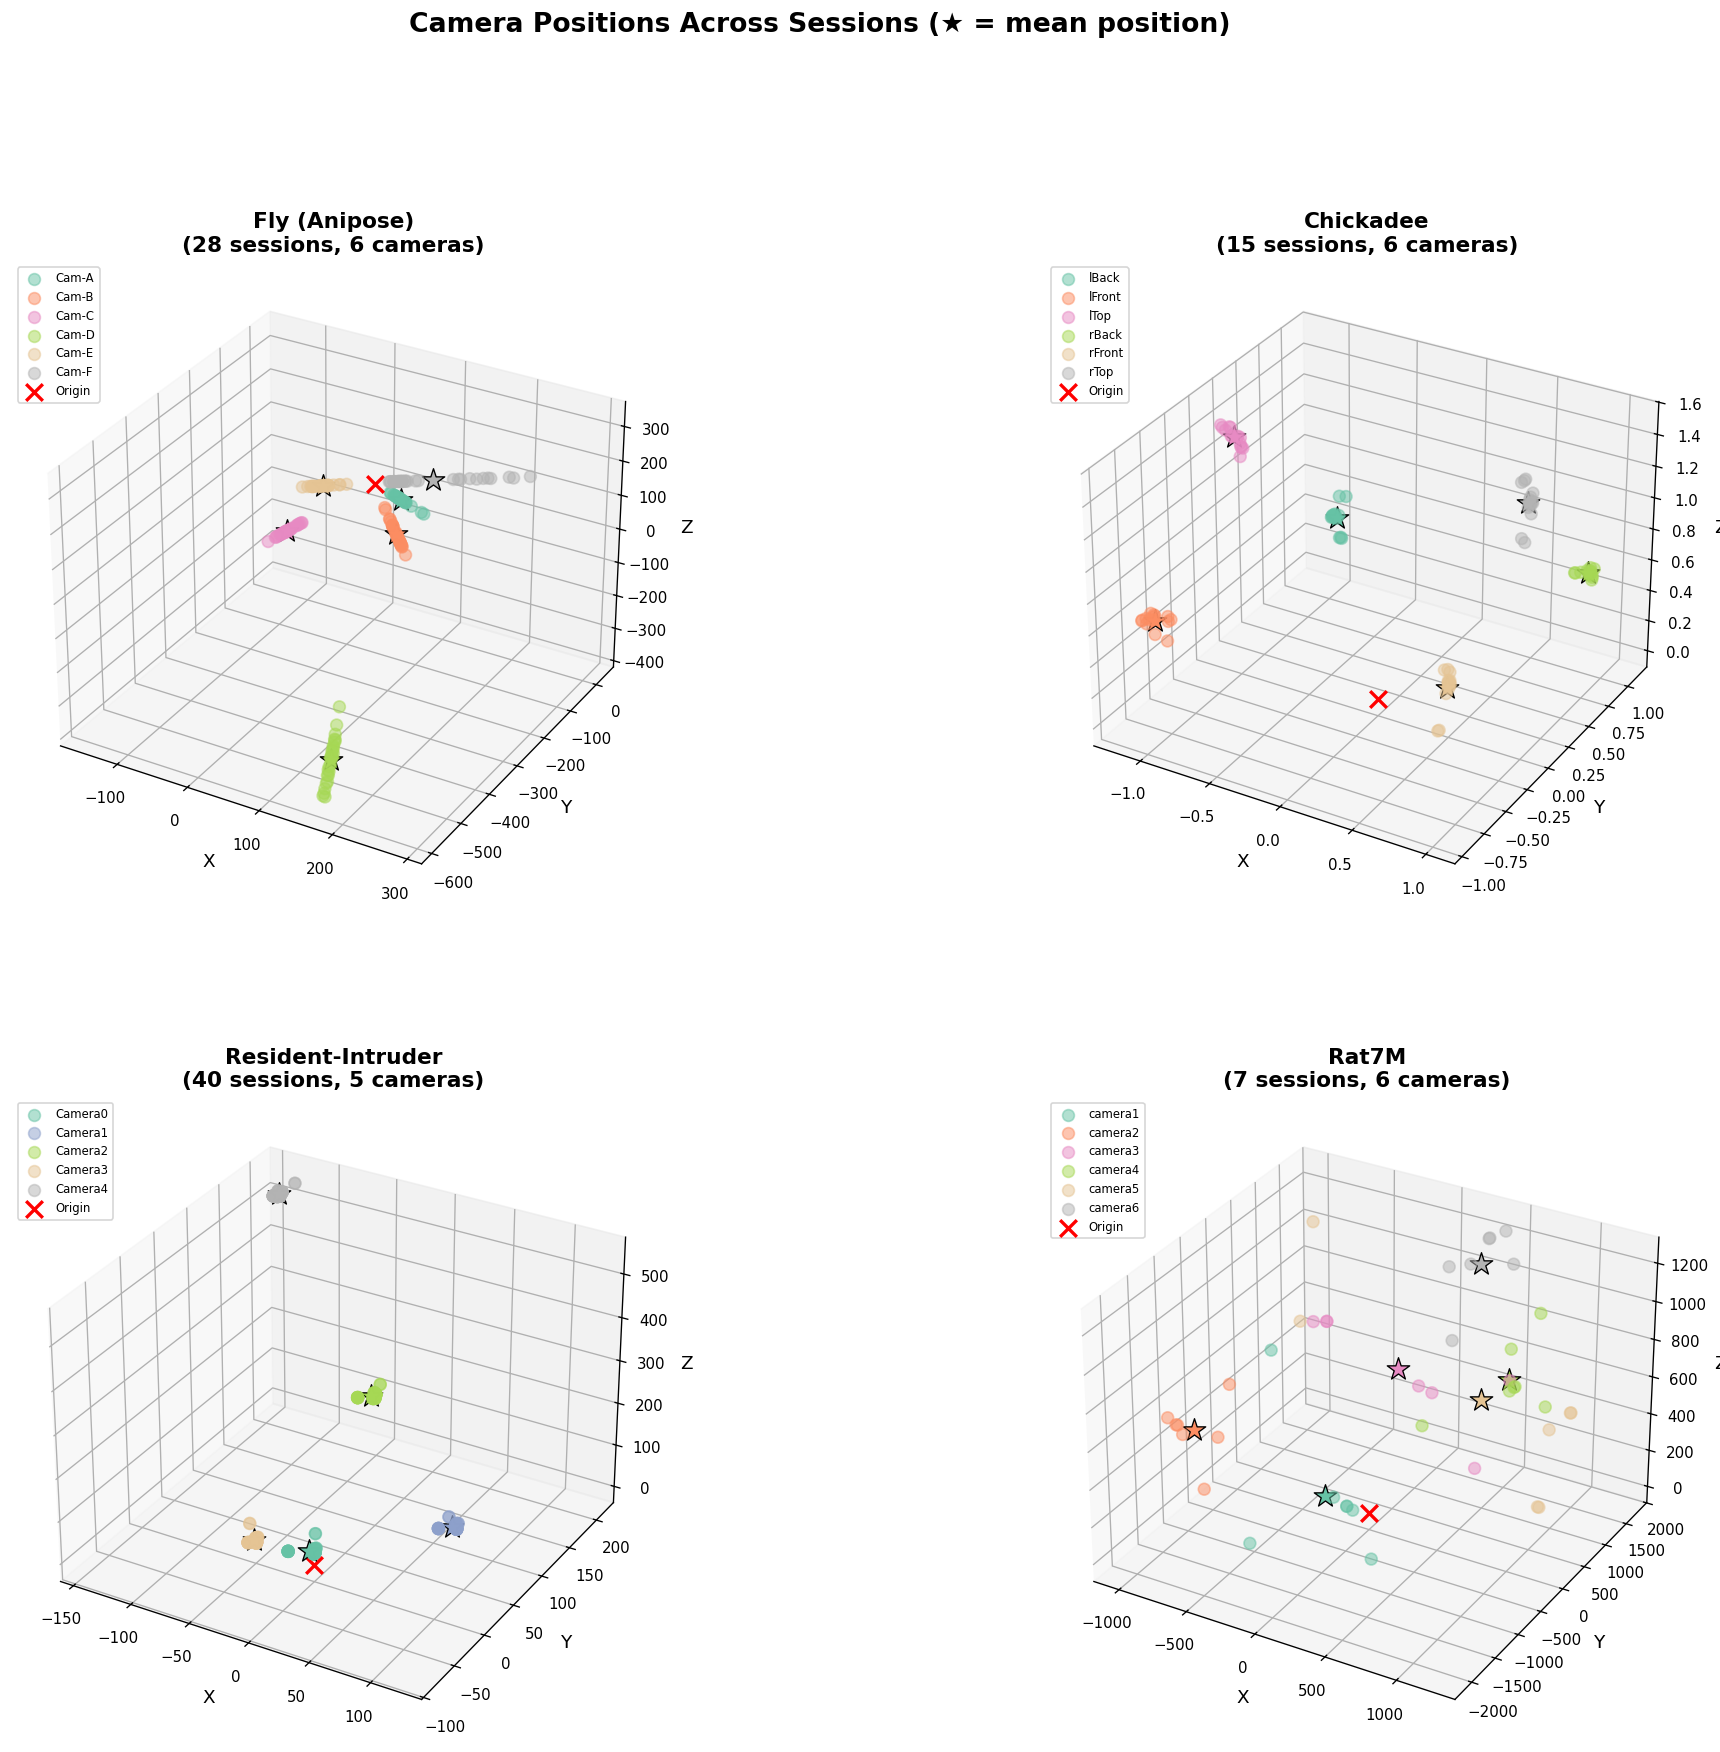

In [15]:
fig = plt.figure(figsize=(20, 16))
gs = gridspec.GridSpec(2, 2, hspace=0.30, wspace=0.25)

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    n_cams = len(cam_names)
    cam_cmap = plt.cm.Set2 if n_cams <= 8 else plt.cm.tab20
    cam_colors = [cam_cmap(i / max(n_cams - 1, 1)) for i in range(n_cams)]

    ax = fig.add_subplot(gs[idx], projection='3d')

    for j, cam_name in enumerate(cam_names):
        positions = np.array([
            params[s]['cameras'][cam_name]['camera_position']
            for s in sessions if cam_name in params[s]['cameras']
        ])
        ax.scatter(
            positions[:, 0], positions[:, 1], positions[:, 2],
            c=[cam_colors[j]], s=50, alpha=0.5, label=cam_name,
        )
        mean_pos = positions.mean(axis=0)
        ax.scatter(
            mean_pos[0], mean_pos[1], mean_pos[2],
            c=[cam_colors[j]], s=200, marker='*', edgecolors='k', linewidths=0.8,
        )

    ax.scatter(0, 0, 0, c='red', s=100, marker='x', linewidths=2, label='Origin')
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
    ax.set_title(f"{ds_cfg['display_name']}\n({len(sessions)} sessions, {n_cams} cameras)",
                 fontsize=13, fontweight='bold')
    ax.legend(fontsize=7, loc='upper left', framealpha=0.8)

fig.suptitle('Camera Positions Across Sessions (\u2605 = mean position)',
             fontsize=16, fontweight='bold', y=1.01)
# plt.savefig(f'{save_path}/camera_positions_3d_all_datasets.pdf', bbox_inches='tight')
plt.show()

## Camera Position Variability: Per-Axis Standard Deviation

Grouped bar chart showing how much each camera's position varies (std) along X, Y, Z across sessions.

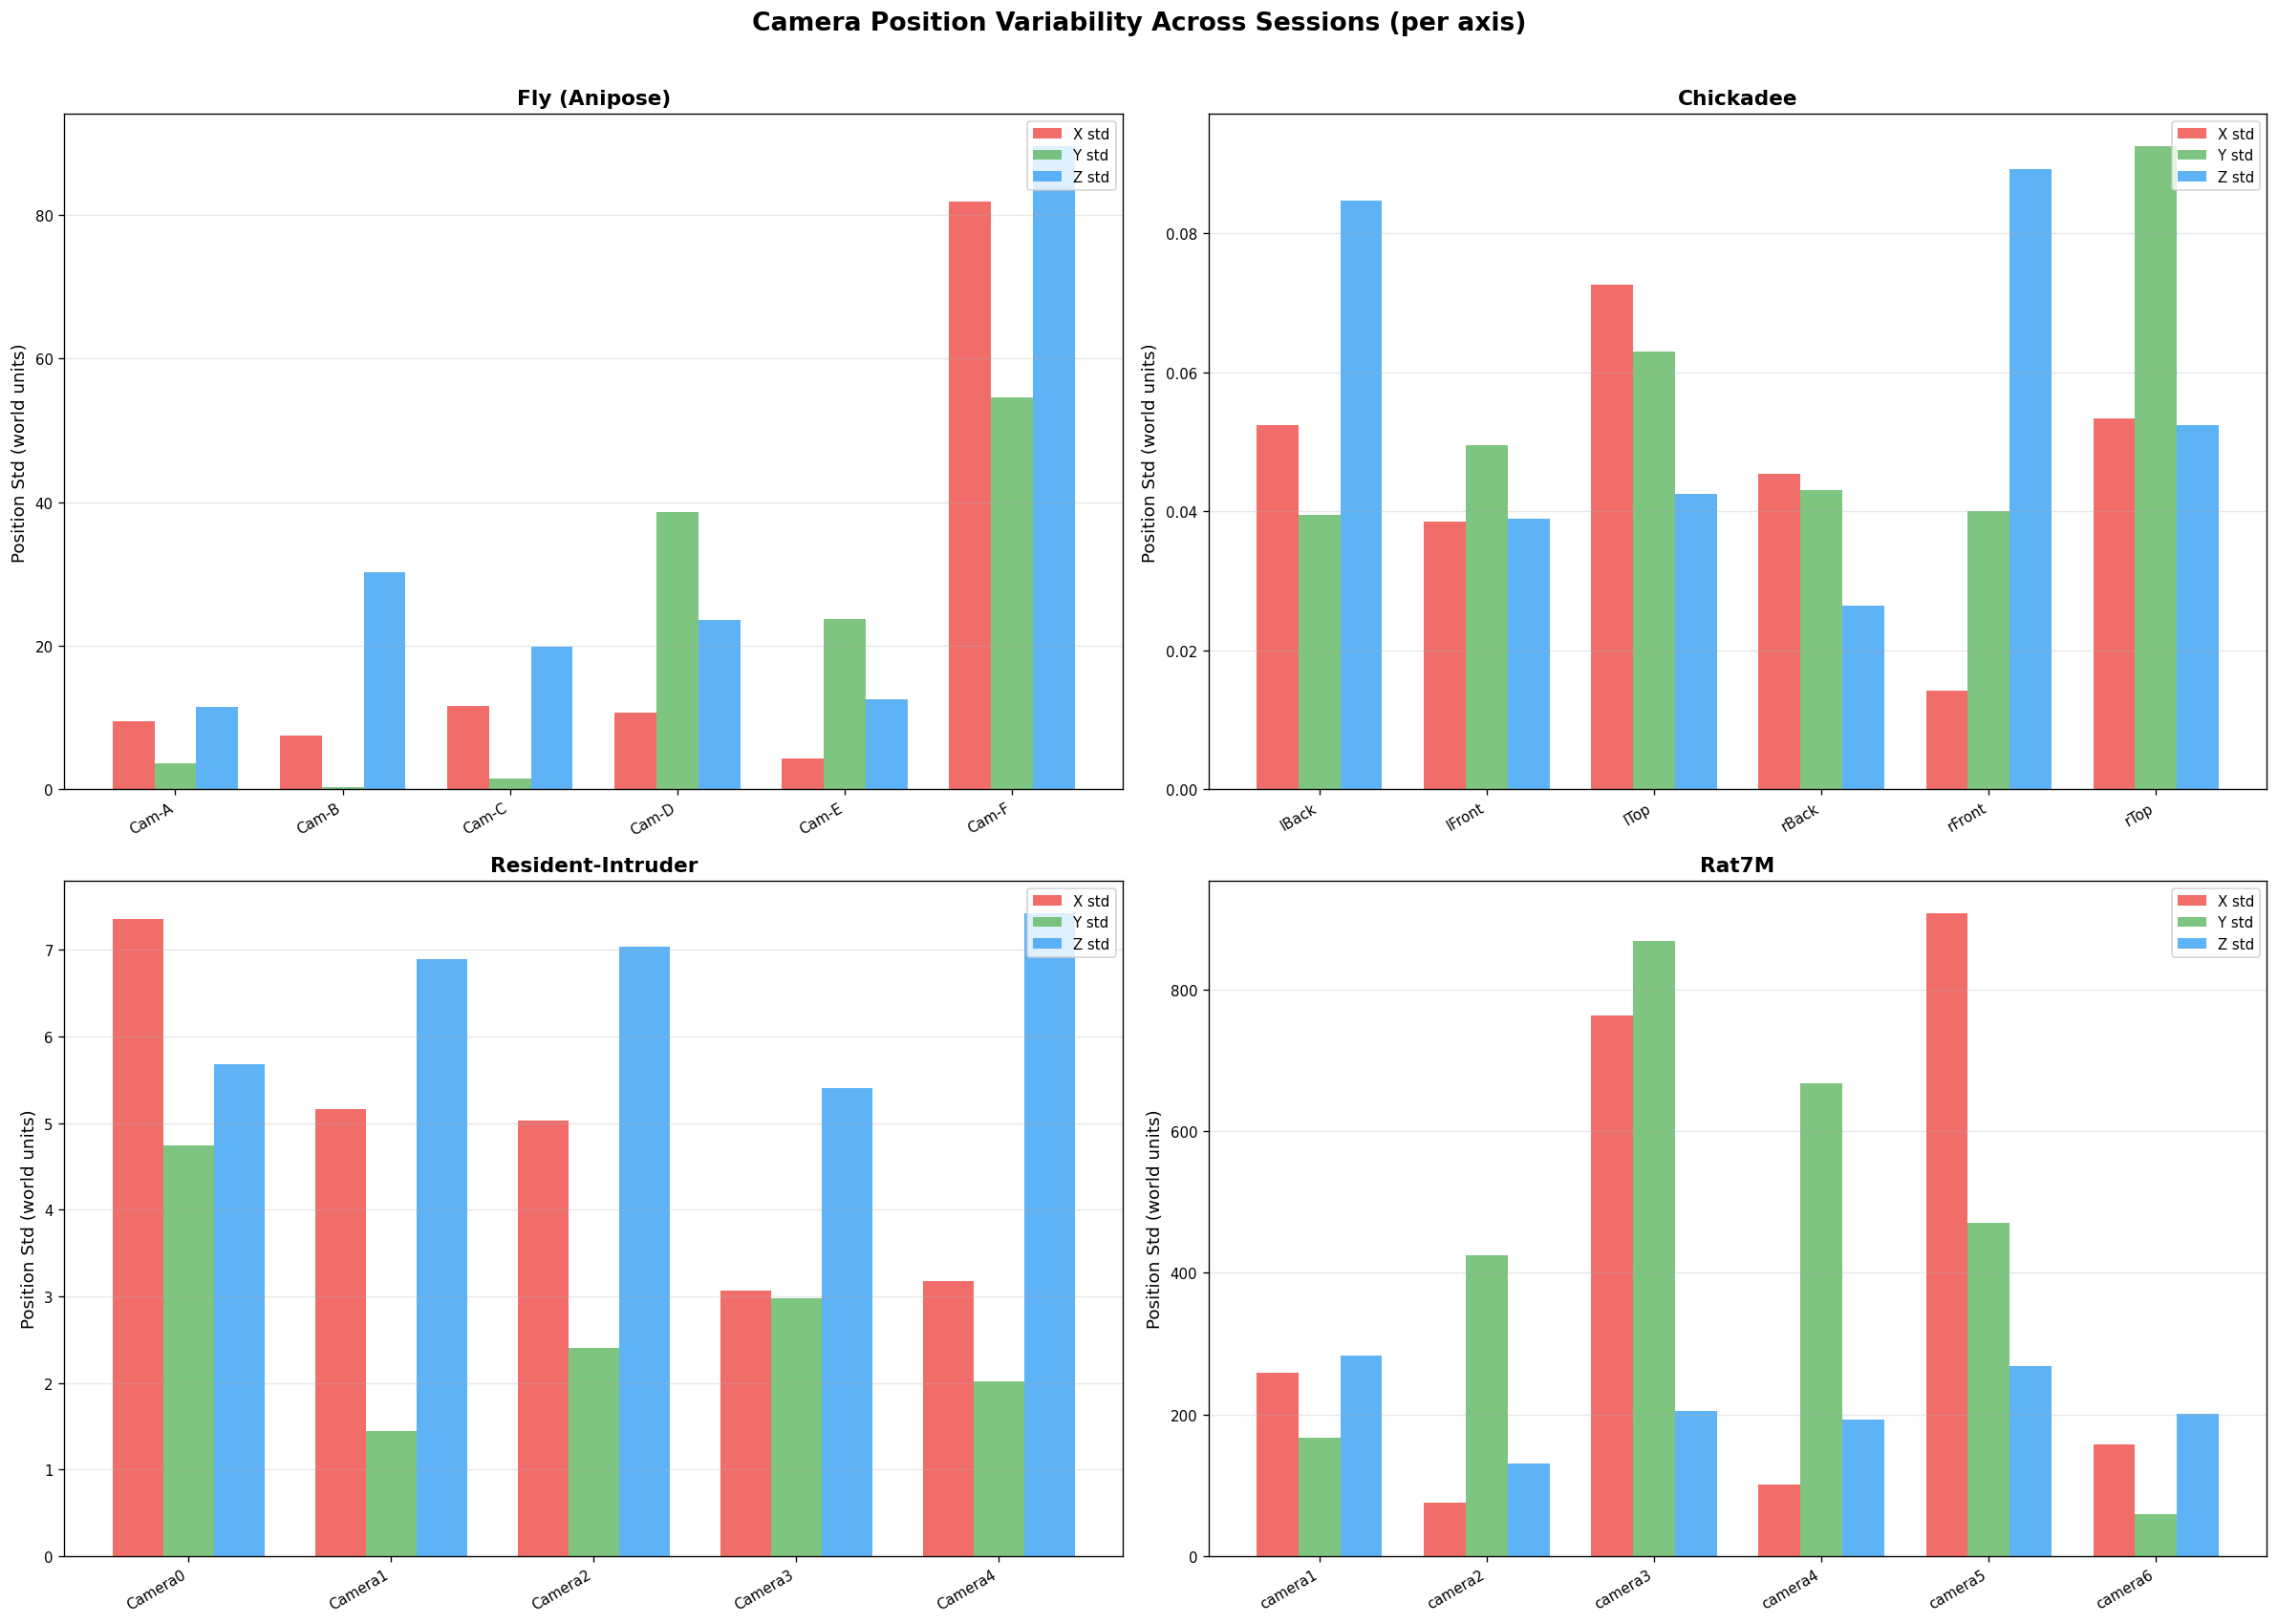

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
axes = axes.ravel()

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    ax = axes[idx]
    metrics = all_metrics[ds_name]
    cam_names = metrics['camera'].tolist()
    n_cams = len(cam_names)
    x = np.arange(n_cams)
    width = 0.25

    bars_x = ax.bar(x - width, metrics['pos_x_std'], width, label='X std', color='#EF5350', alpha=0.85)
    bars_y = ax.bar(x, metrics['pos_y_std'], width, label='Y std', color='#66BB6A', alpha=0.85)
    bars_z = ax.bar(x + width, metrics['pos_z_std'], width, label='Z std', color='#42A5F5', alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(cam_names, rotation=30, ha='right')
    ax.set_ylabel('Position Std (world units)')
    ax.set_title(f"{ds_cfg['display_name']}", fontsize=13, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Camera Position Variability Across Sessions (per axis)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig('camera_position_variability_per_axis.png', bbox_inches='tight')
plt.show()

## Reference for experimentalists: "What if my camera moves 1–2 cm or droops 5°?"

The plots below show **observed variability** in camera position and orientation across sessions in each dataset. Use them to judge whether a given change is "OK":

- **Position spread (cm)**: Boxplots of **position spread** (max − min across sessions) along X, Y, Z for each dataset. Each box shows the distribution of per-camera spreads. If your setup's shift (e.g. 1–2 cm) is **within or below** these ranges, it is comparable to what these pipelines already tolerate. Reference lines at 1 cm and 2 cm are drawn for comparison.
- **Angle (degrees)**: Boxplots of orientation (total rotation and Euler X/Y/Z). If your droop (e.g. 5°) is **within the typical spread**, it is in line with existing variability. A reference line at 5° is drawn.

*Calibration world units are assumed to be mm; positions are converted to cm for the position plot.*

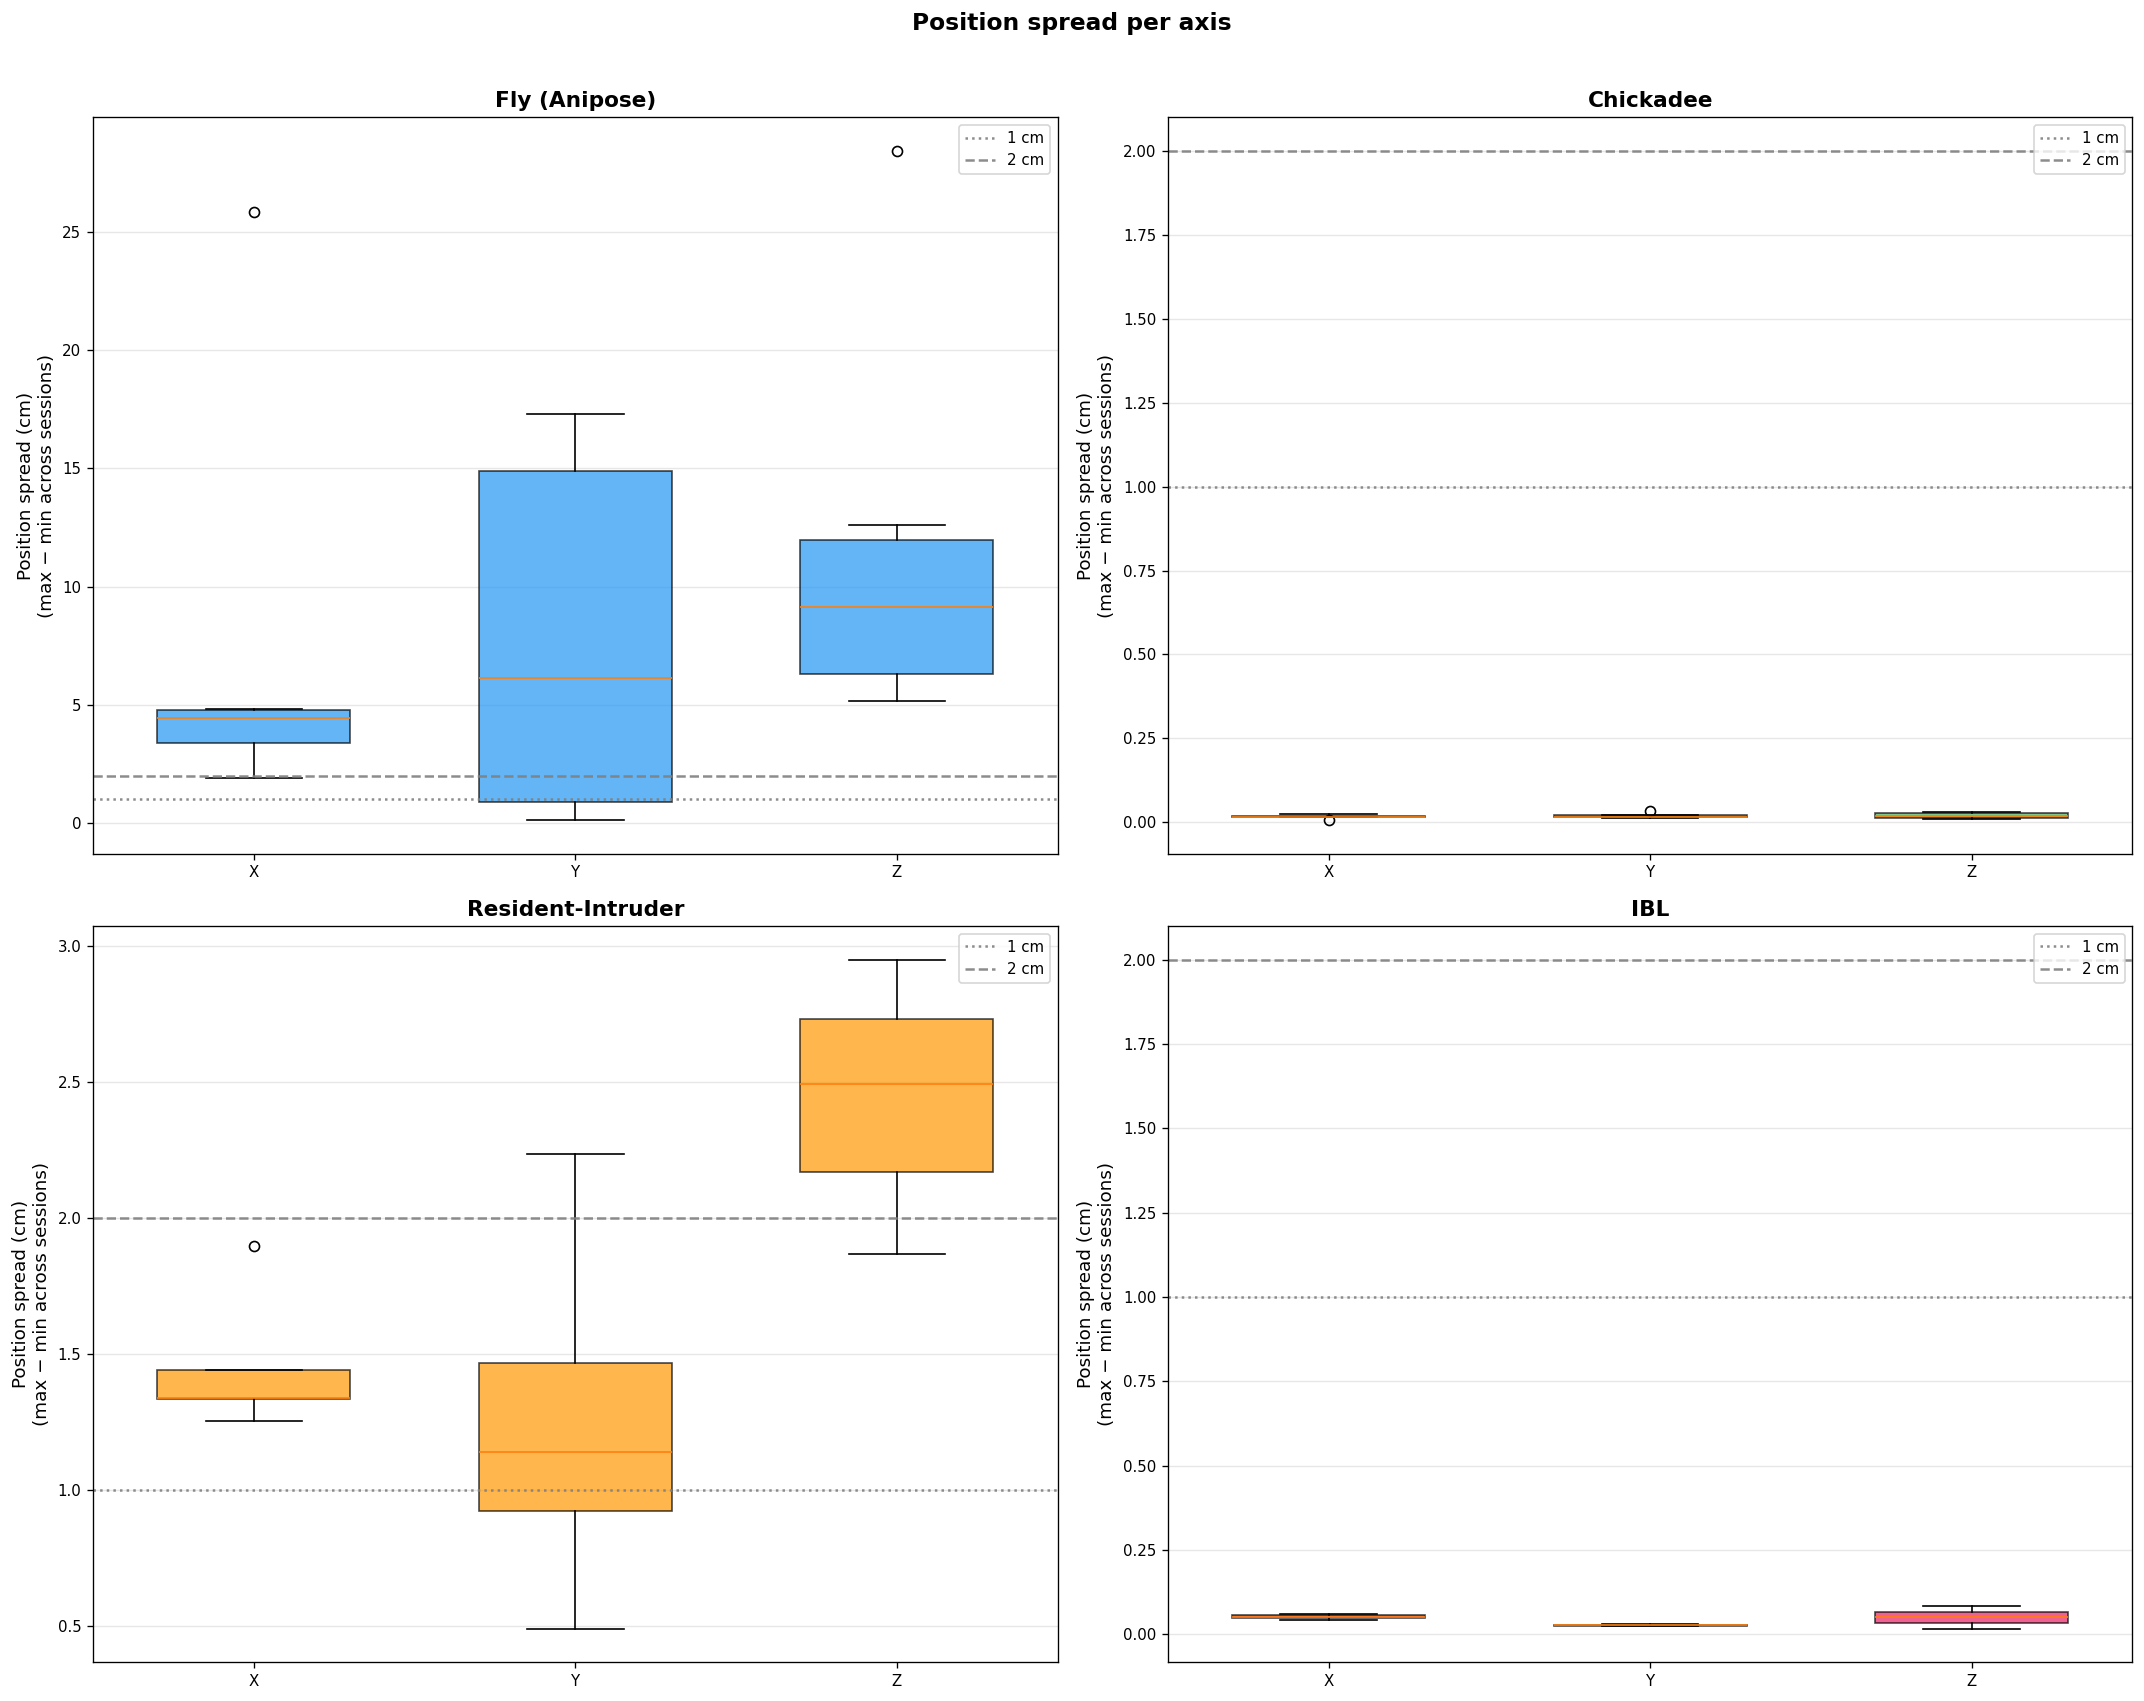

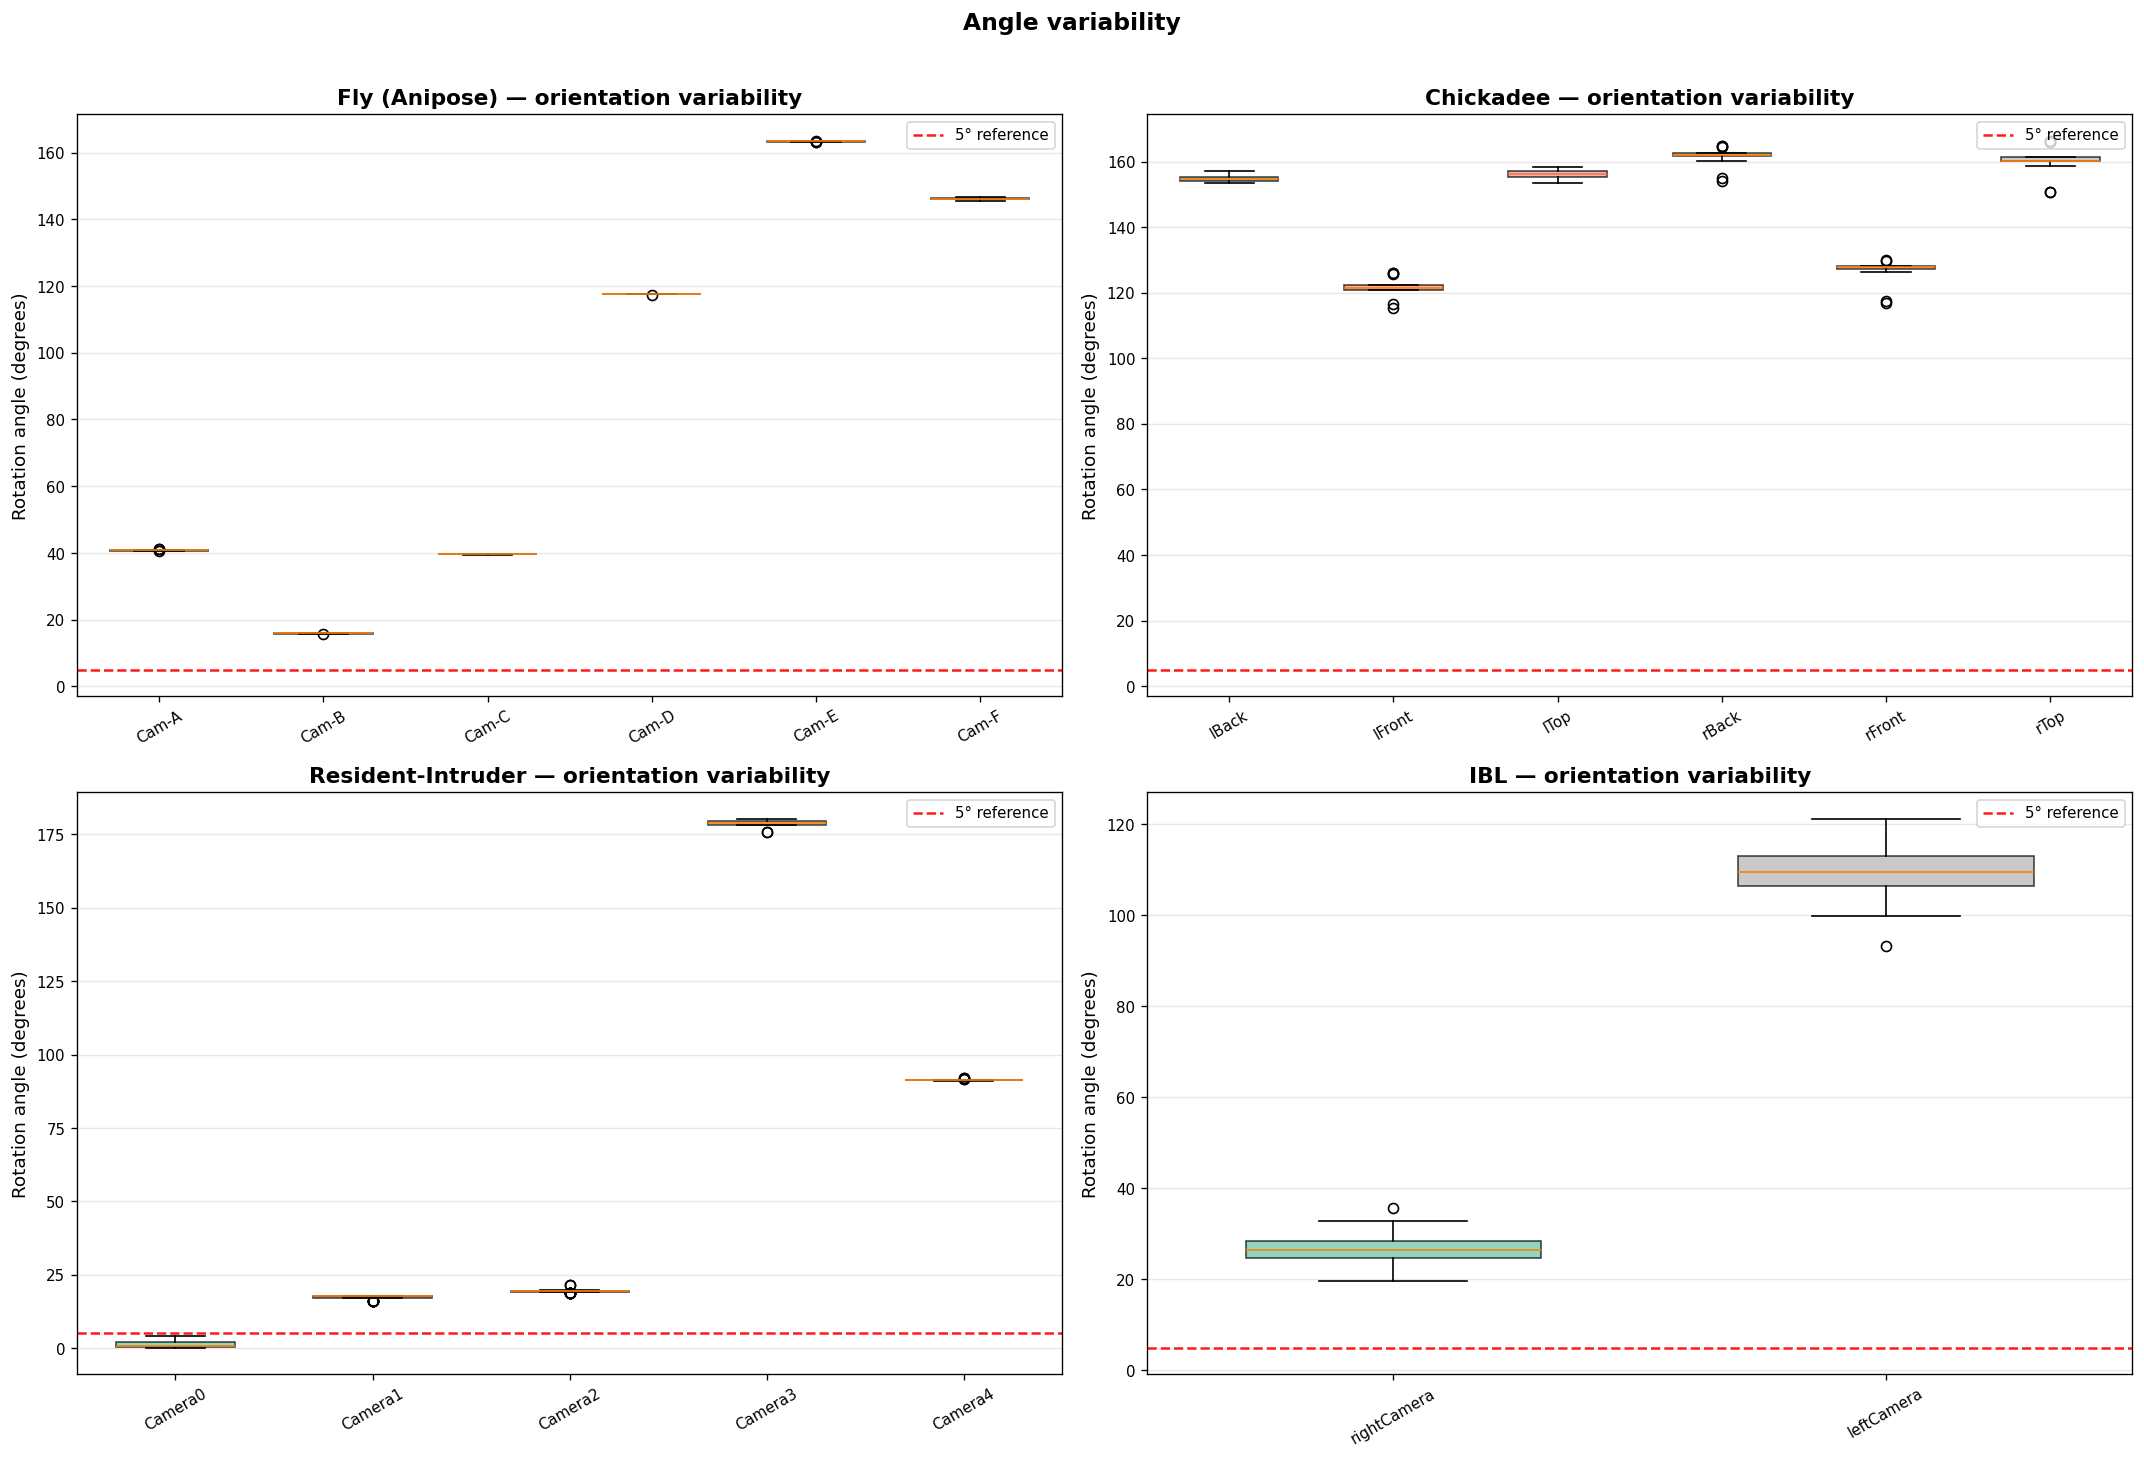

In [ ]:
# Position scale: calibration is typically in mm -> convert to cm for "1-2 cm" comparison
POSITION_SCALE_CM = 0.1  # 1 unit = 1 mm -> 0.1 cm; set to 1.0 if already in cm

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.ravel()

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    ax = axes[idx]
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())

    # Position spread (max − min) in cm per axis across cameras — directly comparable to "1–2 cm move"
    spread_x, spread_y, spread_z = [], [], []
    for cam_name in cam_names:
        vals = []
        for s in sessions:
            cam = params[s]['cameras'].get(cam_name)
            if cam is not None:
                vals.append(cam['camera_position'] * POSITION_SCALE_CM)
        vals = np.array(vals) if vals else np.zeros((0, 3))
        if len(vals) > 0:
            spread_x.append(np.ptp(vals[:, 0]))
            spread_y.append(np.ptp(vals[:, 1]))
            spread_z.append(np.ptp(vals[:, 2]))
        else:
            spread_x.append(0); spread_y.append(0); spread_z.append(0)

    bp = ax.boxplot([spread_x, spread_y, spread_z], labels=['X', 'Y', 'Z'], patch_artist=True, widths=0.6)
    for patch in bp['boxes']:
        patch.set_facecolor(ds_cfg['color'])
        patch.set_alpha(0.7)
    ax.axhline(1, color='gray', linestyle=':', alpha=0.9, linewidth=1.5, label='1 cm')
    ax.axhline(2, color='gray', linestyle='--', alpha=0.9, linewidth=1.5, label='2 cm')
    ax.set_ylabel('Position spread (cm)\n(max − min across sessions)')
    ax.set_title(f"{ds_cfg['display_name']}", fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Position spread per axis',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Angle boxplots: compare "5° droop" to observed orientation variability
fig2, axes2 = plt.subplots(2, 2, figsize=(18, 12))
axes2 = axes2.ravel()

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    ax = axes2[idx]
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    n_cams = len(cam_names)

    rot_data = []
    for cam_name in cam_names:
        angles_deg = []
        for s in sessions:
            cam = params[s]['cameras'].get(cam_name)
            if cam is not None:
                angle = np.linalg.norm(cam['rotation_vec']) * 180.0 / np.pi
                angles_deg.append(angle)
        rot_data.append(angles_deg)

    bp = ax.boxplot(rot_data, labels=cam_names, patch_artist=True, widths=0.6)
    cam_cmap = plt.cm.Set2 if n_cams <= 8 else plt.cm.tab20
    for pi, patch in enumerate(bp['boxes']):
        patch.set_facecolor(cam_cmap(pi / max(n_cams - 1, 1)))
        patch.set_alpha(0.7)
    ax.axhline(5, color='red', linestyle='--', linewidth=1.5, alpha=0.9, label='5° reference')
    ax.set_ylabel('Rotation angle (degrees)')
    ax.set_title(f"{ds_cfg['display_name']} — orientation variability", fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

fig2.suptitle('Angle variability',
              fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

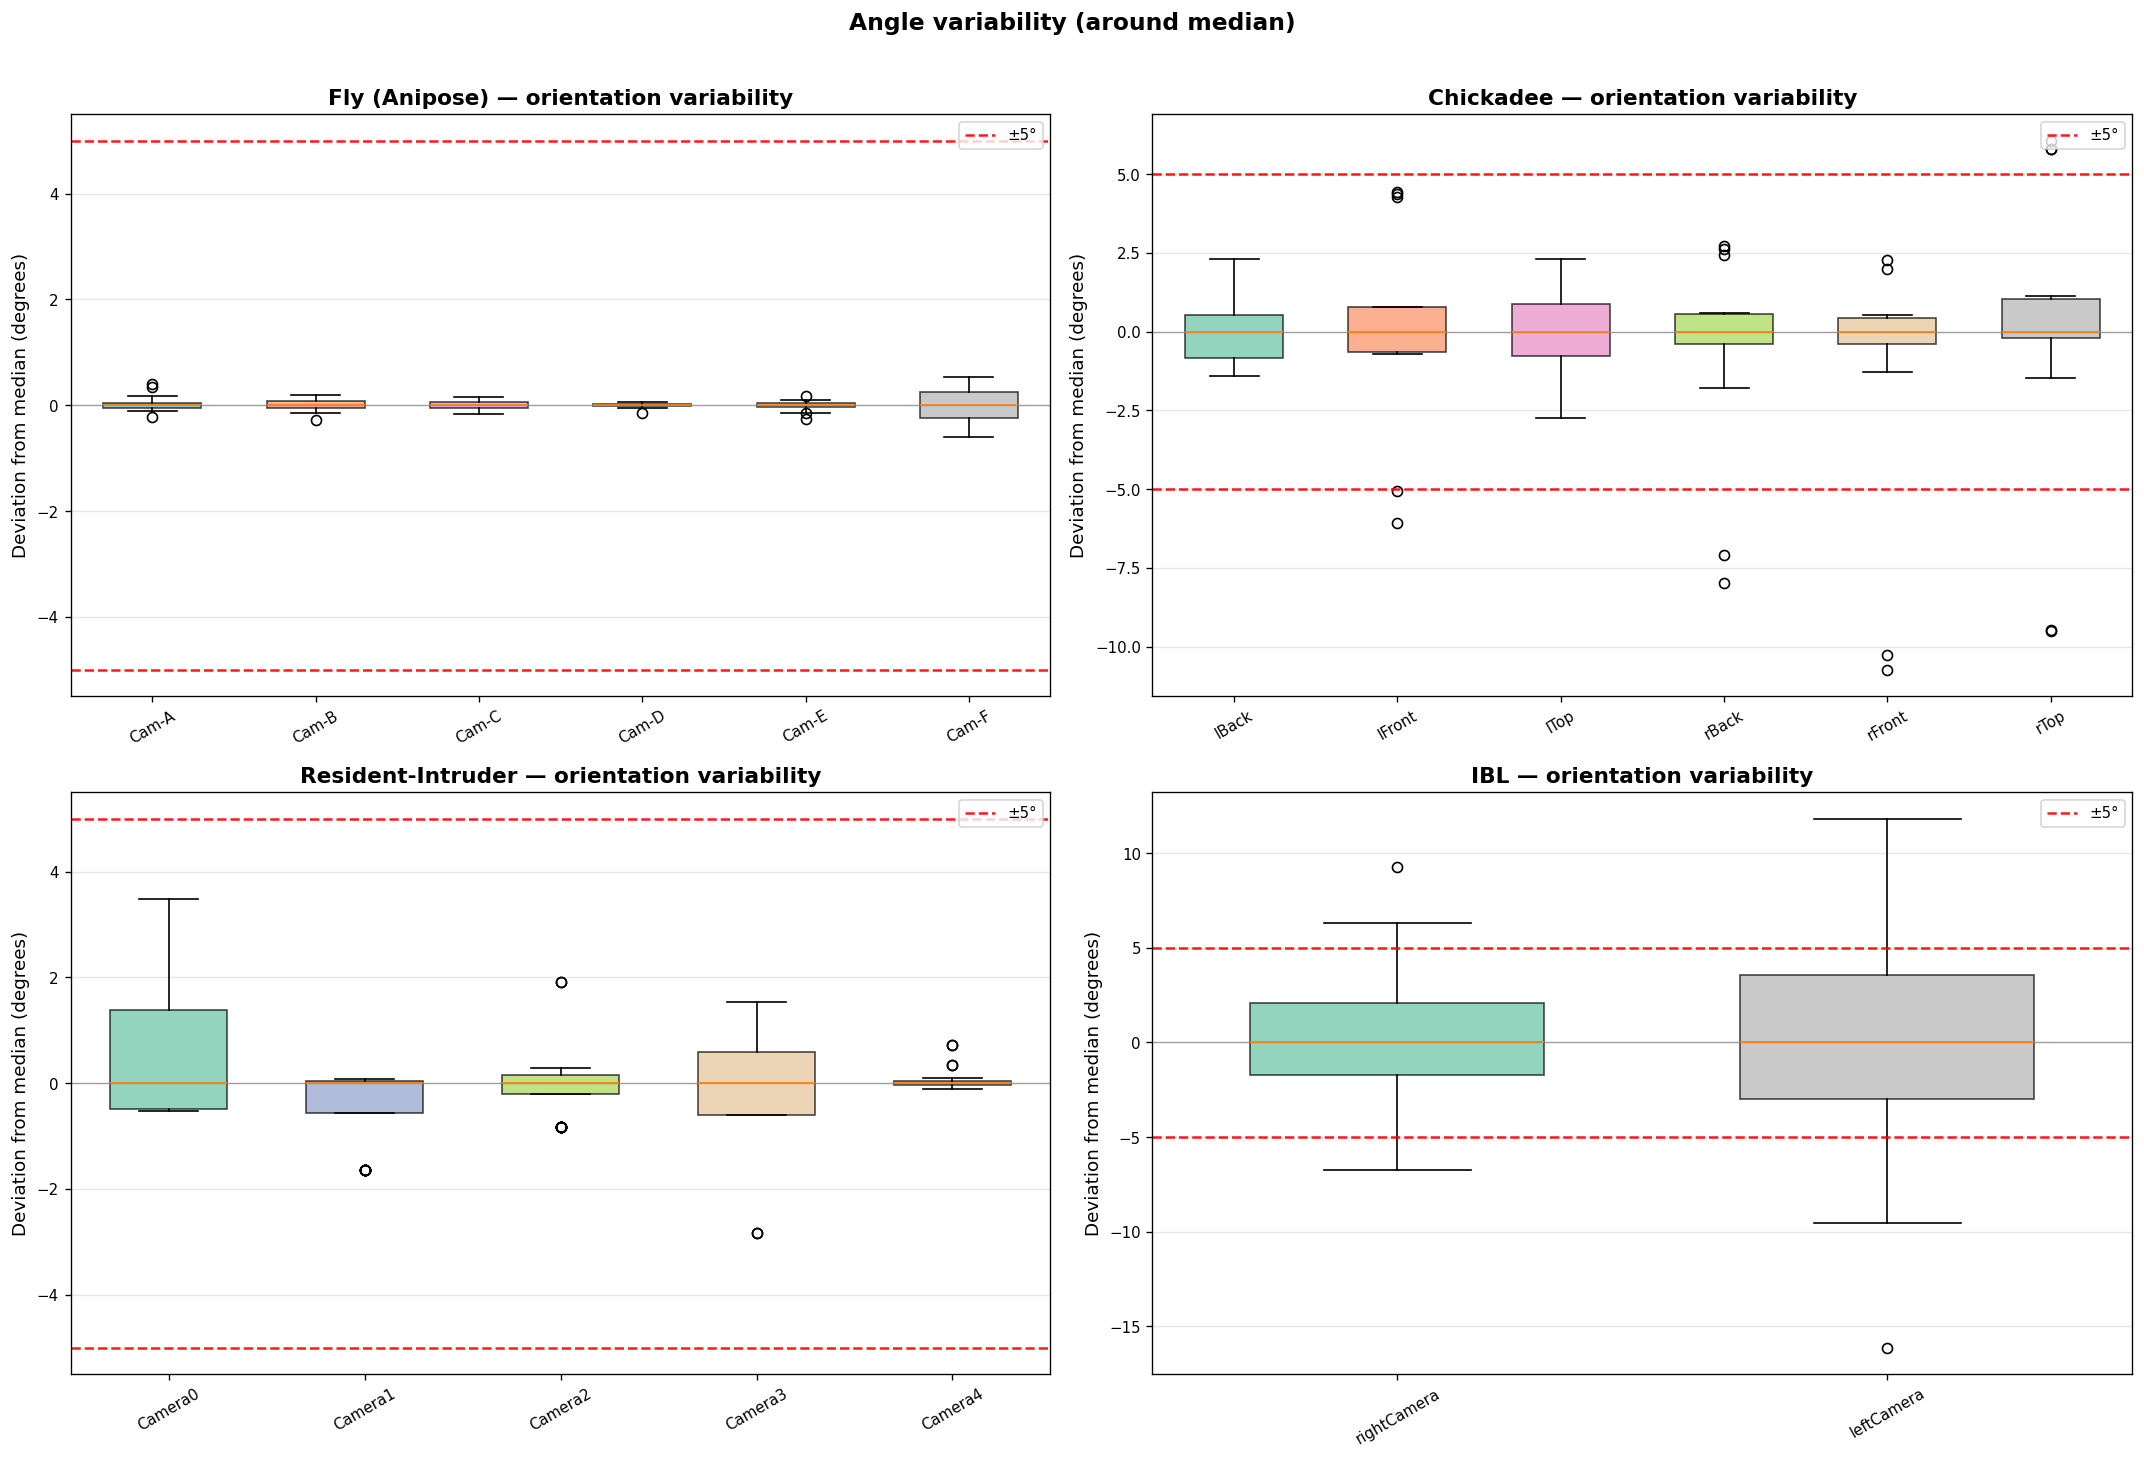

In [ ]:
# Angle boxplots: variability around median (so you can say "~5° spread across sessions")
fig2, axes2 = plt.subplots(2, 2, figsize=(18, 12))
axes2 = axes2.ravel()

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    ax = axes2[idx]
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    n_cams = len(cam_names)

    rot_data = []
    for cam_name in cam_names:
        angles_deg = []
        for s in sessions:
            cam = params[s]['cameras'].get(cam_name)
            if cam is not None:
                angle = np.linalg.norm(cam['rotation_vec']) * 180.0 / np.pi
                angles_deg.append(angle)
        angles_deg = np.array(angles_deg)
        # Center on median so boxplot shows spread ("~5° across sessions")
        centered = angles_deg - np.median(angles_deg) if len(angles_deg) > 0 else angles_deg
        rot_data.append(centered.tolist() if len(angles_deg) > 0 else [])

    bp = ax.boxplot(rot_data, labels=cam_names, patch_artist=True, widths=0.6)
    cam_cmap = plt.cm.Set2 if n_cams <= 8 else plt.cm.tab20
    for pi, patch in enumerate(bp['boxes']):
        patch.set_facecolor(cam_cmap(pi / max(n_cams - 1, 1)))
        patch.set_alpha(0.7)
    ax.axhline(0, color='gray', linestyle='-', linewidth=0.8, alpha=0.7)
    ax.axhline(5, color='red', linestyle='--', linewidth=1.5, alpha=0.9, label='±5°')
    ax.axhline(-5, color='red', linestyle='--', linewidth=1.5, alpha=0.9)
    ax.set_ylabel('Deviation from median (degrees)')
    ax.set_title(f"{ds_cfg['display_name']} — orientation variability", fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

fig2.suptitle('Angle variability (around median)',
              fontsize=14, fontweight='bold', y=1.01)


plt.tight_layout()
plt.savefig(f'{save_path}/angle_variability_around_median.pdf', bbox_inches='tight')
plt.show()

## Camera Distance from Origin Across Sessions

Each line is one camera. Variation in the line height across the x-axis (sessions) indicates how much the camera-to-origin distance changes between sessions.

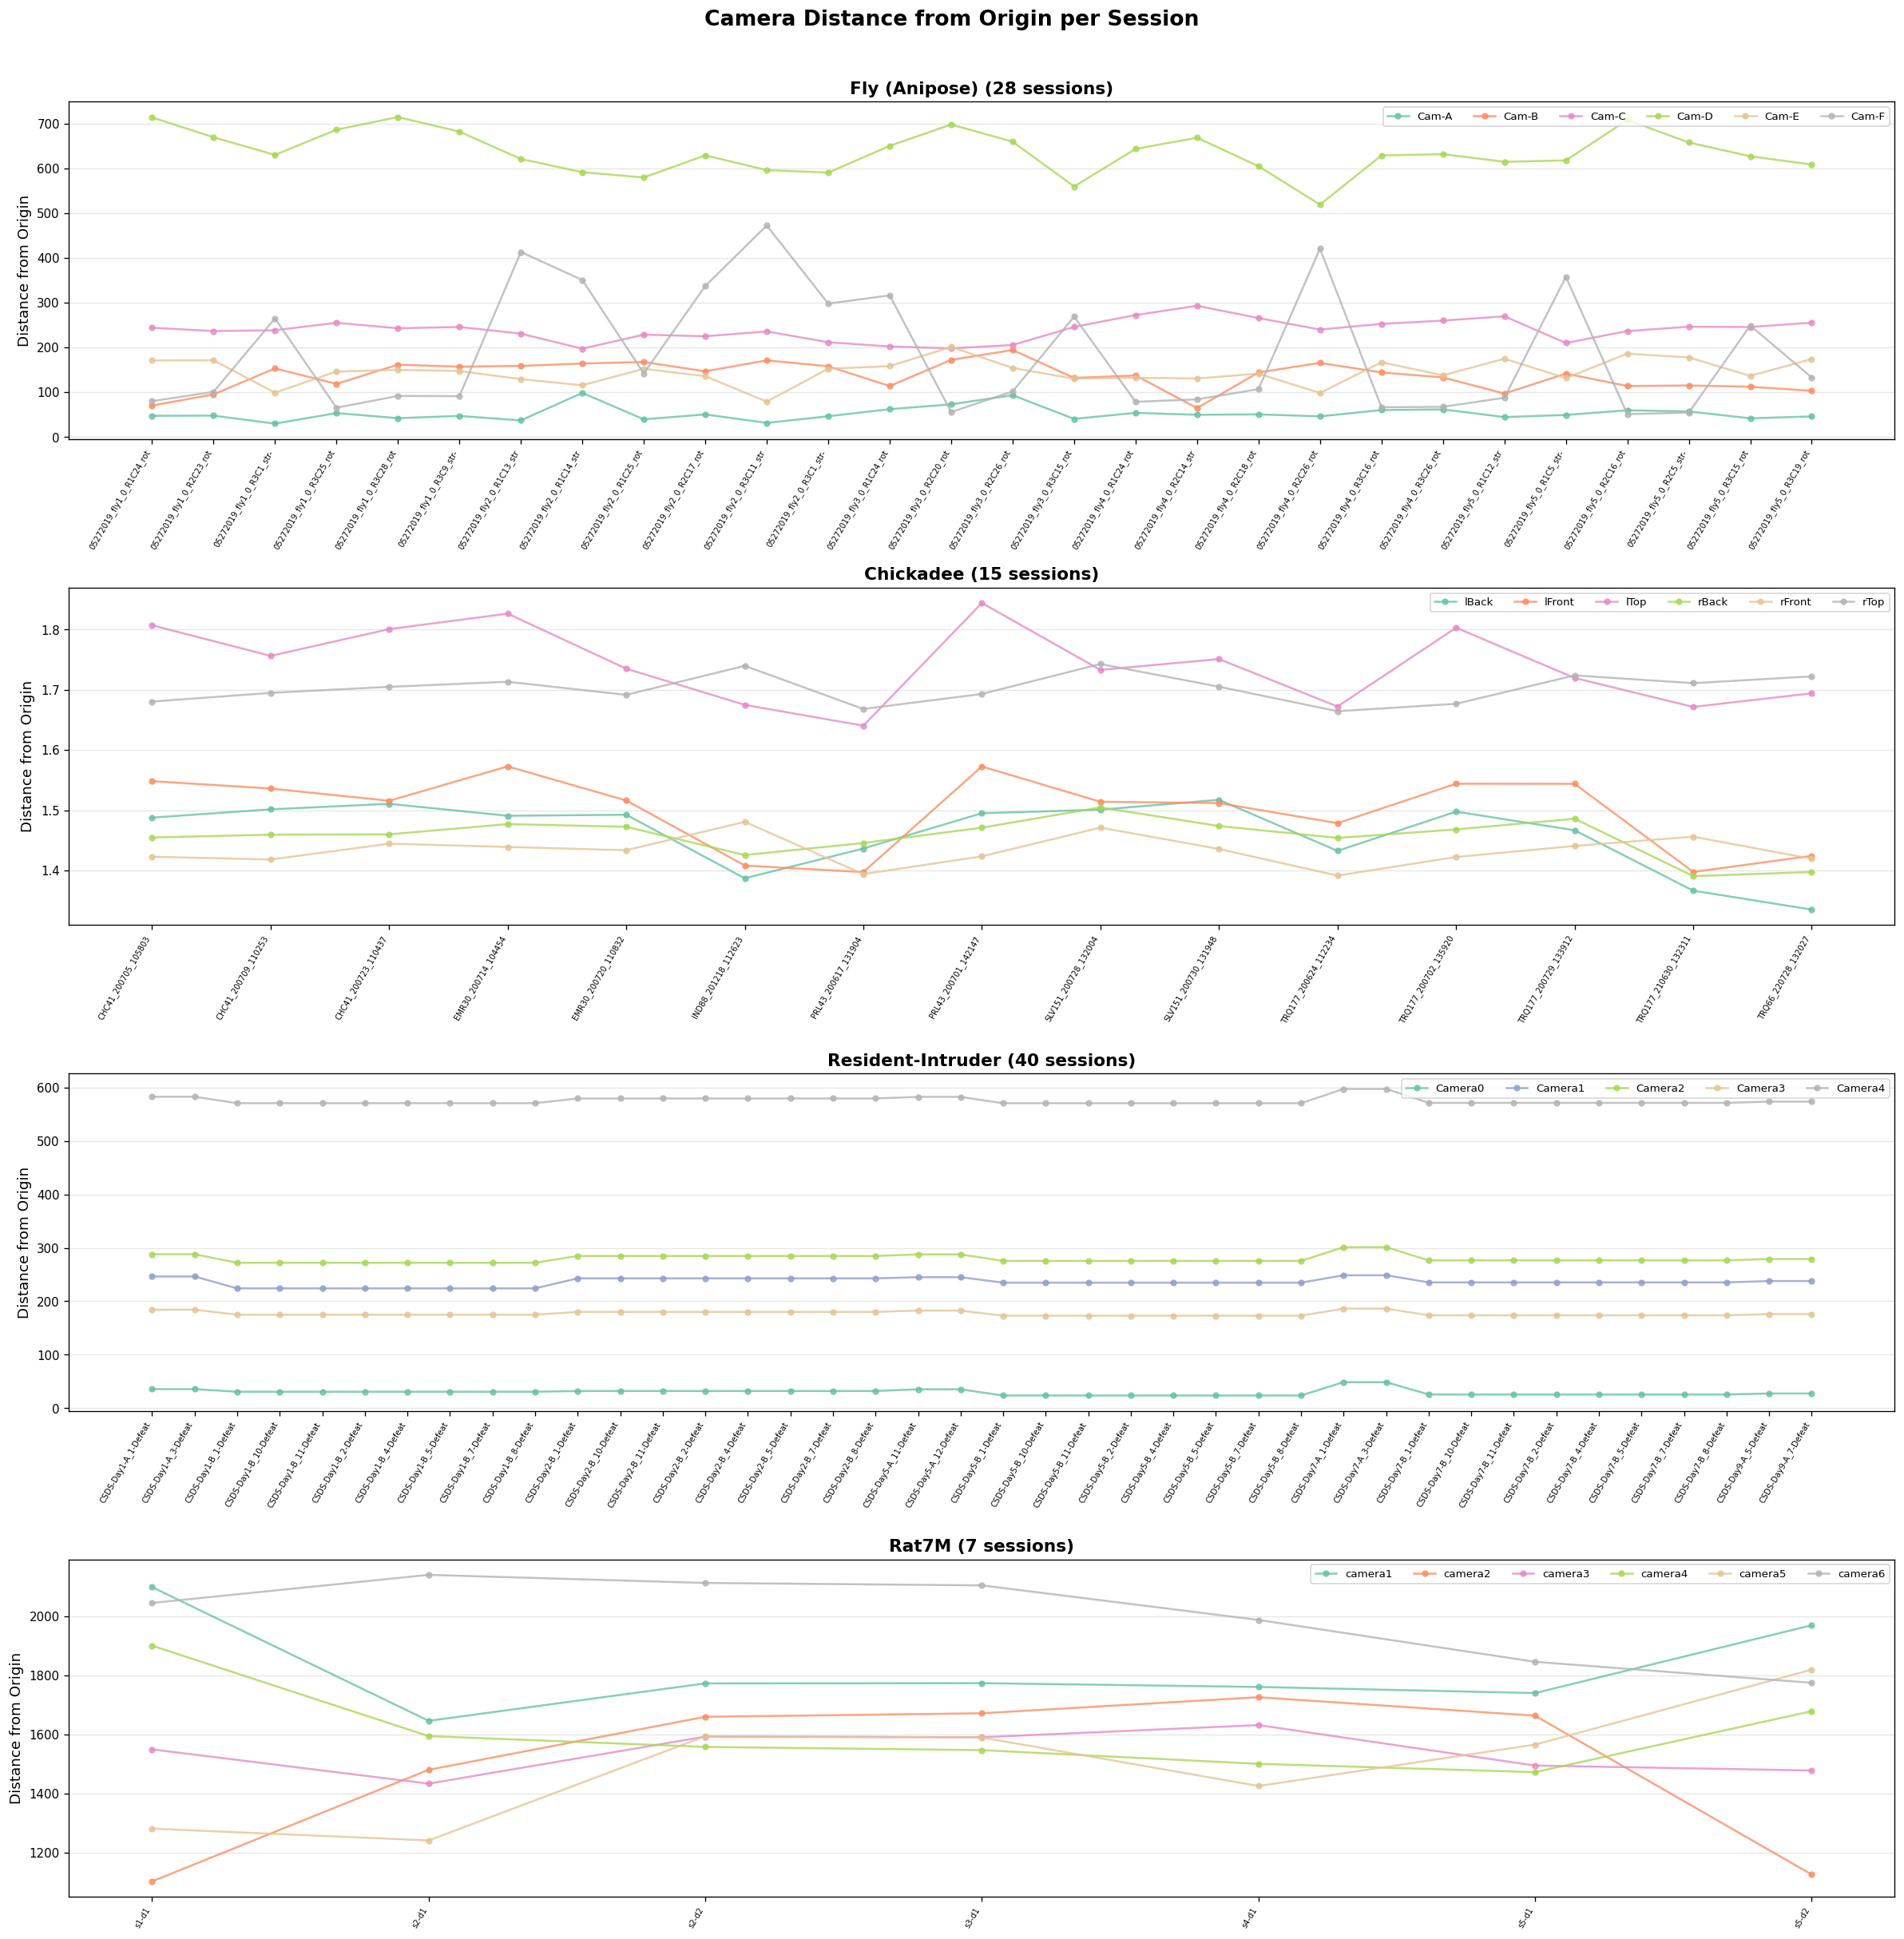

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(20, 20))

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    ax = axes[idx]
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    n_cams = len(cam_names)
    cam_cmap = plt.cm.Set2 if n_cams <= 8 else plt.cm.tab20
    cam_colors = [cam_cmap(i / max(n_cams - 1, 1)) for i in range(n_cams)]

    for j, cam_name in enumerate(cam_names):
        dists = [
            params[s]['cameras'].get(cam_name, {}).get('distance_from_origin', np.nan)
            for s in sessions
        ]
        ax.plot(range(len(sessions)), dists, 'o-', label=cam_name,
                color=cam_colors[j], alpha=0.8, markersize=4, linewidth=1.5)

    ax.set_ylabel('Distance from Origin')
    ax.set_title(f"{ds_cfg['display_name']} ({len(sessions)} sessions)",
                 fontsize=13, fontweight='bold')
    ax.set_xticks(range(len(sessions)))
    short_labels = [s[:25] for s in sessions]
    ax.set_xticklabels(short_labels, rotation=60, ha='right', fontsize=6)
    ax.legend(fontsize=8, ncol=min(n_cams, 6), loc='upper right')
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Camera Distance from Origin per Session',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig('camera_distance_per_session.png', bbox_inches='tight')
plt.show()

## Focal Length Consistency Across Sessions

Box plots of focal length distributions per camera, per dataset. Tight boxes indicate consistent intrinsics; wide boxes indicate re-calibration drift.

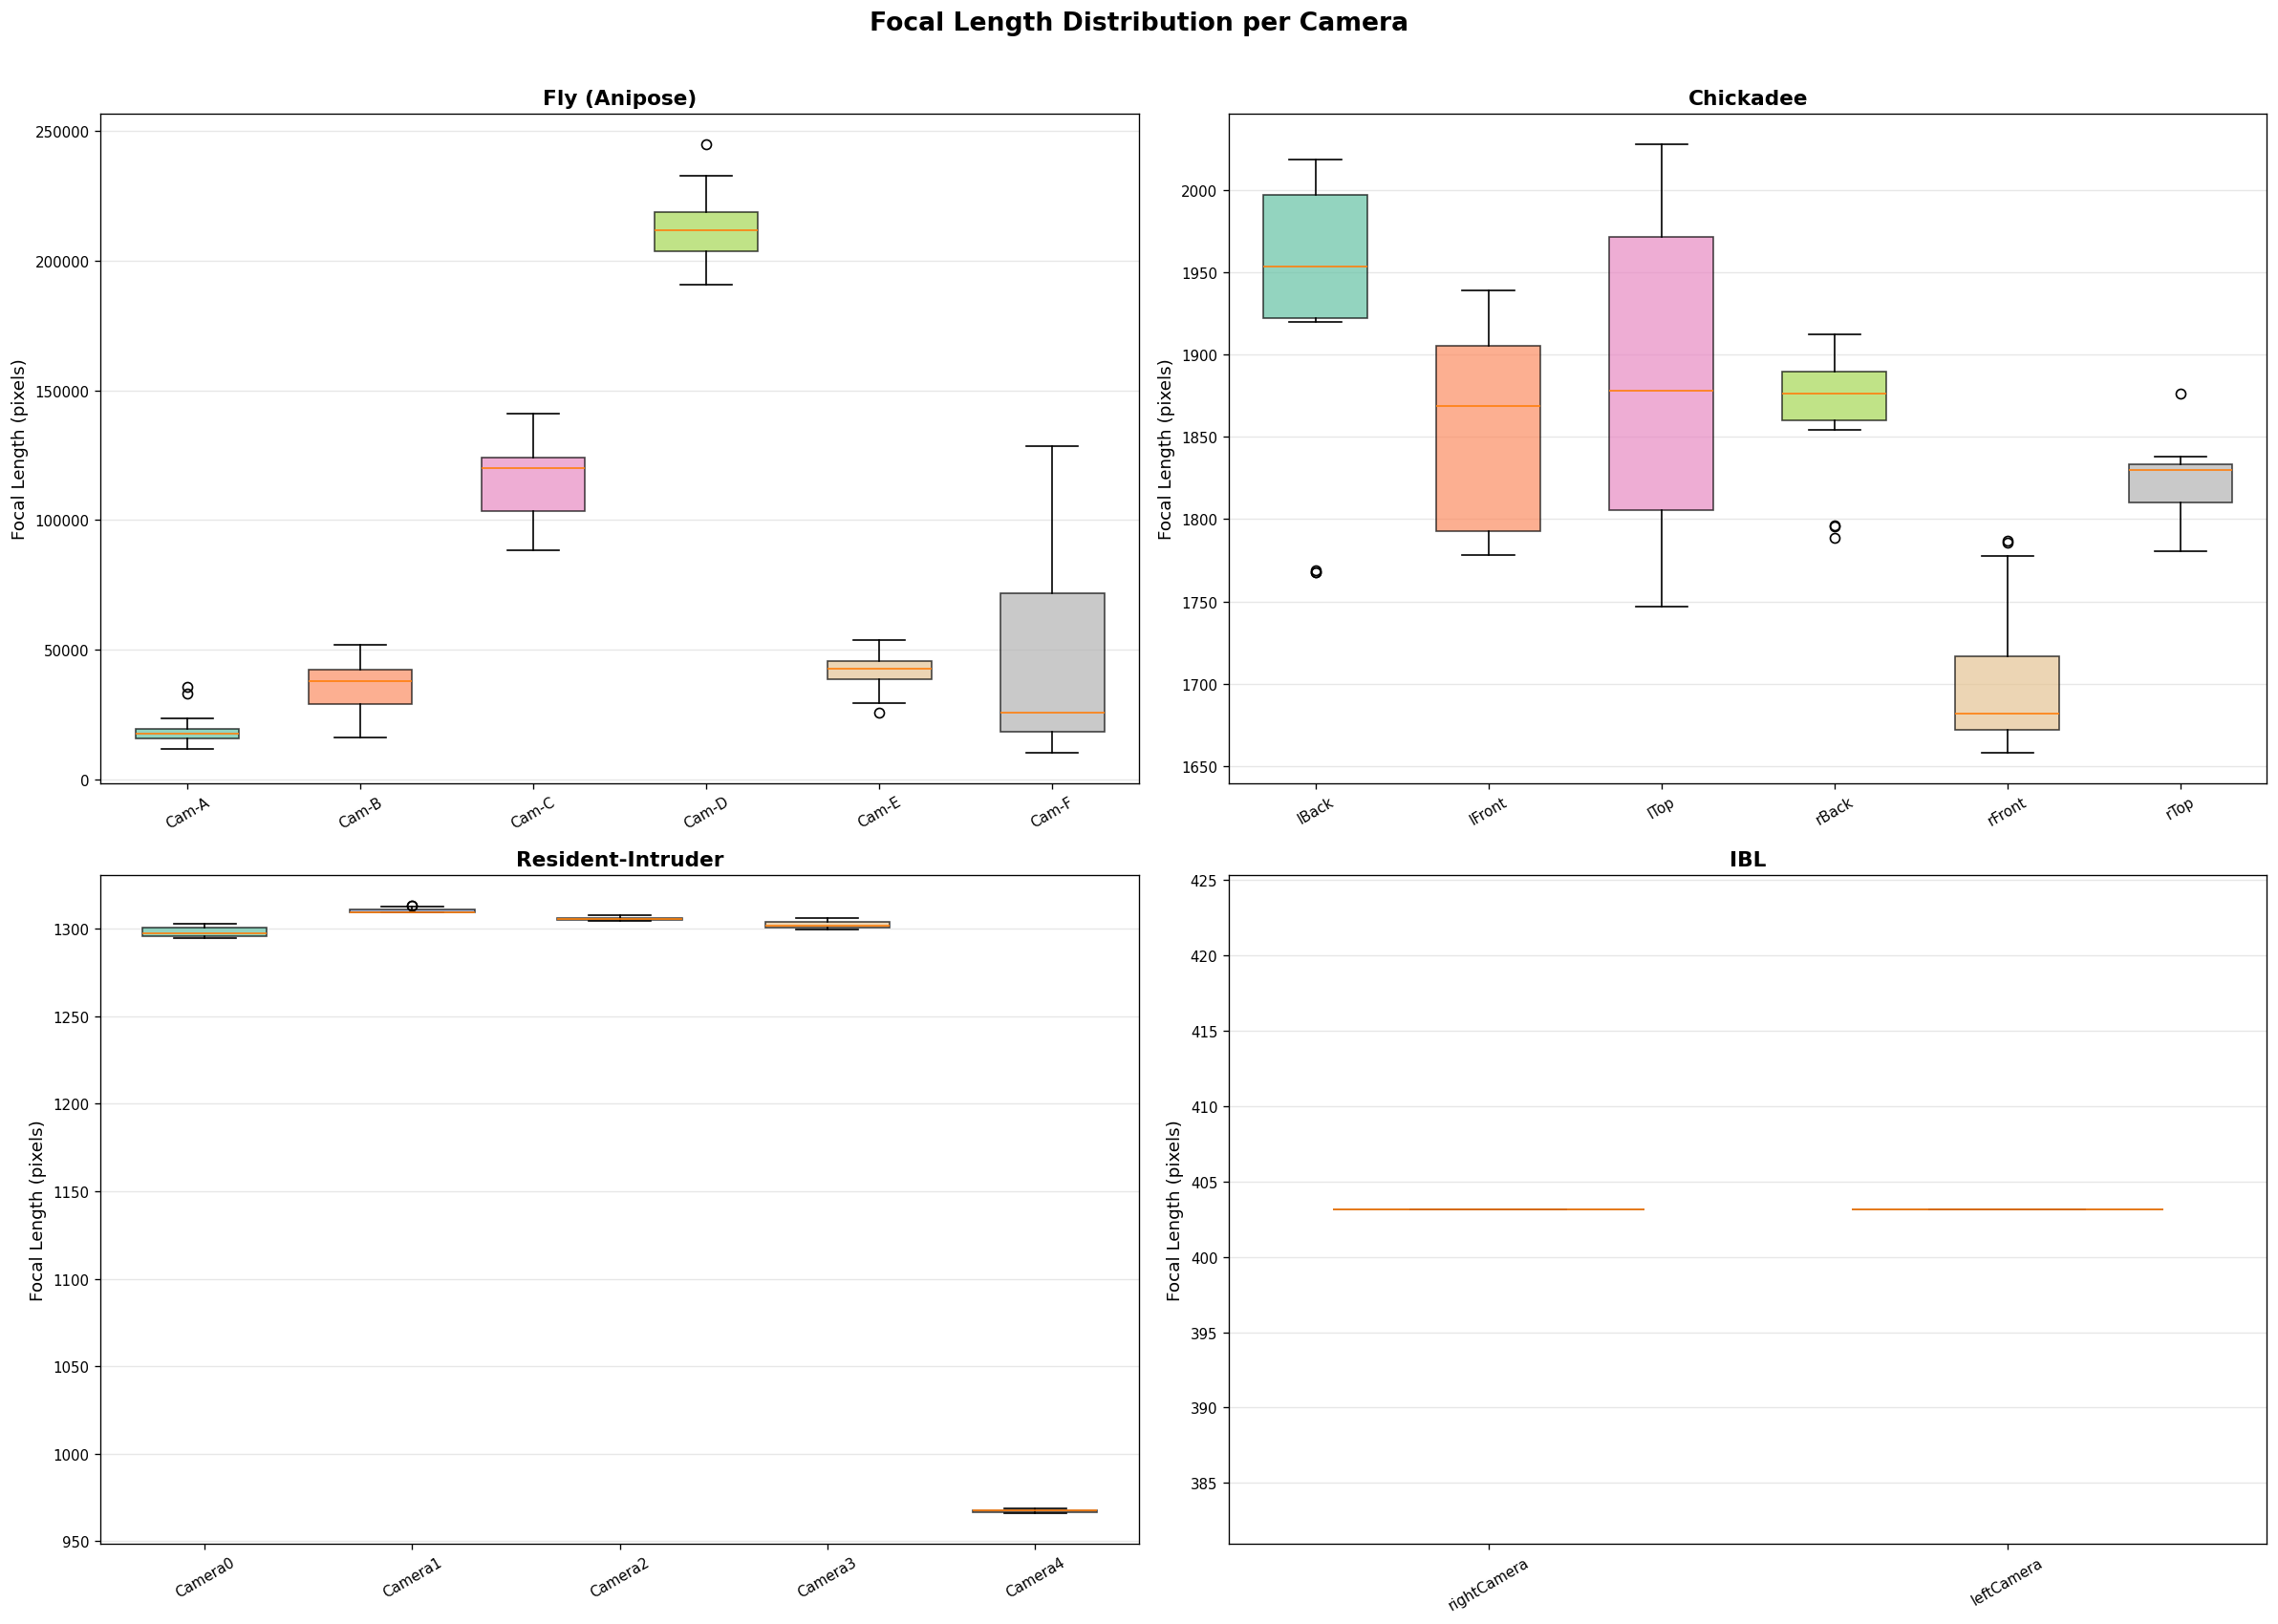

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
axes = axes.ravel()

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    ax = axes[idx]
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())

    focal_data = []
    labels = []
    for cam_name in cam_names:
        focals = [
            params[s]['cameras'][cam_name]['focal_length']
            for s in sessions if cam_name in params[s]['cameras']
        ]
        focal_data.append(focals)
        labels.append(cam_name)

    bp = ax.boxplot(focal_data, labels=labels, patch_artist=True, widths=0.6)
    n_cams = len(cam_names)
    cam_cmap = plt.cm.Set2 if n_cams <= 8 else plt.cm.tab20
    for patch_idx, patch in enumerate(bp['boxes']):
        patch.set_facecolor(cam_cmap(patch_idx / max(n_cams - 1, 1)))
        patch.set_alpha(0.7)

    ax.set_ylabel('Focal Length (pixels)')
    ax.set_title(f"{ds_cfg['display_name']}", fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Focal Length Distribution per Camera',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig('focal_length_distributions.png', bbox_inches='tight')
plt.show()

## Per-Camera Position Scatter (2D Projections)

For each dataset, show XY, XZ, and YZ projections of camera positions across sessions. Tight clusters = consistent placement.

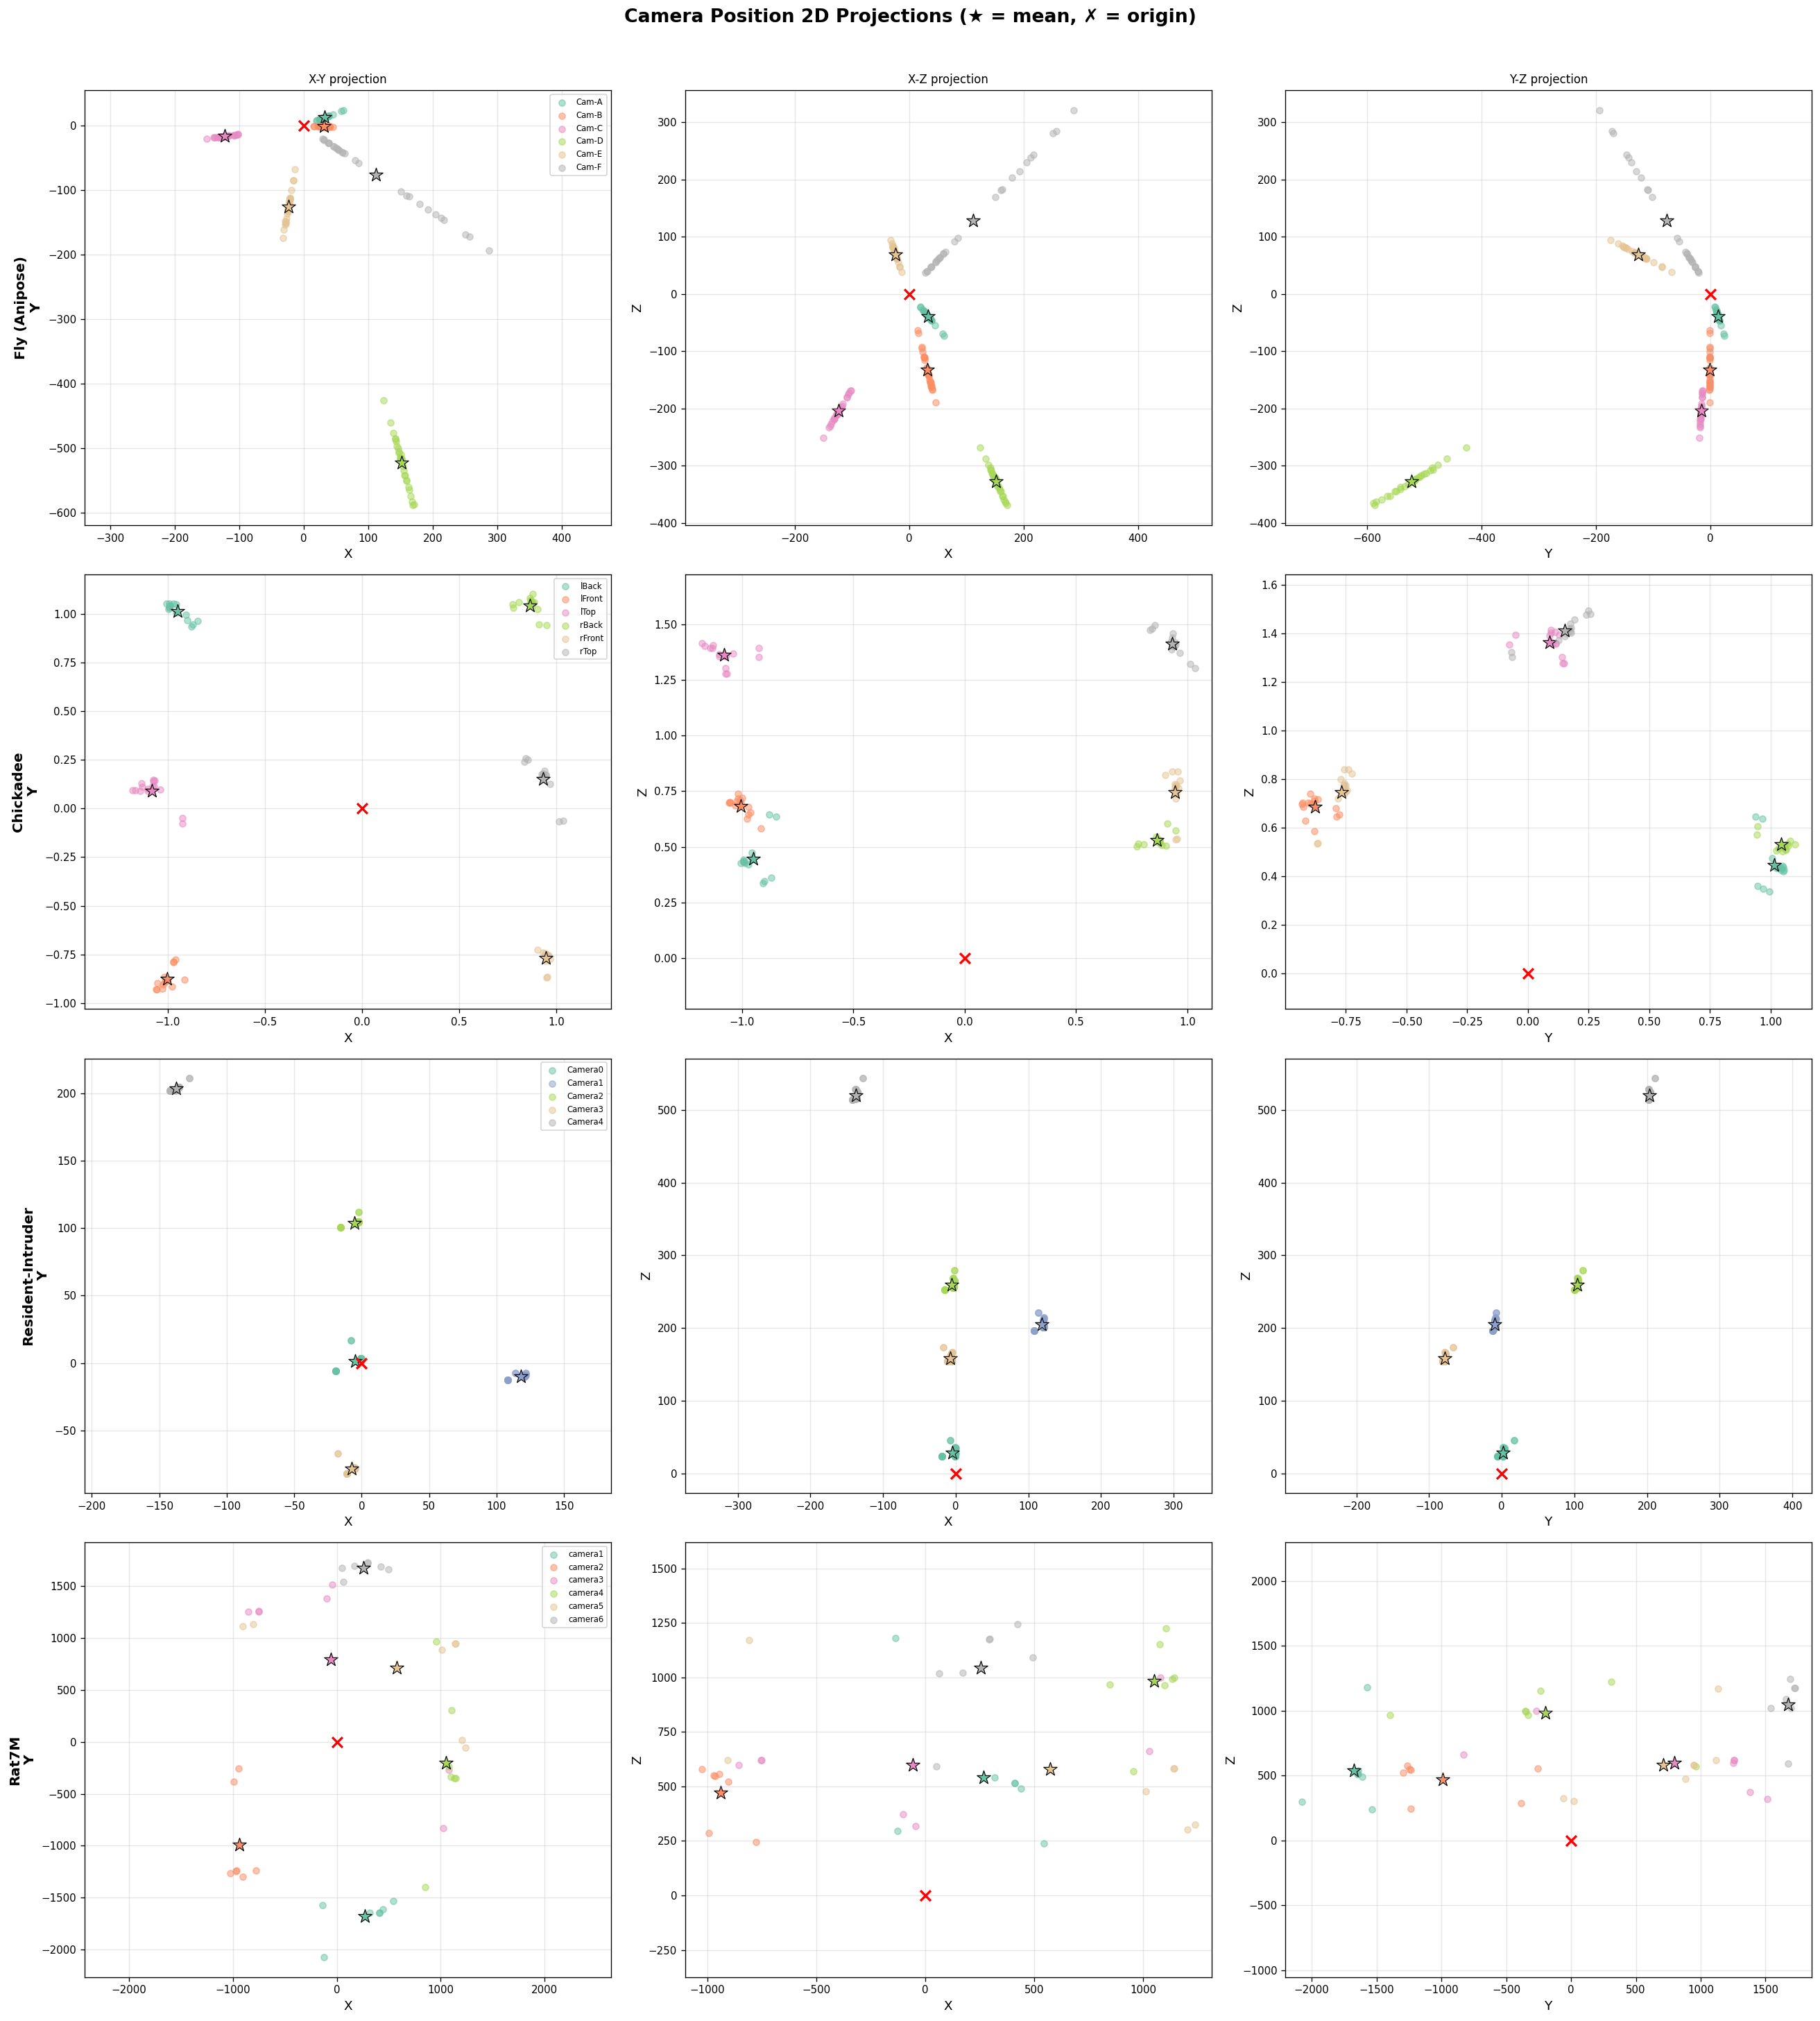

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(22, 24))
proj_labels = [('X', 'Y', 0, 1), ('X', 'Z', 0, 2), ('Y', 'Z', 1, 2)]

for row_idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    n_cams = len(cam_names)
    cam_cmap = plt.cm.Set2 if n_cams <= 8 else plt.cm.tab20
    cam_colors = [cam_cmap(i / max(n_cams - 1, 1)) for i in range(n_cams)]

    for col_idx, (xlabel, ylabel, ai, bi) in enumerate(proj_labels):
        ax = axes[row_idx, col_idx]
        for j, cam_name in enumerate(cam_names):
            positions = np.array([
                params[s]['cameras'][cam_name]['camera_position']
                for s in sessions if cam_name in params[s]['cameras']
            ])
            ax.scatter(positions[:, ai], positions[:, bi],
                       c=[cam_colors[j]], s=30, alpha=0.5, label=cam_name if col_idx == 0 else None)
            mean_pos = positions.mean(axis=0)
            ax.scatter(mean_pos[ai], mean_pos[bi],
                       c=[cam_colors[j]], s=150, marker='*', edgecolors='k', linewidths=0.7)

        ax.scatter(0, 0, c='red', s=80, marker='x', linewidths=2, zorder=10)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        if col_idx == 0:
            ax.set_ylabel(f"{ds_cfg['display_name']}\n{ylabel}", fontsize=12, fontweight='bold')
            ax.legend(fontsize=7, loc='best', framealpha=0.8)
        ax.set_title(f"{xlabel}-{ylabel} projection" if row_idx == 0 else '', fontsize=10)
        ax.set_aspect('equal', adjustable='datalim')

fig.suptitle('Camera Position 2D Projections (\u2605 = mean, \u2717 = origin)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig('camera_positions_2d_projections.png', bbox_inches='tight')
plt.show()

## Cross-Dataset Consistency Comparison

Summary figure comparing how consistent camera placement is across datasets using the coefficient of variation (CV) of camera distance and position spread.

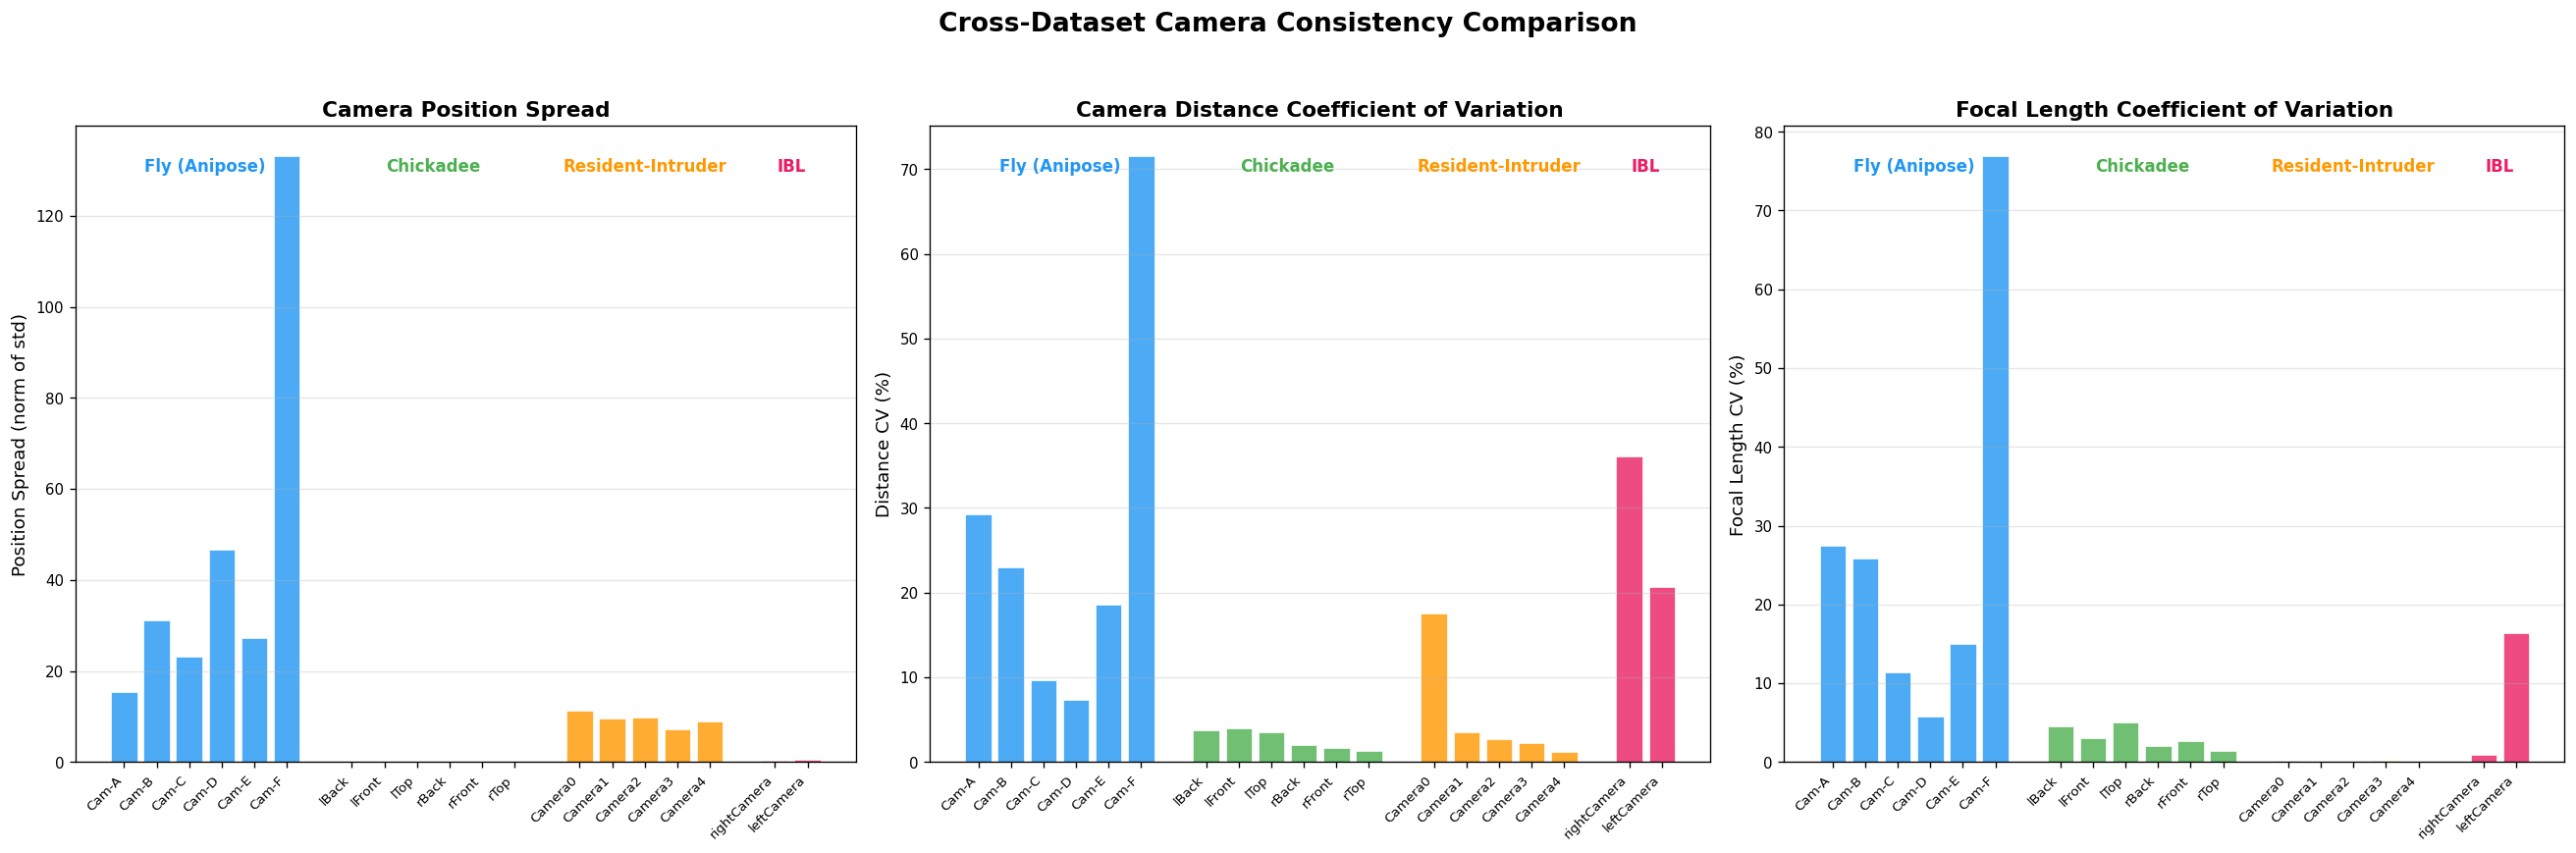

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

ds_names = list(DATASETS.keys())
ds_display = [DATASETS[d]['display_name'] for d in ds_names]
ds_colors = [DATASETS[d]['color'] for d in ds_names]

# --- Panel 1: Mean position spread (norm of std) per camera, grouped by dataset ---
ax = axes[0]
x_offset = 0
tick_positions = []
tick_labels = []
group_centers = []

for ds_idx, ds_name in enumerate(ds_names):
    metrics = all_metrics[ds_name]
    n_cams = len(metrics)
    x_pos = np.arange(n_cams) + x_offset
    ax.bar(x_pos, metrics['position_spread'], color=ds_colors[ds_idx], alpha=0.8,
           edgecolor='white', linewidth=0.5)
    tick_positions.extend(x_pos.tolist())
    tick_labels.extend(metrics['camera'].tolist())
    group_centers.append(np.mean(x_pos))
    x_offset += n_cams + 1

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Position Spread (norm of std)')
ax.set_title('Camera Position Spread', fontweight='bold')
ax.grid(axis='y', alpha=0.3)

for gc, dname, dcol in zip(group_centers, ds_display, ds_colors):
    ax.annotate(dname, xy=(gc, 0), xytext=(gc, ax.get_ylim()[1] * 0.95),
                fontsize=10, fontweight='bold', color=dcol, ha='center', va='top')

# --- Panel 2: Distance CV per camera ---
ax = axes[1]
x_offset = 0
tick_positions = []
tick_labels = []
group_centers = []

for ds_idx, ds_name in enumerate(ds_names):
    metrics = all_metrics[ds_name]
    n_cams = len(metrics)
    x_pos = np.arange(n_cams) + x_offset
    ax.bar(x_pos, metrics['dist_cv'] * 100, color=ds_colors[ds_idx], alpha=0.8,
           edgecolor='white', linewidth=0.5)
    tick_positions.extend(x_pos.tolist())
    tick_labels.extend(metrics['camera'].tolist())
    group_centers.append(np.mean(x_pos))
    x_offset += n_cams + 1

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Distance CV (%)')
ax.set_title('Camera Distance Coefficient of Variation', fontweight='bold')
ax.grid(axis='y', alpha=0.3)

for gc, dname, dcol in zip(group_centers, ds_display, ds_colors):
    ax.annotate(dname, xy=(gc, 0), xytext=(gc, ax.get_ylim()[1] * 0.95),
                fontsize=10, fontweight='bold', color=dcol, ha='center', va='top')

# --- Panel 3: Focal length CV per camera ---
ax = axes[2]
x_offset = 0
tick_positions = []
tick_labels = []
group_centers = []

for ds_idx, ds_name in enumerate(ds_names):
    metrics = all_metrics[ds_name]
    n_cams = len(metrics)
    x_pos = np.arange(n_cams) + x_offset
    ax.bar(x_pos, metrics['focal_cv'] * 100, color=ds_colors[ds_idx], alpha=0.8,
           edgecolor='white', linewidth=0.5)
    tick_positions.extend(x_pos.tolist())
    tick_labels.extend(metrics['camera'].tolist())
    group_centers.append(np.mean(x_pos))
    x_offset += n_cams + 1

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Focal Length CV (%)')
ax.set_title('Focal Length Coefficient of Variation', fontweight='bold')
ax.grid(axis='y', alpha=0.3)

for gc, dname, dcol in zip(group_centers, ds_display, ds_colors):
    ax.annotate(dname, xy=(gc, 0), xytext=(gc, ax.get_ylim()[1] * 0.95),
                fontsize=10, fontweight='bold', color=dcol, ha='center', va='top')

fig.suptitle('Cross-Dataset Camera Consistency Comparison',
             fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
# plt.savefig('cross_dataset_consistency.png', bbox_inches='tight')
plt.show()

## Pairwise Inter-Camera Distance Consistency

For each dataset, compute the pairwise distance between cameras in each session, then show how stable these inter-camera distances are. Stable rigs should have near-zero variation.

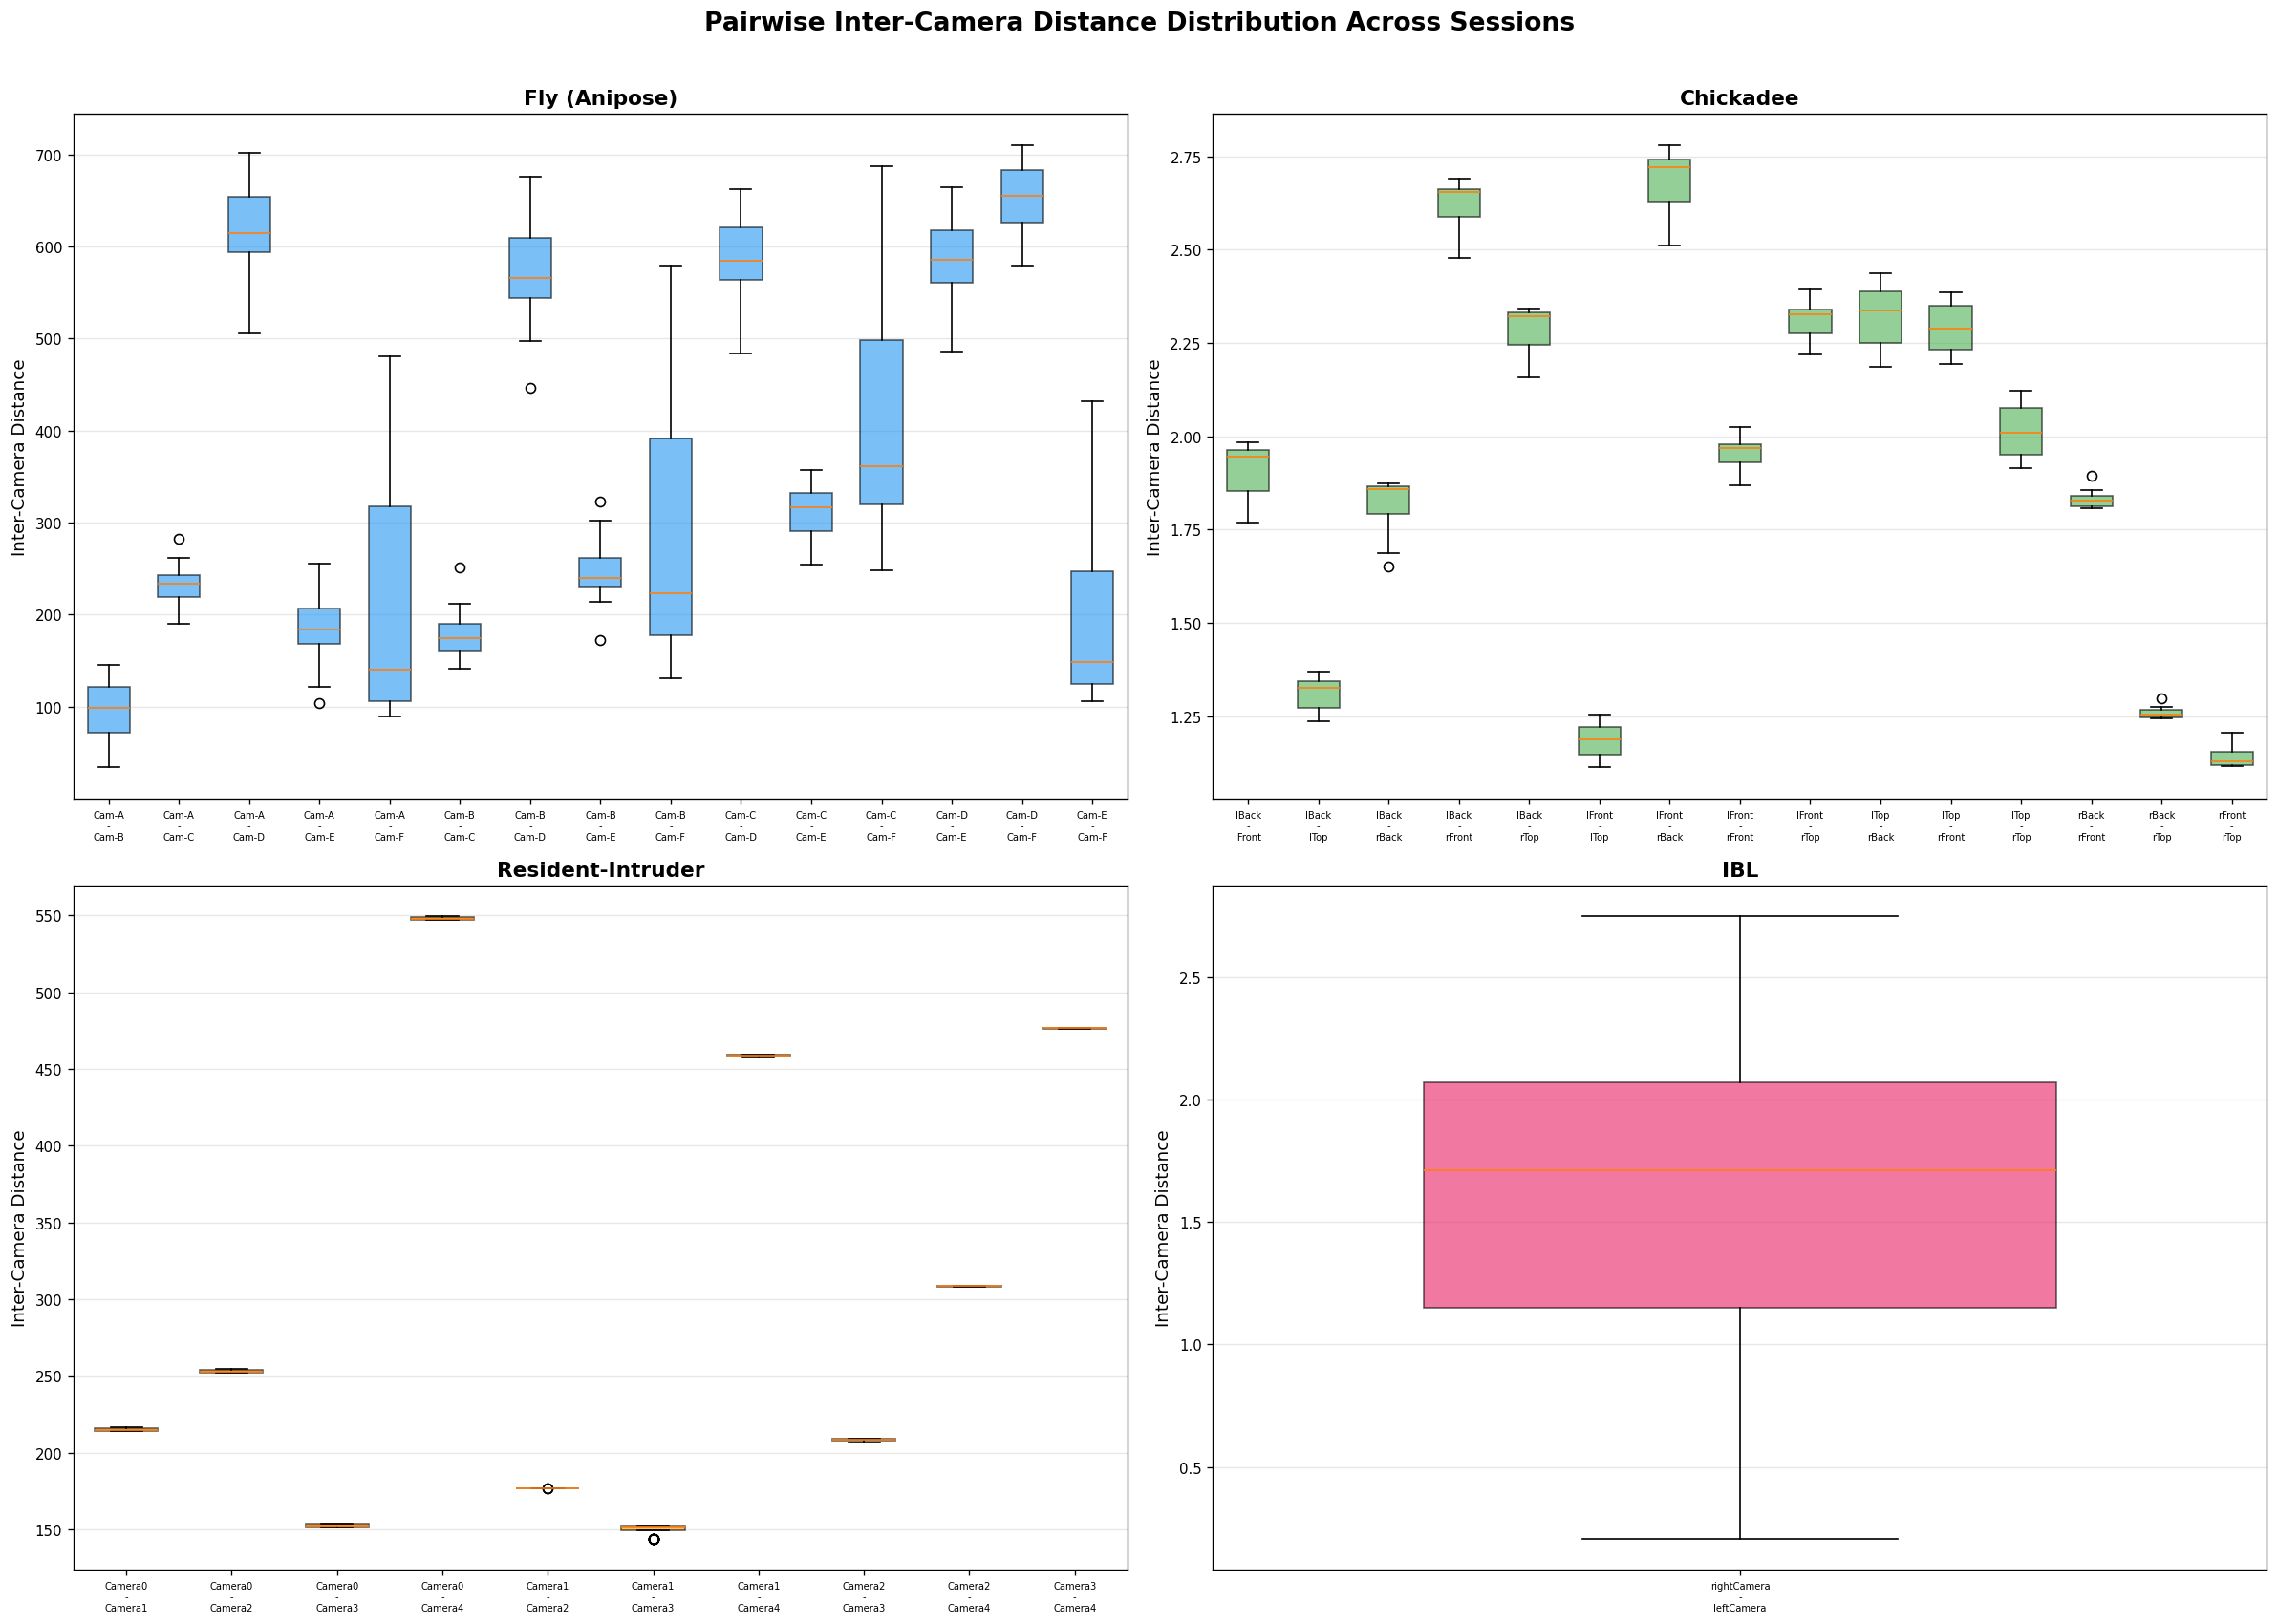

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
axes = axes.ravel()

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    ax = axes[idx]
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    n_cams = len(cam_names)

    pair_labels = []
    pair_dists_all = []
    for i in range(n_cams):
        for j in range(i + 1, n_cams):
            pair_label = f"{cam_names[i]}\n-\n{cam_names[j]}"
            pair_labels.append(pair_label)
            dists = []
            for s in sessions:
                c1 = params[s]['cameras'].get(cam_names[i])
                c2 = params[s]['cameras'].get(cam_names[j])
                if c1 is not None and c2 is not None:
                    d = np.linalg.norm(c1['camera_position'] - c2['camera_position'])
                    dists.append(d)
            pair_dists_all.append(dists)

    bp = ax.boxplot(pair_dists_all, labels=pair_labels, patch_artist=True, widths=0.6)
    for patch in bp['boxes']:
        patch.set_facecolor(ds_cfg['color'])
        patch.set_alpha(0.6)

    ax.set_ylabel('Inter-Camera Distance')
    ax.set_title(f"{ds_cfg['display_name']}", fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', labelsize=6)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Pairwise Inter-Camera Distance Distribution Across Sessions',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig('inter_camera_distance_consistency.png', bbox_inches='tight')
plt.show()

## Rotation Angle Variability

For each camera, compute the rotation angle (from rotation vector magnitude) across sessions. This shows how much the camera orientation varies.

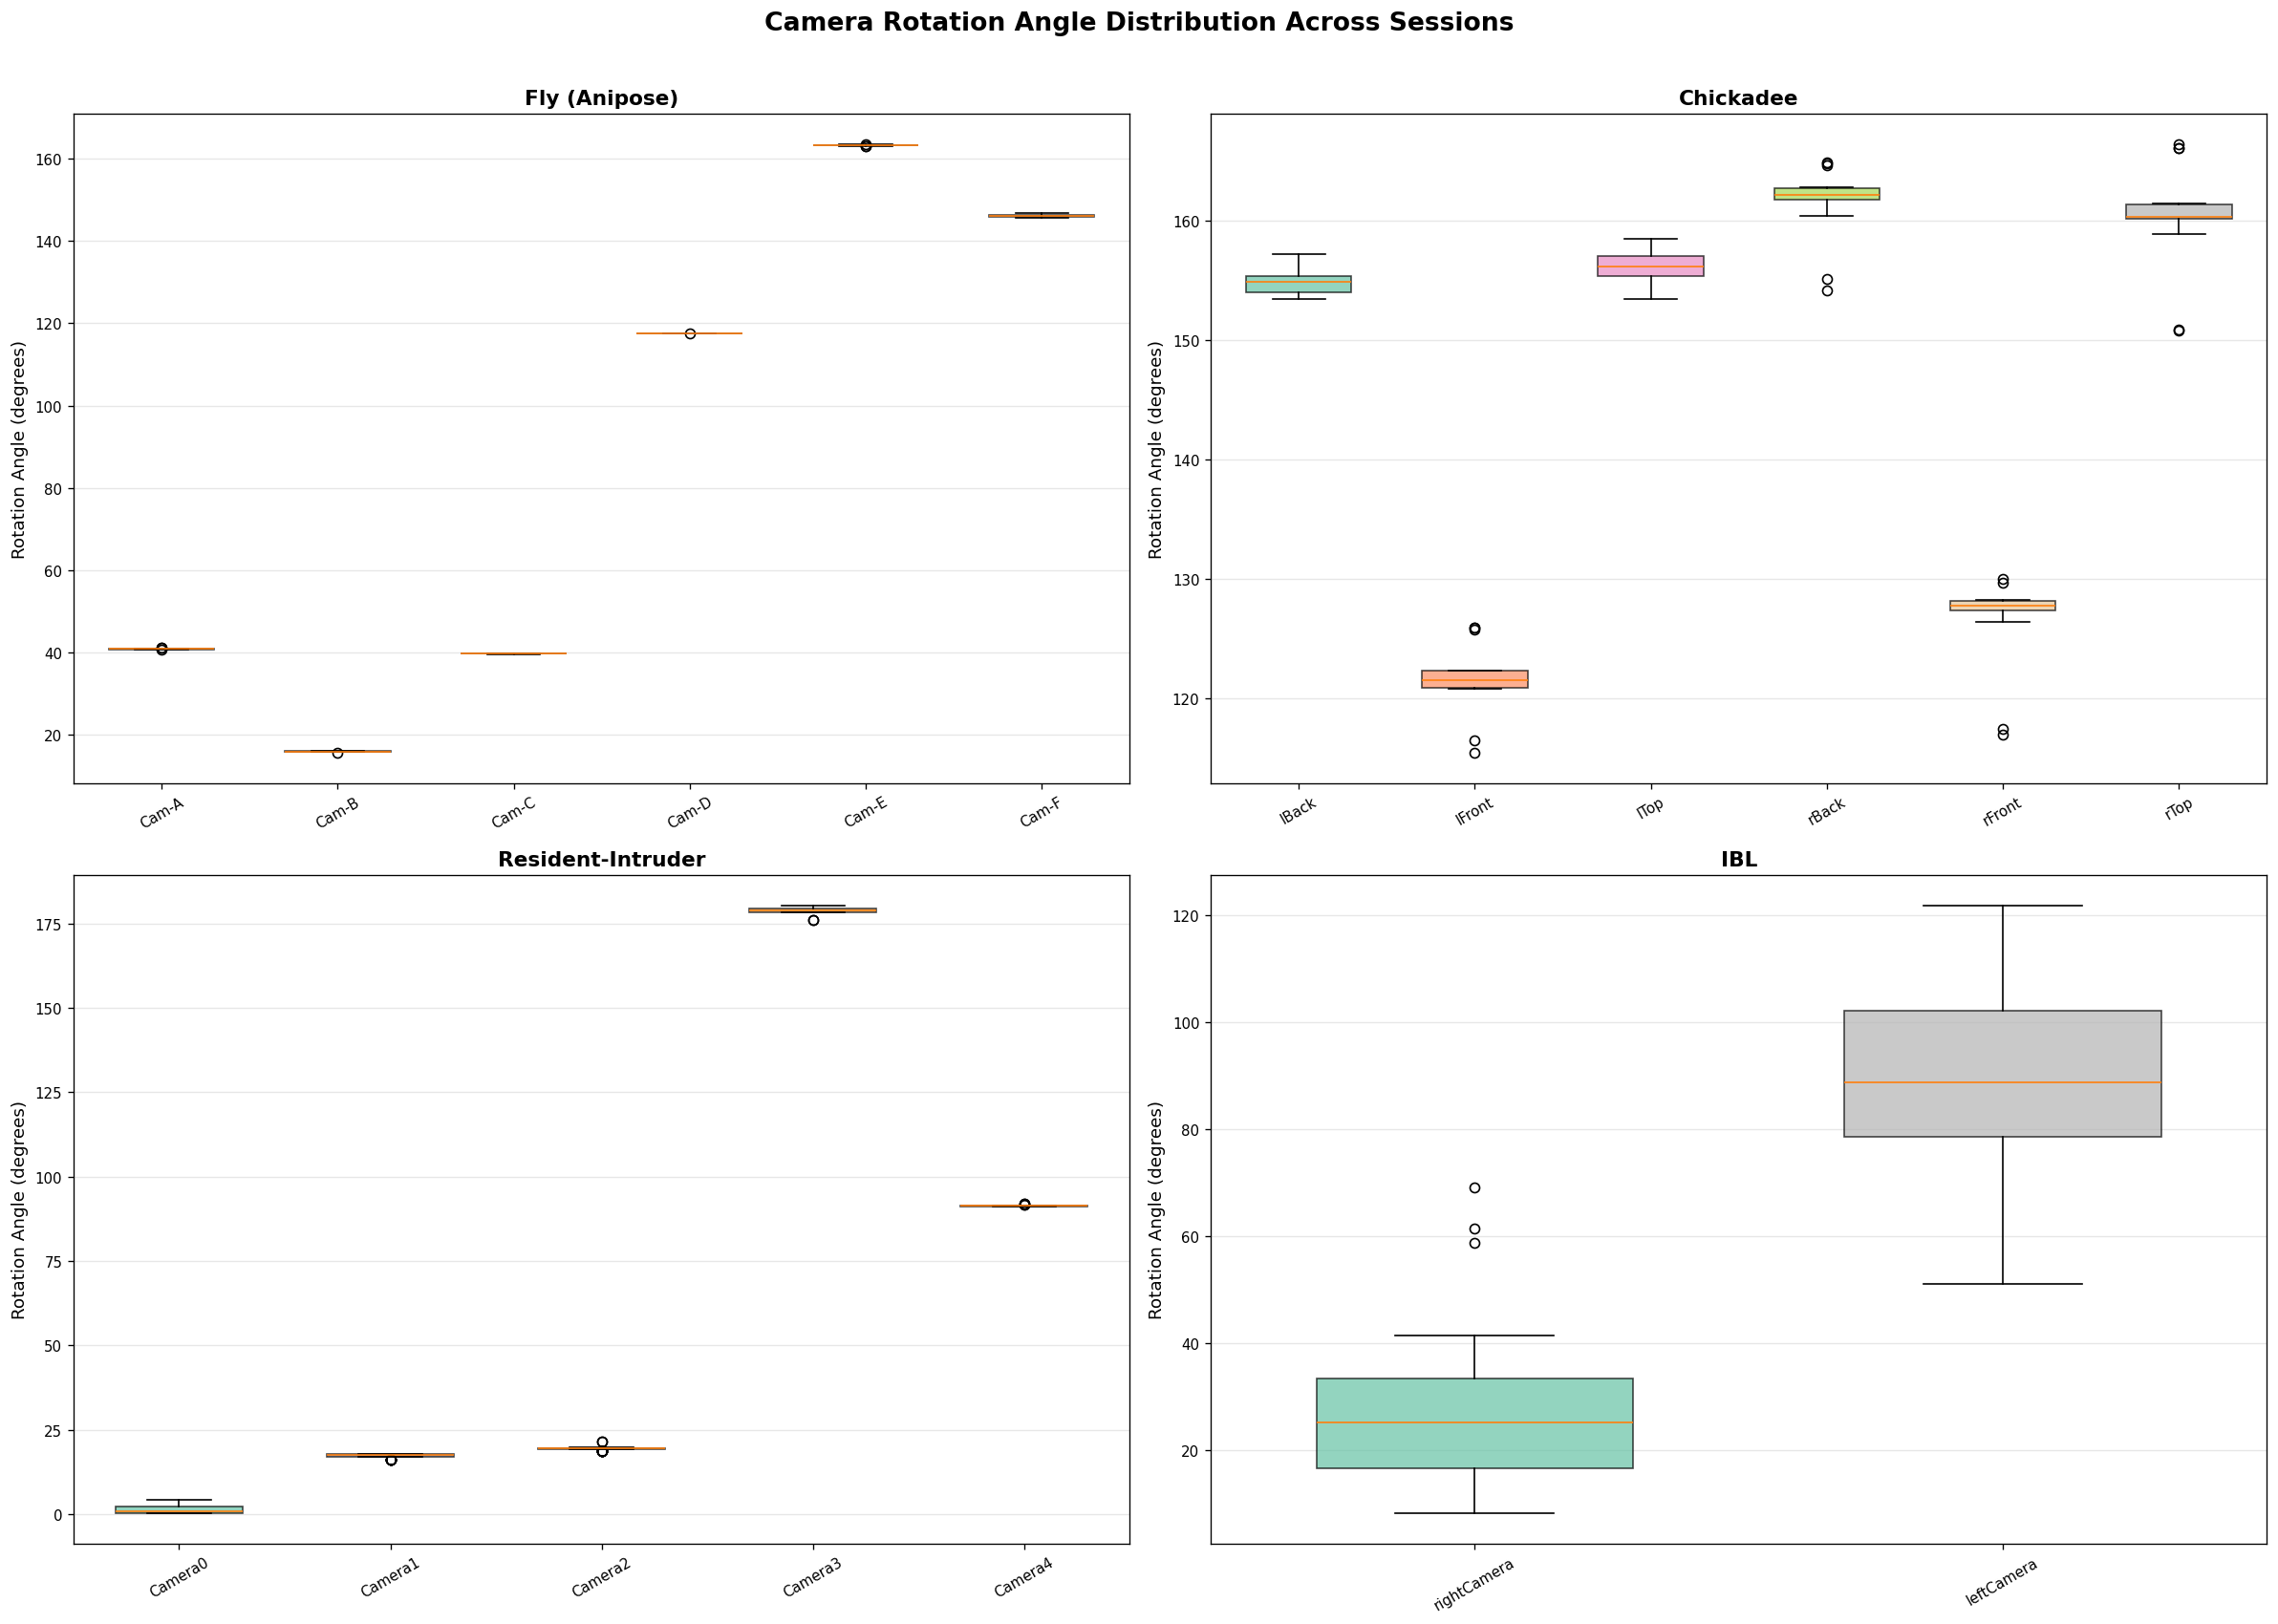

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
axes = axes.ravel()

for idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    ax = axes[idx]
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    n_cams = len(cam_names)

    rot_data = []
    for cam_name in cam_names:
        angles_deg = []
        for s in sessions:
            cam = params[s]['cameras'].get(cam_name)
            if cam is not None:
                angle = np.linalg.norm(cam['rotation_vec']) * 180.0 / np.pi
                angles_deg.append(angle)
        rot_data.append(angles_deg)

    bp = ax.boxplot(rot_data, labels=cam_names, patch_artist=True, widths=0.6)
    cam_cmap = plt.cm.Set2 if n_cams <= 8 else plt.cm.tab20
    for pi, patch in enumerate(bp['boxes']):
        patch.set_facecolor(cam_cmap(pi / max(n_cams - 1, 1)))
        patch.set_alpha(0.7)

    ax.set_ylabel('Rotation Angle (degrees)')
    ax.set_title(f"{ds_cfg['display_name']}", fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Camera Rotation Angle Distribution Across Sessions',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig('rotation_angle_distributions.png', bbox_inches='tight')
plt.show()

## Euler Angles (X / Y / Z) Variability

Rotation is decomposed into **Euler angles** (rotation around X, Y, Z axes in degrees) so we can quantify variability along each axis. The histograms show the distribution of each angle across all sessions and cameras; the summary table below reports **std** and **range** (max − min) in degrees per axis per dataset, which can be used to define what counts as "sufficiently small" variability in camera orientation.

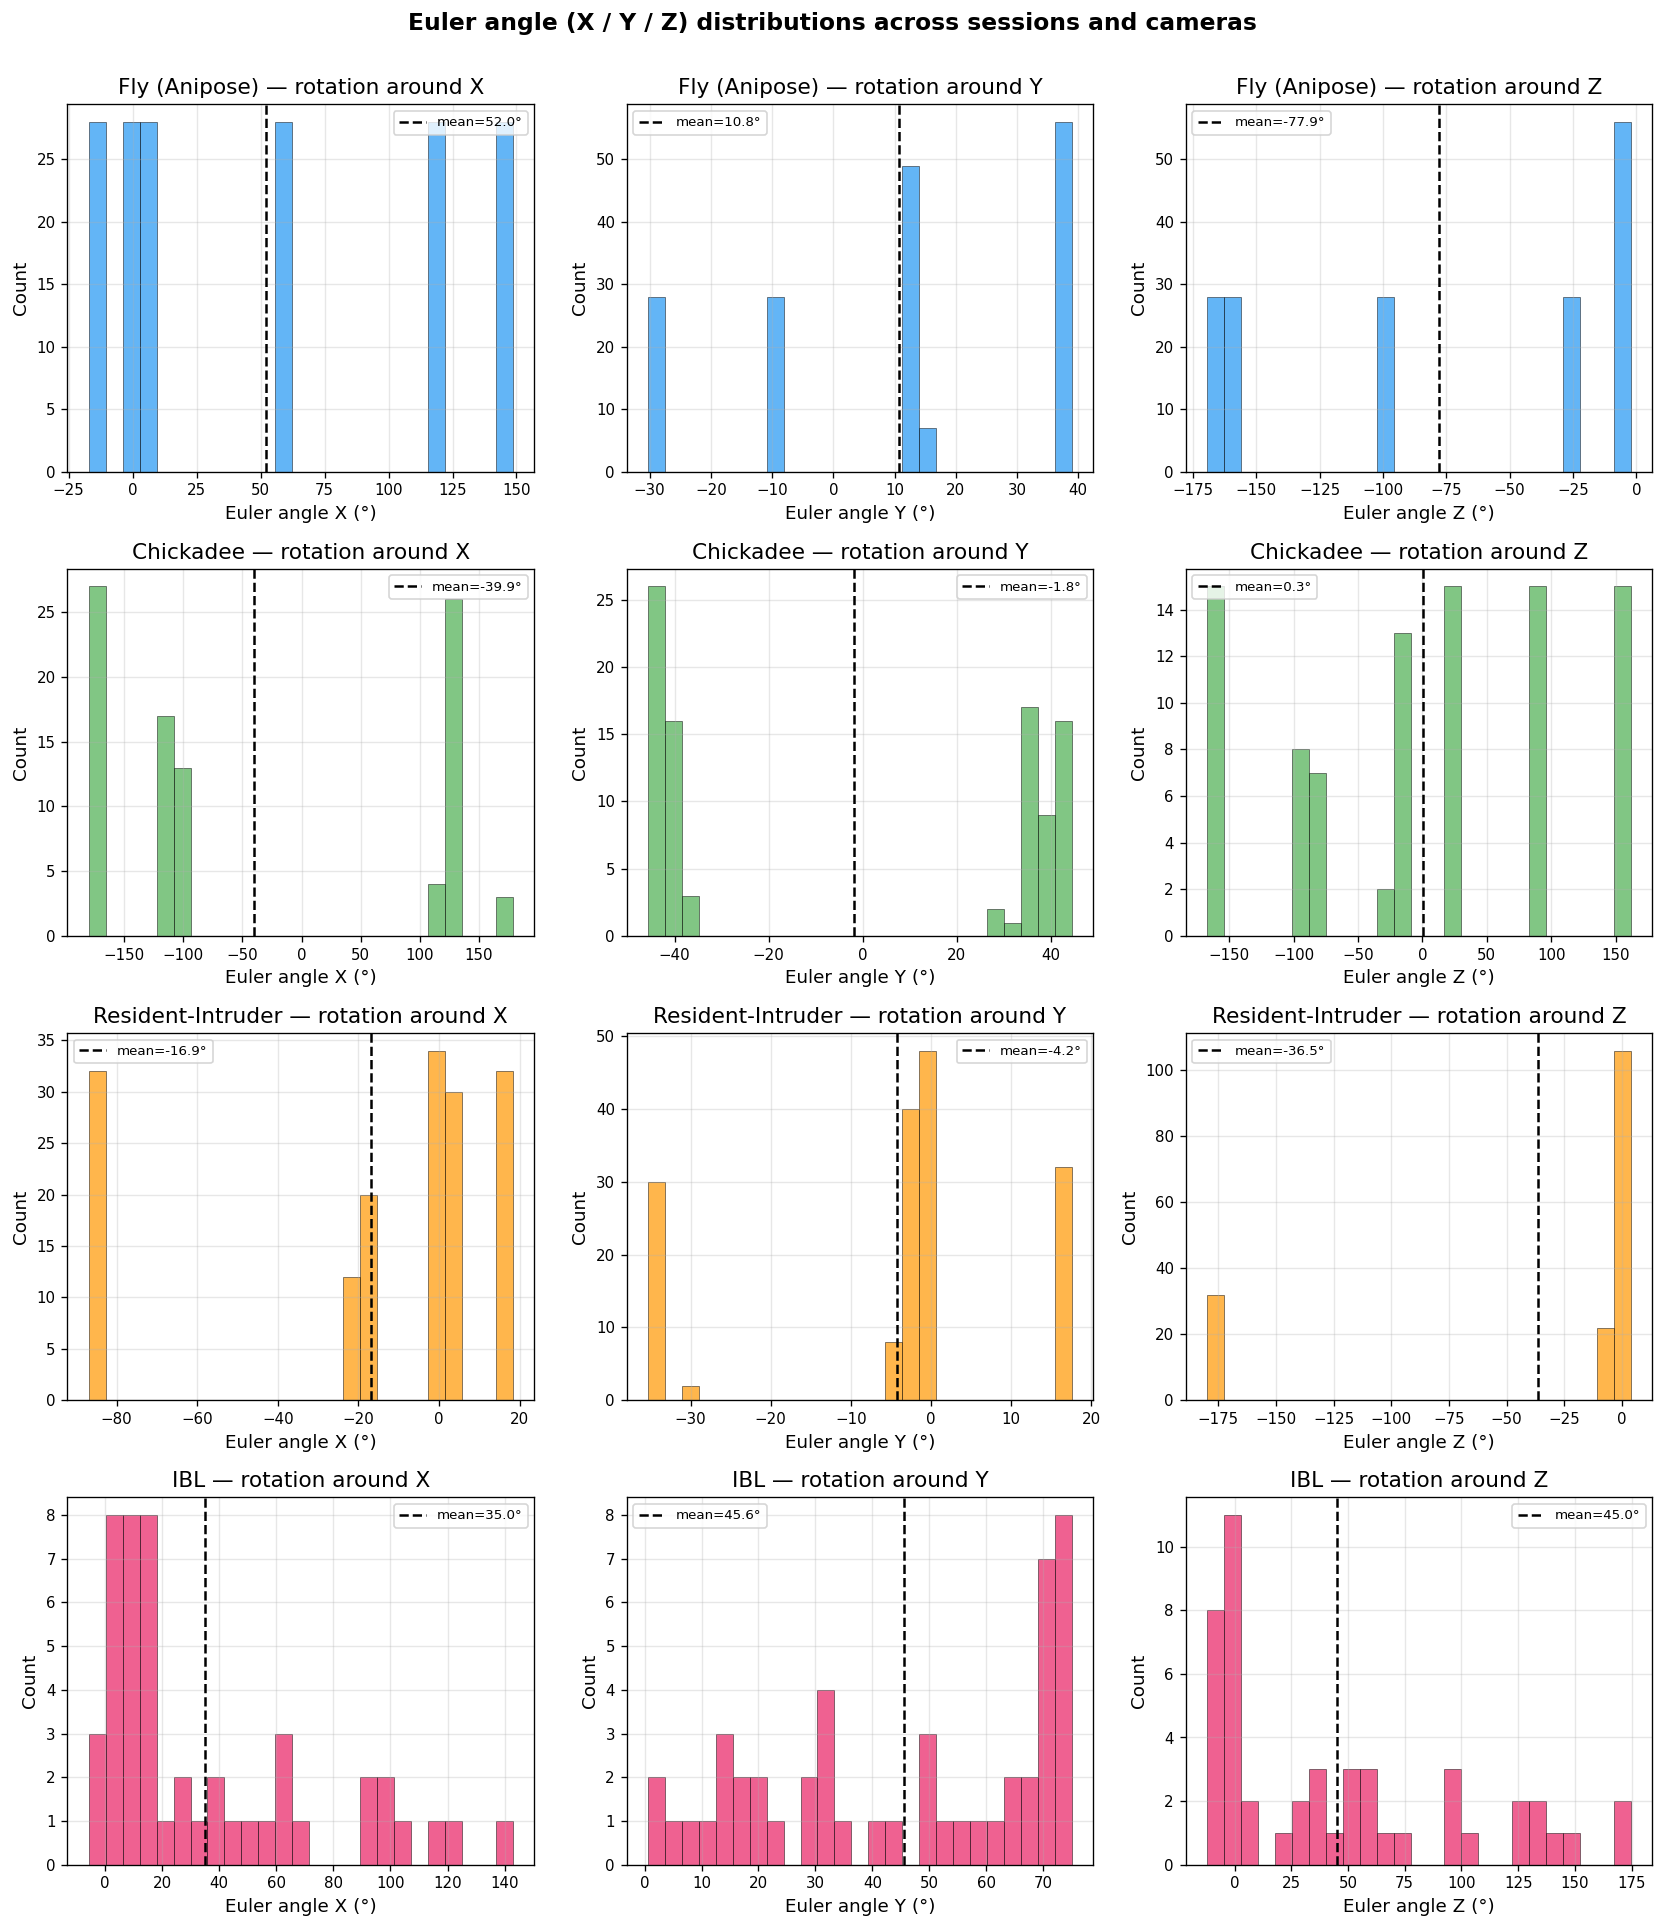

Euler angle variability (degrees) per dataset:
          Dataset   N     X_std°   X_range°    Y_std°  Y_range°     Z_std°   Z_range°
    Fly (Anipose) 168  62.222344 165.852890 24.327074 69.289982  69.556646 167.358091
        Chickadee  90 133.277971 358.684082 40.311522 90.262246 107.747021 329.477890
Resident-Intruder 160  35.941089 105.236262 16.707964 52.982534  71.346937 183.872112
              IBL  48  38.665848 148.603668 24.679404 74.514660  55.032784 187.000820


In [53]:
# Collect Euler angles (degrees) per dataset: rotation around X, Y, Z
def get_euler_xyz_deg(rotation_vec):
    """Rotation vector -> (euler_x, euler_y, euler_z) in degrees (intrinsic 'xyz')."""
    r = Rotation.from_rotvec(rotation_vec)
    return r.as_euler('xyz', degrees=True)

fig, axes = plt.subplots(4, 3, figsize=(14, 16))
euler_summary = []

for ds_idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())

    ex, ey, ez = [], [], []
    for s in sessions:
        for cam_name in cam_names:
            cam = params[s]['cameras'].get(cam_name)
            if cam is None:
                continue
            x, y, z = get_euler_xyz_deg(cam['rotation_vec'])
            ex.append(x); ey.append(y); ez.append(z)

    ex, ey, ez = np.array(ex), np.array(ey), np.array(ez)
    euler_summary.append({
        'dataset': ds_cfg['display_name'],
        'n': len(ex),
        'X_deg_mean': np.mean(ex), 'X_deg_std': np.std(ex), 'X_deg_range': np.ptp(ex),
        'Y_deg_mean': np.mean(ey), 'Y_deg_std': np.std(ey), 'Y_deg_range': np.ptp(ey),
        'Z_deg_mean': np.mean(ez), 'Z_deg_std': np.std(ez), 'Z_deg_range': np.ptp(ez),
    })

    for ax_idx, (angles, label) in enumerate([(ex, 'X'), (ey, 'Y'), (ez, 'Z')]):
        ax = axes[ds_idx, ax_idx]
        ax.hist(angles, bins=min(25, max(len(np.unique(angles)) + 1, 10)),
                color=ds_cfg['color'], alpha=0.7, edgecolor='k', linewidth=0.4)
        ax.axvline(np.mean(angles), color='black', ls='--', lw=1.5, label=f'mean={np.mean(angles):.1f}°')
        ax.set_ylabel('Count')
        ax.set_xlabel(f'Euler angle {label} (°)')
        ax.set_title(f"{ds_cfg['display_name']} — rotation around {label}")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

plt.suptitle('Euler angle (X / Y / Z) distributions across sessions and cameras',
             fontsize=14, fontweight='bold', y=1.002)
plt.tight_layout()
plt.show()

# Summary table: variability in each axis (std and range in degrees)
euler_df = pd.DataFrame(euler_summary)
print("Euler angle variability (degrees) per dataset:")
disp = euler_df[['dataset', 'n',
    'X_deg_std', 'X_deg_range', 'Y_deg_std', 'Y_deg_range', 'Z_deg_std', 'Z_deg_range']].copy()
disp.columns = ['Dataset', 'N', 'X_std°', 'X_range°', 'Y_std°', 'Y_range°', 'Z_std°', 'Z_range°']
print(disp.to_string(index=False))

## Summary Table: Consistency Metrics

Aggregated statistics per dataset showing overall camera placement consistency.

In [54]:
summary_rows = []
for ds_name, ds_cfg in DATASETS.items():
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    metrics = all_metrics[ds_name]

    all_dists_cv = []
    for cam_name in cam_names:
        dists = [
            params[s]['cameras'][cam_name]['distance_from_origin']
            for s in sessions if cam_name in params[s]['cameras']
        ]
        if len(dists) > 1 and np.mean(dists) > 0:
            all_dists_cv.append(np.std(dists) / np.mean(dists))

    pair_cvs = []
    for i in range(len(cam_names)):
        for j in range(i + 1, len(cam_names)):
            dists = []
            for s in sessions:
                c1 = params[s]['cameras'].get(cam_names[i])
                c2 = params[s]['cameras'].get(cam_names[j])
                if c1 is not None and c2 is not None:
                    d = np.linalg.norm(c1['camera_position'] - c2['camera_position'])
                    dists.append(d)
            if len(dists) > 1 and np.mean(dists) > 0:
                pair_cvs.append(np.std(dists) / np.mean(dists))

    summary_rows.append({
        'Dataset': ds_cfg['display_name'],
        'Sessions': len(sessions),
        'Cameras': len(cam_names),
        'Mean Position Spread': f"{metrics['position_spread'].mean():.4f}",
        'Mean Distance CV (%)': f"{np.mean(all_dists_cv) * 100:.2f}",
        'Mean Focal CV (%)': f"{metrics['focal_cv'].mean() * 100:.2f}",
        'Mean Pairwise Dist CV (%)': f"{np.mean(pair_cvs) * 100:.2f}" if pair_cvs else 'N/A',
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
summary_df

          Dataset  Sessions  Cameras Mean Position Spread Mean Distance CV (%) Mean Focal CV (%) Mean Pairwise Dist CV (%)
    Fly (Anipose)        28        6              46.0561                26.54             27.04                     20.56
        Chickadee        15        6               0.0953                 2.74              3.09                      2.78
Resident-Intruder        32        5               9.3006                 5.45              0.13                      0.45
              IBL        24        2               0.4582                28.32              8.62                     44.32


,Dataset,Sessions,Cameras,Mean Position Spread,Mean Distance CV (%),Mean Focal CV (%),Mean Pairwise Dist CV (%)
0,Fly (Anipose),28,6,46.0561,26.54,27.04,20.56
1,Chickadee,15,6,0.0953,2.74,3.09,2.78
2,Resident-Intruder,32,5,9.3006,5.45,0.13,0.45
3,IBL,24,2,0.4582,28.32,8.62,44.32


## Detailed Per-Camera Metrics Table

In [55]:
for ds_name, ds_cfg in DATASETS.items():
    print(f"\n{'='*60}")
    print(f"  {ds_cfg['display_name']}")
    print(f"{'='*60}")
    metrics = all_metrics[ds_name]
    display_cols = ['camera', 'n_sessions', 'position_spread',
                    'focal_mean', 'focal_std', 'focal_cv',
                    'dist_mean', 'dist_std', 'dist_cv']
    display_df = metrics[display_cols].copy()
    display_df['focal_cv'] = display_df['focal_cv'].apply(lambda x: f"{x*100:.2f}%")
    display_df['dist_cv'] = display_df['dist_cv'].apply(lambda x: f"{x*100:.2f}%")
    display_df.columns = ['Camera', 'Sessions', 'Pos Spread',
                          'Focal Mean', 'Focal Std', 'Focal CV',
                          'Dist Mean', 'Dist Std', 'Dist CV']
    print(display_df.to_string(index=False))
    display(display_df)


  Fly (Anipose)
Camera  Sessions  Pos Spread    Focal Mean    Focal Std Focal CV  Dist Mean   Dist Std Dist CV
 Cam-A        28   15.274679  18708.326741  5123.559762   27.39%  52.308419  15.270631  29.19%
 Cam-B        28   31.200434  36205.030103  9328.606858   25.77% 136.067291  31.197515  22.93%
 Cam-C        28   23.094459 116403.296391 13303.673067   11.43% 238.975996  23.088691   9.66%
 Cam-D        28   46.556461 211677.873547 12330.962319    5.83% 635.533366  46.535316   7.32%
 Cam-E        28   27.151269  41883.039049  6265.295153   14.96% 145.871604  27.144505  18.61%
 Cam-F        28  133.059230  45928.831809 35308.790286   76.88% 186.024329 133.025916  71.51%


,Camera,Sessions,Pos Spread,Focal Mean,Focal Std,Focal CV,Dist Mean,Dist Std,Dist CV
0,Cam-A,28,15.274679,18708.326741,5123.559762,27.39%,52.308419,15.270631,29.19%
1,Cam-B,28,31.200434,36205.030103,9328.606858,25.77%,136.067291,31.197515,22.93%
2,Cam-C,28,23.094459,116403.296391,13303.673067,11.43%,238.975996,23.088691,9.66%
3,Cam-D,28,46.556461,211677.873547,12330.962319,5.83%,635.533366,46.535316,7.32%
4,Cam-E,28,27.151269,41883.039049,6265.295153,14.96%,145.871604,27.144505,18.61%
5,Cam-F,28,133.059230,45928.831809,35308.790286,76.88%,186.024329,133.025916,71.51%



  Chickadee
Camera  Sessions  Pos Spread  Focal Mean  Focal Std Focal CV  Dist Mean  Dist Std Dist CV
 lBack        15    0.107168 1932.468104  87.209740    4.51%   1.461134  0.055221   3.78%
lFront        15    0.073835 1856.581912  55.951401    3.01%   1.498699  0.060349   4.03%
  lTop        15    0.105063 1880.120415  93.338381    4.96%   1.742050  0.061597   3.54%
 rBack        15    0.067860 1865.871920  38.880584    2.08%   1.455943  0.029951   2.06%
rFront        15    0.098785 1702.124255  44.252283    2.60%   1.432754  0.023767   1.66%
  rTop        15    0.118990 1821.372068  24.878832    1.37%   1.702182  0.023263   1.37%


,Camera,Sessions,Pos Spread,Focal Mean,Focal Std,Focal CV,Dist Mean,Dist Std,Dist CV
0,lBack,15,0.107168,1932.468104,87.209740,4.51%,1.461134,0.055221,3.78%
1,lFront,15,0.073835,1856.581912,55.951401,3.01%,1.498699,0.060349,4.03%
2,lTop,15,0.105063,1880.120415,93.338381,4.96%,1.742050,0.061597,3.54%
3,rBack,15,0.067860,1865.871920,38.880584,2.08%,1.455943,0.029951,2.06%
4,rFront,15,0.098785,1702.124255,44.252283,2.60%,1.432754,0.023767,1.66%
5,rTop,15,0.118990,1821.372068,24.878832,1.37%,1.702182,0.023263,1.37%



  Resident-Intruder
 Camera  Sessions  Pos Spread  Focal Mean  Focal Std Focal CV  Dist Mean  Dist Std Dist CV
Camera0        32   11.228720 1298.038192   2.778828    0.21%  31.502099  5.510141  17.49%
Camera1        32    9.470590 1310.481702   1.130556    0.09% 236.735337  8.278486   3.50%
Camera2        32    9.711106 1305.713806   1.215230    0.09% 280.585206  7.737118   2.76%
Camera3        32    7.238498 1302.187745   2.017233    0.15% 177.845559  4.021728   2.26%
Camera4        32    8.853876  967.122166   0.801738    0.08% 576.096739  7.050576   1.22%


,Camera,Sessions,Pos Spread,Focal Mean,Focal Std,Focal CV,Dist Mean,Dist Std,Dist CV
0,Camera0,32,11.228720,1298.038192,2.778828,0.21%,31.502099,5.510141,17.49%
1,Camera1,32,9.470590,1310.481702,1.130556,0.09%,236.735337,8.278486,3.50%
2,Camera2,32,9.711106,1305.713806,1.215230,0.09%,280.585206,7.737118,2.76%
3,Camera3,32,7.238498,1302.187745,2.017233,0.15%,177.845559,4.021728,2.26%
4,Camera4,32,8.853876,967.122166,0.801738,0.08%,576.096739,7.050576,1.22%



  IBL
     Camera  Sessions  Pos Spread  Focal Mean  Focal Std Focal CV  Dist Mean  Dist Std Dist CV
rightCamera        24    0.381895  403.882386   3.574419    0.89%   0.672785  0.242370  36.02%
 leftCamera        24    0.534428  420.212228  68.742469   16.36%   1.893893  0.390359  20.61%


,Camera,Sessions,Pos Spread,Focal Mean,Focal Std,Focal CV,Dist Mean,Dist Std,Dist CV
0,rightCamera,24,0.381895,403.882386,3.574419,0.89%,0.672785,0.242370,36.02%
1,leftCamera,24,0.534428,420.212228,68.742469,16.36%,1.893893,0.390359,20.61%


## Combined Publication Figure

A single figure with one row per dataset showing: 3D camera positions, position variability bars, and distance-from-origin across sessions.

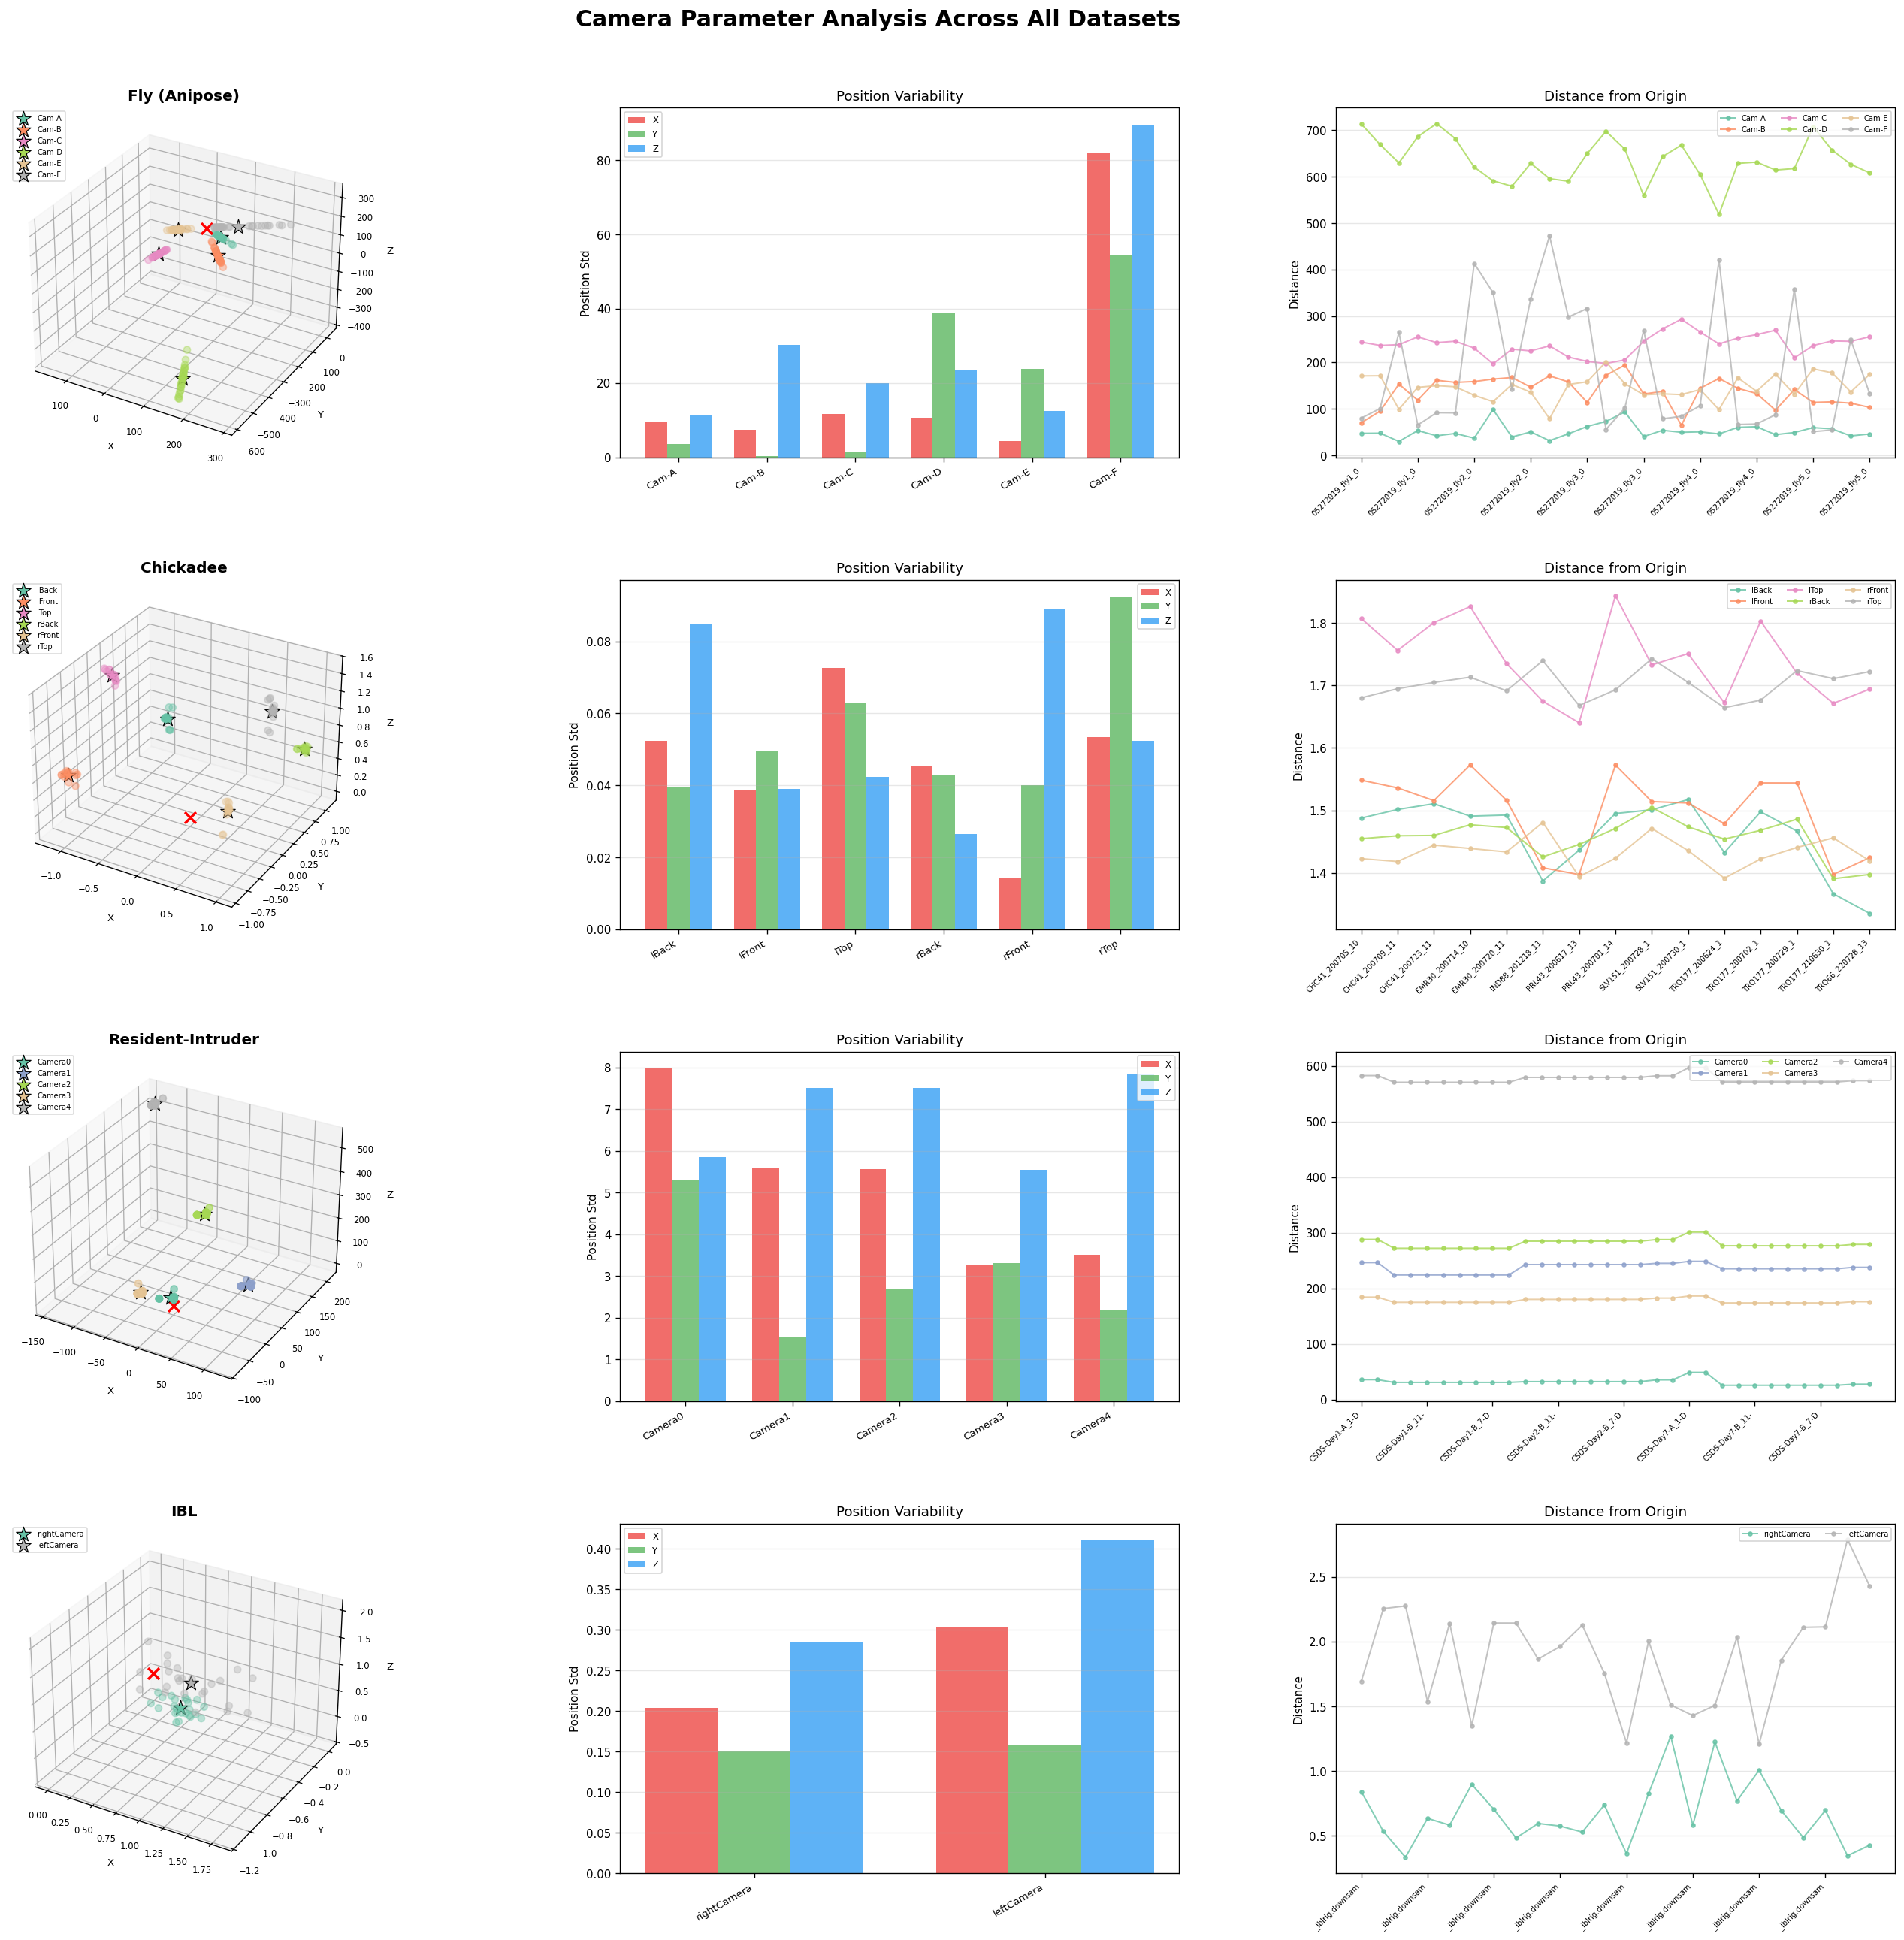

In [56]:
fig = plt.figure(figsize=(24, 22))
outer_gs = gridspec.GridSpec(4, 3, hspace=0.35, wspace=0.28,
                              left=0.05, right=0.97, top=0.93, bottom=0.04)

for row_idx, (ds_name, ds_cfg) in enumerate(DATASETS.items()):
    params = all_params[ds_name]
    sessions = sorted(params.keys())
    cam_names = list(params[sessions[0]]['cameras'].keys())
    n_cams = len(cam_names)
    cam_cmap = plt.cm.Set2 if n_cams <= 8 else plt.cm.tab20
    cam_colors = [cam_cmap(i / max(n_cams - 1, 1)) for i in range(n_cams)]
    metrics = all_metrics[ds_name]

    # Col 0: 3D scatter
    ax3d = fig.add_subplot(outer_gs[row_idx, 0], projection='3d')
    for j, cam_name in enumerate(cam_names):
        positions = np.array([
            params[s]['cameras'][cam_name]['camera_position']
            for s in sessions if cam_name in params[s]['cameras']
        ])
        ax3d.scatter(positions[:, 0], positions[:, 1], positions[:, 2],
                     c=[cam_colors[j]], s=30, alpha=0.4)
        mean_pos = positions.mean(axis=0)
        ax3d.scatter(mean_pos[0], mean_pos[1], mean_pos[2],
                     c=[cam_colors[j]], s=150, marker='*', edgecolors='k',
                     linewidths=0.7, label=cam_name)
    ax3d.scatter(0, 0, 0, c='red', s=80, marker='x', linewidths=2)
    ax3d.set_xlabel('X', fontsize=8); ax3d.set_ylabel('Y', fontsize=8); ax3d.set_zlabel('Z', fontsize=8)
    ax3d.set_title(f"{ds_cfg['display_name']}", fontsize=12, fontweight='bold')
    ax3d.legend(fontsize=6, loc='upper left', framealpha=0.7)
    ax3d.tick_params(labelsize=7)

    # Col 1: Position variability bars
    ax_bar = fig.add_subplot(outer_gs[row_idx, 1])
    x = np.arange(n_cams)
    width = 0.25
    ax_bar.bar(x - width, metrics['pos_x_std'], width, label='X', color='#EF5350', alpha=0.85)
    ax_bar.bar(x, metrics['pos_y_std'], width, label='Y', color='#66BB6A', alpha=0.85)
    ax_bar.bar(x + width, metrics['pos_z_std'], width, label='Z', color='#42A5F5', alpha=0.85)
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(cam_names, rotation=30, ha='right', fontsize=8)
    ax_bar.set_ylabel('Position Std', fontsize=9)
    ax_bar.set_title('Position Variability', fontsize=11)
    ax_bar.legend(fontsize=7)
    ax_bar.grid(axis='y', alpha=0.3)

    # Col 2: Distance from origin across sessions
    ax_dist = fig.add_subplot(outer_gs[row_idx, 2])
    for j, cam_name in enumerate(cam_names):
        dists = [
            params[s]['cameras'].get(cam_name, {}).get('distance_from_origin', np.nan)
            for s in sessions
        ]
        ax_dist.plot(range(len(sessions)), dists, 'o-', label=cam_name,
                     color=cam_colors[j], alpha=0.8, markersize=3, linewidth=1.2)
    ax_dist.set_ylabel('Distance', fontsize=9)
    ax_dist.set_title('Distance from Origin', fontsize=11)
    ax_dist.set_xticks(range(0, len(sessions), max(1, len(sessions) // 8)))
    ax_dist.set_xticklabels(
        [sessions[i][:15] for i in range(0, len(sessions), max(1, len(sessions) // 8))],
        rotation=45, ha='right', fontsize=6)
    ax_dist.legend(fontsize=6, ncol=min(n_cams, 3), loc='upper right')
    ax_dist.grid(axis='y', alpha=0.3)

fig.suptitle('Camera Parameter Analysis Across All Datasets',
             fontsize=18, fontweight='bold')
# plt.savefig('camera_params_all_datasets_combined.png', bbox_inches='tight')
plt.show()

## Reprojection error (multiview triangulation consistency)

We load **2D labels** per view, align frames across cameras using the same keys as in `calibrations.csv`, then **triangulate** with `aniposelib` and **reproject** to each camera. Per-pixel error is \(\sqrt{(x-x')^2+(y-y')^2}\) on labeled pixels only.

**Which CSVs:** For **chickadee-crop**, **`remapped_CollectedData_<view>.csv`** is **required** (full-image / uncropped coordinates, matching calibration). Optional **`remapped_CollectedData_<view>_new.csv`** is concatenated when present, like `merge_collected_and_calibrations.py`. For other datasets, if `remapped_CollectedData_<view>.csv` exists and `REPROJ_PREFER_REMAPPED` is True, we use it; otherwise we use **`CollectedData_<view>.csv`** (+ optional `*_new`) and add **`bboxes_<view>.csv`** offsets for **chickadee-crop** and **rat7m-crop** (crop space). Tune **`REPROJ_REQUIRE_REMAPPED`** / **`REPROJ_PREFER_REMAPPED`** in the code cell below.

Plots follow `Camera_param_analysis.ipynb`: error by session, distribution, by camera, by keypoint, heatmaps (session×camera, session×keypoint, camera×keypoint), plus summary statistics.

In [16]:
import re
import yaml
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
from typing import Dict, List, Tuple, Optional

from tqdm import tqdm
from lightning_pose.utils.io import fix_empty_first_row
from aniposelib.cameras import CameraGroup

CFG_ROOT = Path("/teamspace/studios/this_studio/lp3d-analysis/configs")

DATASET_CFG_FILES = {
    "fly-anipose": CFG_ROOT / "config_fly-anipose.yaml",
    "chickadee-crop": CFG_ROOT / "config_chickadee-crop.yaml",
    "two-mouse": CFG_ROOT / "config_two-mouse.yaml",
    "rat7m-crop": CFG_ROOT / "config_rat7m-crop.yaml",
}

# remapped_* = full-image (uncropped) coords. CollectedData_* = crop coords (needs bboxes for chickadee/rat7m).
REPROJ_REQUIRE_REMAPPED = frozenset({"chickadee-crop"})
REPROJ_PREFER_REMAPPED = True


def load_view_names_and_keypoints(ds_name: str) -> Tuple[List[str], List[str]]:
    cfg_path = DATASET_CFG_FILES[ds_name]
    with open(cfg_path) as f:
        cfg = yaml.safe_load(f)
    d = cfg["data"]
    return list(d["view_names"]), list(d["keypoint_names"])


def _probe_remapped_exists(data_dir: Path, view: str) -> bool:
    return (data_dir / f"remapped_CollectedData_{view}.csv").is_file()


def use_remapped_labels(data_dir: Path, ds_name: str, view_names: List[str]) -> bool:
    if ds_name in REPROJ_REQUIRE_REMAPPED:
        if not _probe_remapped_exists(data_dir, view_names[0]):
            raise FileNotFoundError(
                f"{ds_name}: expected remapped labels at "
                f"{data_dir / ('remapped_CollectedData_' + view_names[0] + '.csv')} "
                f"(full-image coordinates). Generate remapped CSVs or remove dataset from REPROJ_REQUIRE_REMAPPED."
            )
        return True
    if REPROJ_PREFER_REMAPPED and _probe_remapped_exists(data_dir, view_names[0]):
        return True
    return False


def load_collected_stacked(data_dir: Path, view: str, remapped: bool) -> pd.DataFrame:
    """One view: base CSV + optional *_new (same as merge_collected_and_calibrations)."""
    if remapped:
        a = data_dir / f"remapped_CollectedData_{view}.csv"
        b = data_dir / f"remapped_CollectedData_{view}_new.csv"
    else:
        a = data_dir / f"CollectedData_{view}.csv"
        b = data_dir / f"CollectedData_{view}_new.csv"
    if not a.is_file():
        raise FileNotFoundError(a)
    d1 = pd.read_csv(a, header=[0, 1, 2], index_col=0)
    d1 = fix_empty_first_row(d1)
    if b.is_file():
        d2 = pd.read_csv(b, header=[0, 1, 2], index_col=0)
        d2 = fix_empty_first_row(d2)
        if not d1.columns.equals(d2.columns):
            raise ValueError(f"Column mismatch between {a} and {b}")
        return pd.concat([d1, d2], axis=0)
    return d1


def dataset_needs_bbox(ds_name: str, labels_are_remapped: bool) -> bool:
    if labels_are_remapped:
        return False
    return ds_name in ("chickadee-crop", "rat7m-crop")


def canonical_frame_key(img_path: str, ds_name: str) -> Tuple[str, str]:
    """Map image paths from calibrations / CollectedData to a common (session, filename) key."""
    p = Path(img_path)
    parent = p.parent.name
    fname = p.name
    if ds_name == "fly-anipose":
        norm = re.sub(r"_Cam-[A-F]_", "_", parent)
    elif ds_name == "chickadee-crop":
        norm = re.sub(r"_(lBack|lFront|lTop|rBack|rFront|rTop)$", "", parent)
    elif ds_name == "two-mouse":
        norm = re.sub(r"_Camera\d+$", "", parent)
    elif ds_name == "rat7m-crop":
        norm = re.sub(r"_camera\d+$", "", parent, flags=re.IGNORECASE)
    else:
        norm = parent
    return (norm, fname)


def load_bbox_offset_maps(data_dir: Path, view_names: List[str]) -> List[Optional[Dict[str, Tuple[float, float]]]]:
    """Per view: map CollectedData index string -> (x, y) top-left of crop in full image."""
    maps: List[Optional[Dict[str, Tuple[float, float]]]] = []
    for v in view_names:
        bbox_path = data_dir / f"bboxes_{v}.csv"
        if not bbox_path.exists():
            maps.append(None)
            continue
        df = pd.read_csv(bbox_path, index_col=0)
        m: Dict[str, Tuple[float, float]] = {}
        for ix, row in df.iterrows():
            m[str(ix)] = (float(row["x"]), float(row["y"]))
        maps.append(m)
    return maps


def apply_bbox_to_keypoints(
    kp_frame: np.ndarray,
    view_idx: int,
    img_index_str: str,
    bbox_maps: Optional[List[Optional[Dict[str, Tuple[float, float]]]]],
) -> np.ndarray:
    """kp_frame: (n_keypoints, 2) in crop space; return full-image coords if bbox exists."""
    out = kp_frame.copy()
    if bbox_maps is None or bbox_maps[view_idx] is None:
        return out
    bmap = bbox_maps[view_idx]
    if img_index_str not in bmap:
        return out
    ox, oy = bmap[img_index_str]
    out[:, 0] += ox
    out[:, 1] += oy
    return out


def build_session_data_multiview(
    ds_name: str,
    data_dir: Path,
    calibrations_csv: Path,
    view_names: List[str],
    n_keypoints: int,
    bbox_maps: Optional[List[Optional[Dict[str, Tuple[float, float]]]]],
    use_remapped: bool,
) -> Dict[str, Dict]:
    """session -> keypoints_2d (n_frames, n_views, n_kp, 2)."""
    calib_df = pd.read_csv(calibrations_csv, index_col=0)

    keypoints_by_view: List[np.ndarray] = []
    image_paths_by_view: List[List[str]] = []
    for view in view_names:
        df = load_collected_stacked(data_dir, view, remapped=use_remapped)
        kp = df.to_numpy().reshape(df.shape[0], -1, 2)
        if kp.shape[1] != n_keypoints:
            label_kind = "remapped" if use_remapped else "CollectedData"
            raise ValueError(f"{label_kind} {view}: expected {n_keypoints} keypoints, got {kp.shape[1]}")
        keypoints_by_view.append(kp)
        image_paths_by_view.append([str(x) for x in df.index.tolist()])

    n_views = len(keypoints_by_view)
    labeled_maps: List[Dict[Tuple[str, str], int]] = []
    for view_idx in range(n_views):
        vm: Dict[Tuple[str, str], int] = {}
        for i, img_path in enumerate(image_paths_by_view[view_idx]):
            vm[canonical_frame_key(img_path, ds_name)] = i
        labeled_maps.append(vm)

    sessions: Dict[str, List] = defaultdict(list)
    for img_path, row in calib_df.iterrows():
        sessions[row["file"]].append(img_path)

    session_data: Dict[str, Dict] = {}
    for calib_file, all_session_images in sessions.items():
        all_keys: List[Tuple[Tuple[str, str], str]] = []
        for img_path in all_session_images:
            k = canonical_frame_key(str(img_path), ds_name)
            all_keys.append((k, str(img_path)))

        if len(all_keys) == 0:
            continue

        n_frames = len(all_keys)
        session_keypoints = np.full((n_frames, n_views, n_keypoints, 2), np.nan)

        for frame_idx, (key, _original_calib_path) in enumerate(all_keys):
            for view_idx in range(n_views):
                if key not in labeled_maps[view_idx]:
                    continue
                label_idx = labeled_maps[view_idx][key]
                img_index_str = image_paths_by_view[view_idx][label_idx]
                kp = keypoints_by_view[view_idx][label_idx].copy()
                kp = apply_bbox_to_keypoints(kp, view_idx, img_index_str, bbox_maps)
                session_keypoints[frame_idx, view_idx] = kp

        session_data[calib_file] = {"keypoints_2d": session_keypoints}

    return session_data


def triangulate_and_reproject(keypoints_2d: np.ndarray, cam_group: CameraGroup):
    """
    Triangulate 2D -> 3D and reproject. Uses full (n_cams, 1, 2) arrays so camera indices stay aligned.
    fast=True only when all views have valid 2D for that keypoint.
    """
    n_frames, n_views, n_keypoints, _ = keypoints_2d.shape
    n_cams = len(cam_group.cameras)
    assert n_views == n_cams

    keypoints_3d = np.full((n_frames, n_keypoints, 3), np.nan)
    keypoints_2d_reproj = np.full((n_frames, n_views, n_keypoints, 2), np.nan)

    for frame_idx in range(n_frames):
        for kp_idx in range(n_keypoints):
            points_2d = keypoints_2d[frame_idx, :, kp_idx, :]
            valid_mask = ~np.isnan(points_2d).any(axis=1)
            if valid_mask.sum() < 2:
                continue
            pts_full = points_2d.reshape(n_cams, 1, 2)
            try:
                if bool(valid_mask.all()):
                    point_3d = cam_group.triangulate(pts_full, fast=True)
                else:
                    point_3d = cam_group.triangulate(pts_full, fast=False)
                if point_3d.ndim == 2:
                    point_3d = point_3d[0]
                keypoints_3d[frame_idx, kp_idx] = point_3d
                p2d = cam_group.project(point_3d.reshape(1, 3))
                keypoints_2d_reproj[frame_idx, :, kp_idx] = p2d[:, 0, :]
            except Exception:
                pass

    diff = keypoints_2d - keypoints_2d_reproj
    errors = np.sqrt(np.sum(diff**2, axis=-1))
    return keypoints_3d, keypoints_2d_reproj, errors


def run_reprojection_for_dataset(ds_name: str, data_root: str, valid_sessions: Optional[set]):
    """Triangulate/reproject every session that has a calibration file under data_root/ds_name."""
    data_dir = Path(data_root) / ds_name
    calib_csv = data_dir / "calibrations.csv"
    if not calib_csv.exists():
        calib_csv = data_dir / "calibrations_new.csv"

    view_names, keypoint_names = load_view_names_and_keypoints(ds_name)
    n_keypoints = len(keypoint_names)
    use_remapped = use_remapped_labels(data_dir, ds_name, view_names)
    if use_remapped:
        print(f"  [{ds_name}] Using remapped_CollectedData_* (full-image / uncropped coordinates)")
    else:
        print(f"  [{ds_name}] Using CollectedData_* + bboxes (crop space)")

    bbox_maps = None
    if dataset_needs_bbox(ds_name, use_remapped):
        bbox_maps = load_bbox_offset_maps(data_dir, view_names)

    session_data = build_session_data_multiview(
        ds_name, data_dir, calib_csv, view_names, n_keypoints, bbox_maps, use_remapped
    )

    session_results: Dict[str, Dict] = {}
    for calib_file, data in tqdm(
        list(session_data.items()),
        desc=f"{ds_name} sessions",
    ):
        session_name = Path(calib_file).stem
        if valid_sessions is not None and session_name not in valid_sessions:
            continue
        calib_path = data_dir / calib_file
        if not calib_path.exists():
            continue
        cam_group = CameraGroup.load(str(calib_path))
        k3, k2r, errors = triangulate_and_reproject(data["keypoints_2d"], cam_group)
        session_results[session_name] = {
            "errors": errors,
            "keypoints_2d": data["keypoints_2d"],
            "keypoints_2d_reproj": k2r,
            "keypoints_3d": k3,
            "cam_group": cam_group,
        }
    return session_results, view_names, keypoint_names


In [17]:
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt


def plot_reprojection_error_analysis(
    session_results: Dict,
    cam_names: List[str],
    keypoint_names: List[str],
    figsize: Tuple[int, int] = (24, 20),
    title_prefix: str = "",
):
    """
    Detailed reprojection error analysis plots (from Camera_param_analysis.ipynb).
    """
    n_views = len(cam_names)
    n_keypoints = len(keypoint_names)
    session_names = list(session_results.keys())
    n_sessions = len(session_names)

    all_errors = []
    errors_by_session = {}
    errors_by_camera = {cam: [] for cam in cam_names}
    errors_by_keypoint = {kp: [] for kp in keypoint_names}
    errors_by_session_camera = {s: {cam: [] for cam in cam_names} for s in session_names}
    errors_by_session_keypoint = {s: {kp: [] for kp in keypoint_names} for s in session_names}

    for session_name, results in session_results.items():
        err = results["errors"]
        valid_err = err[~np.isnan(err)]
        all_errors.extend(valid_err.tolist())
        errors_by_session[session_name] = valid_err.tolist()

        for v_idx, cam in enumerate(cam_names):
            view_err = err[:, v_idx, :].flatten()
            valid_view_err = view_err[~np.isnan(view_err)].tolist()
            errors_by_camera[cam].extend(valid_view_err)
            errors_by_session_camera[session_name][cam] = valid_view_err

        for kp_idx, kp in enumerate(keypoint_names):
            kp_err = err[:, :, kp_idx].flatten()
            valid_kp_err = kp_err[~np.isnan(kp_err)].tolist()
            errors_by_keypoint[kp].extend(valid_kp_err)
            errors_by_session_keypoint[session_name][kp] = valid_kp_err

    fig = plt.figure(figsize=figsize)

    ax1 = fig.add_subplot(3, 3, 1)
    session_means = [np.mean(errors_by_session[s]) if errors_by_session[s] else 0 for s in session_names]
    session_stds = [np.std(errors_by_session[s]) if errors_by_session[s] else 0 for s in session_names]

    colors = plt.cm.tab20(np.linspace(0, 1, max(n_sessions, 1)))
    x_pos = np.arange(n_sessions)
    ax1.bar(x_pos, session_means, yerr=session_stds, capsize=3, alpha=0.8, color=colors)
    ax1.axhline(
        np.mean(all_errors),
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Overall Mean: {np.mean(all_errors):.2f}",
    )
    ax1.set_ylabel("Reprojection Error (px)")
    ax1.set_title("Reprojection Error by Session")
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels([s[:15] for s in session_names], rotation=45, ha="right", fontsize=7)
    ax1.legend()
    ax1.grid(axis="y", alpha=0.3)

    ax2 = fig.add_subplot(3, 3, 2)
    ax2.hist(all_errors, bins=100, alpha=0.7, color="steelblue", edgecolor="black", density=True)
    ax2.axvline(np.mean(all_errors), color="red", linestyle="--", linewidth=2, label=f"Mean: {np.mean(all_errors):.2f}")
    ax2.axvline(
        np.median(all_errors), color="orange", linestyle="--", linewidth=2, label=f"Median: {np.median(all_errors):.2f}"
    )
    ax2.axvline(
        np.percentile(all_errors, 95),
        color="green",
        linestyle=":",
        linewidth=2,
        label=f"95th %ile: {np.percentile(all_errors, 95):.2f}",
    )
    ax2.set_xlabel("Reprojection Error (px)")
    ax2.set_ylabel("Density")
    ax2.set_title("Distribution of All Reprojection Errors")
    ax2.legend()
    ax2.grid(axis="y", alpha=0.3)

    ax3 = fig.add_subplot(3, 3, 3)
    cam_data = [errors_by_camera[cam] for cam in cam_names]
    cam_colors = plt.cm.Set2(np.linspace(0, 1, max(n_views, 1)))
    bp = ax3.boxplot(cam_data, patch_artist=True, labels=cam_names)
    for patch, color in zip(bp["boxes"], cam_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax3.set_ylabel("Reprojection Error (px)")
    ax3.set_title("Reprojection Error by Camera View")
    ax3.tick_params(axis="x", rotation=45)
    ax3.grid(axis="y", alpha=0.3)

    ax4 = fig.add_subplot(3, 3, 4)
    kp_data = [errors_by_keypoint[kp] for kp in keypoint_names]
    kp_colors = plt.cm.tab20(np.linspace(0, 1, max(n_keypoints, 1)))
    bp = ax4.boxplot(kp_data, patch_artist=True)
    for patch, color in zip(bp["boxes"], kp_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax4.set_ylabel("Reprojection Error (px)")
    ax4.set_title("Reprojection Error by Keypoint")
    ax4.set_xticks(range(1, n_keypoints + 1))
    ax4.set_xticklabels(keypoint_names, rotation=90, fontsize=6)
    ax4.grid(axis="y", alpha=0.3)

    ax5 = fig.add_subplot(3, 3, 5)
    kp_means = [(kp, np.mean(errors_by_keypoint[kp])) for kp in keypoint_names if errors_by_keypoint[kp]]
    kp_means_sorted = sorted(kp_means, key=lambda x: x[1], reverse=True)
    kp_names_sorted = [x[0] for x in kp_means_sorted]
    kp_vals_sorted = [x[1] for x in kp_means_sorted]

    ax5.barh(range(len(kp_names_sorted)), kp_vals_sorted, alpha=0.8, color="coral")
    ax5.set_yticks(range(len(kp_names_sorted)))
    ax5.set_yticklabels(kp_names_sorted, fontsize=6)
    ax5.set_xlabel("Mean Reprojection Error (px)")
    ax5.set_title("Keypoints Ranked by Mean Error")
    ax5.axvline(np.mean(all_errors), color="red", linestyle="--", label="Overall Mean")
    ax5.legend()
    ax5.grid(axis="x", alpha=0.3)

    ax6 = fig.add_subplot(3, 3, 6)
    cam_means = [np.mean(errors_by_camera[cam]) for cam in cam_names]
    cam_stds = [np.std(errors_by_camera[cam]) for cam in cam_names]
    ax6.bar(range(n_views), cam_means, yerr=cam_stds, capsize=5, alpha=0.8, color=cam_colors)
    ax6.set_ylabel("Reprojection Error (px)")
    ax6.set_title("Mean Error by Camera (with Std)")
    ax6.set_xticks(range(n_views))
    ax6.set_xticklabels(cam_names, rotation=45, ha="right")
    ax6.axhline(np.mean(all_errors), color="red", linestyle="--", label="Overall Mean")
    ax6.legend()
    ax6.grid(axis="y", alpha=0.3)

    ax7 = fig.add_subplot(3, 3, 7)
    session_cam_matrix = np.zeros((n_sessions, n_views))
    for i, s in enumerate(session_names):
        for j, cam in enumerate(cam_names):
            if errors_by_session_camera[s][cam]:
                session_cam_matrix[i, j] = np.mean(errors_by_session_camera[s][cam])
            else:
                session_cam_matrix[i, j] = np.nan

    im = ax7.imshow(session_cam_matrix, aspect="auto", cmap="YlOrRd")
    ax7.set_xticks(range(n_views))
    ax7.set_xticklabels(cam_names, rotation=45, ha="right")
    ax7.set_yticks(range(n_sessions))
    ax7.set_yticklabels([s[:15] for s in session_names], fontsize=7)
    ax7.set_title("Mean Error: Session × Camera")
    plt.colorbar(im, ax=ax7, label="Error (px)")

    ax8 = fig.add_subplot(3, 3, 8)
    session_kp_matrix = np.zeros((n_sessions, n_keypoints))
    for i, s in enumerate(session_names):
        for j, kp in enumerate(keypoint_names):
            if errors_by_session_keypoint[s][kp]:
                session_kp_matrix[i, j] = np.mean(errors_by_session_keypoint[s][kp])
            else:
                session_kp_matrix[i, j] = np.nan

    im = ax8.imshow(session_kp_matrix, aspect="auto", cmap="YlOrRd")
    ax8.set_xticks(range(n_keypoints))
    ax8.set_xticklabels(keypoint_names, rotation=90, fontsize=5)
    ax8.set_yticks(range(n_sessions))
    ax8.set_yticklabels([s[:15] for s in session_names], fontsize=7)
    ax8.set_title("Mean Error: Session × Keypoint")
    plt.colorbar(im, ax=ax8, label="Error (px)")

    ax9 = fig.add_subplot(3, 3, 9)
    cam_kp_matrix = np.zeros((n_views, n_keypoints))

    for v_idx, cam in enumerate(cam_names):
        for kp_idx, kp in enumerate(keypoint_names):
            all_vals = []
            for _session_name, results in session_results.items():
                err = results["errors"][:, v_idx, kp_idx]
                valid = err[~np.isnan(err)]
                all_vals.extend(valid.tolist())
            if all_vals:
                cam_kp_matrix[v_idx, kp_idx] = np.mean(all_vals)
            else:
                cam_kp_matrix[v_idx, kp_idx] = np.nan

    im = ax9.imshow(cam_kp_matrix, aspect="auto", cmap="YlOrRd")
    ax9.set_xticks(range(n_keypoints))
    ax9.set_xticklabels(keypoint_names, rotation=90, fontsize=5)
    ax9.set_yticks(range(n_views))
    ax9.set_yticklabels(cam_names)
    ax9.set_title("Mean Error: Camera × Keypoint")
    plt.colorbar(im, ax=ax9, label="Error (px)")

    plt.suptitle(f"{title_prefix}Reprojection Error Analysis", fontsize=16, fontweight="bold", y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

    print("\n" + "=" * 80)
    print("REPROJECTION ERROR SUMMARY")
    print("=" * 80)
    print(f"Total valid measurements: {len(all_errors)}")
    print(f"Mean error: {np.mean(all_errors):.3f} px")
    print(f"Median error: {np.median(all_errors):.3f} px")
    print(f"Std error: {np.std(all_errors):.3f} px")
    print(f"95th percentile: {np.percentile(all_errors, 95):.3f} px")
    print(f"Max error: {np.max(all_errors):.3f} px")

    return {
        "all_errors": all_errors,
        "errors_by_session": errors_by_session,
        "errors_by_camera": errors_by_camera,
        "errors_by_keypoint": errors_by_keypoint,
        "session_cam_matrix": session_cam_matrix,
        "session_kp_matrix": session_kp_matrix,
        "cam_kp_matrix": cam_kp_matrix,
    }



Reprojection: Fly (Anipose) (fly-anipose)
  [fly-anipose] Using CollectedData_* + bboxes (crop space)


fly-anipose sessions: 100%|██████████| 16/16 [00:08<00:00,  1.81it/s]


  Sessions with finite mean error: 16 / 16

Reprojection: Chickadee (chickadee-crop)
  [chickadee-crop] Using remapped_CollectedData_* (full-image / uncropped coordinates)


chickadee-crop sessions: 100%|██████████| 11/11 [00:06<00:00,  1.72it/s]


  Sessions with finite mean error: 11 / 11

Reprojection: Resident-Intruder (two-mouse)
  [two-mouse] Using CollectedData_* + bboxes (crop space)


two-mouse sessions: 100%|██████████| 32/32 [01:20<00:00,  2.50s/it]


  Sessions with finite mean error: 32 / 32

Reprojection: Rat7M (rat7m-crop)
  [rat7m-crop] Using CollectedData_* + bboxes (crop space)


rat7m-crop sessions: 100%|██████████| 5/5 [00:05<00:00,  1.10s/it]


  Sessions with finite mean error: 5 / 5


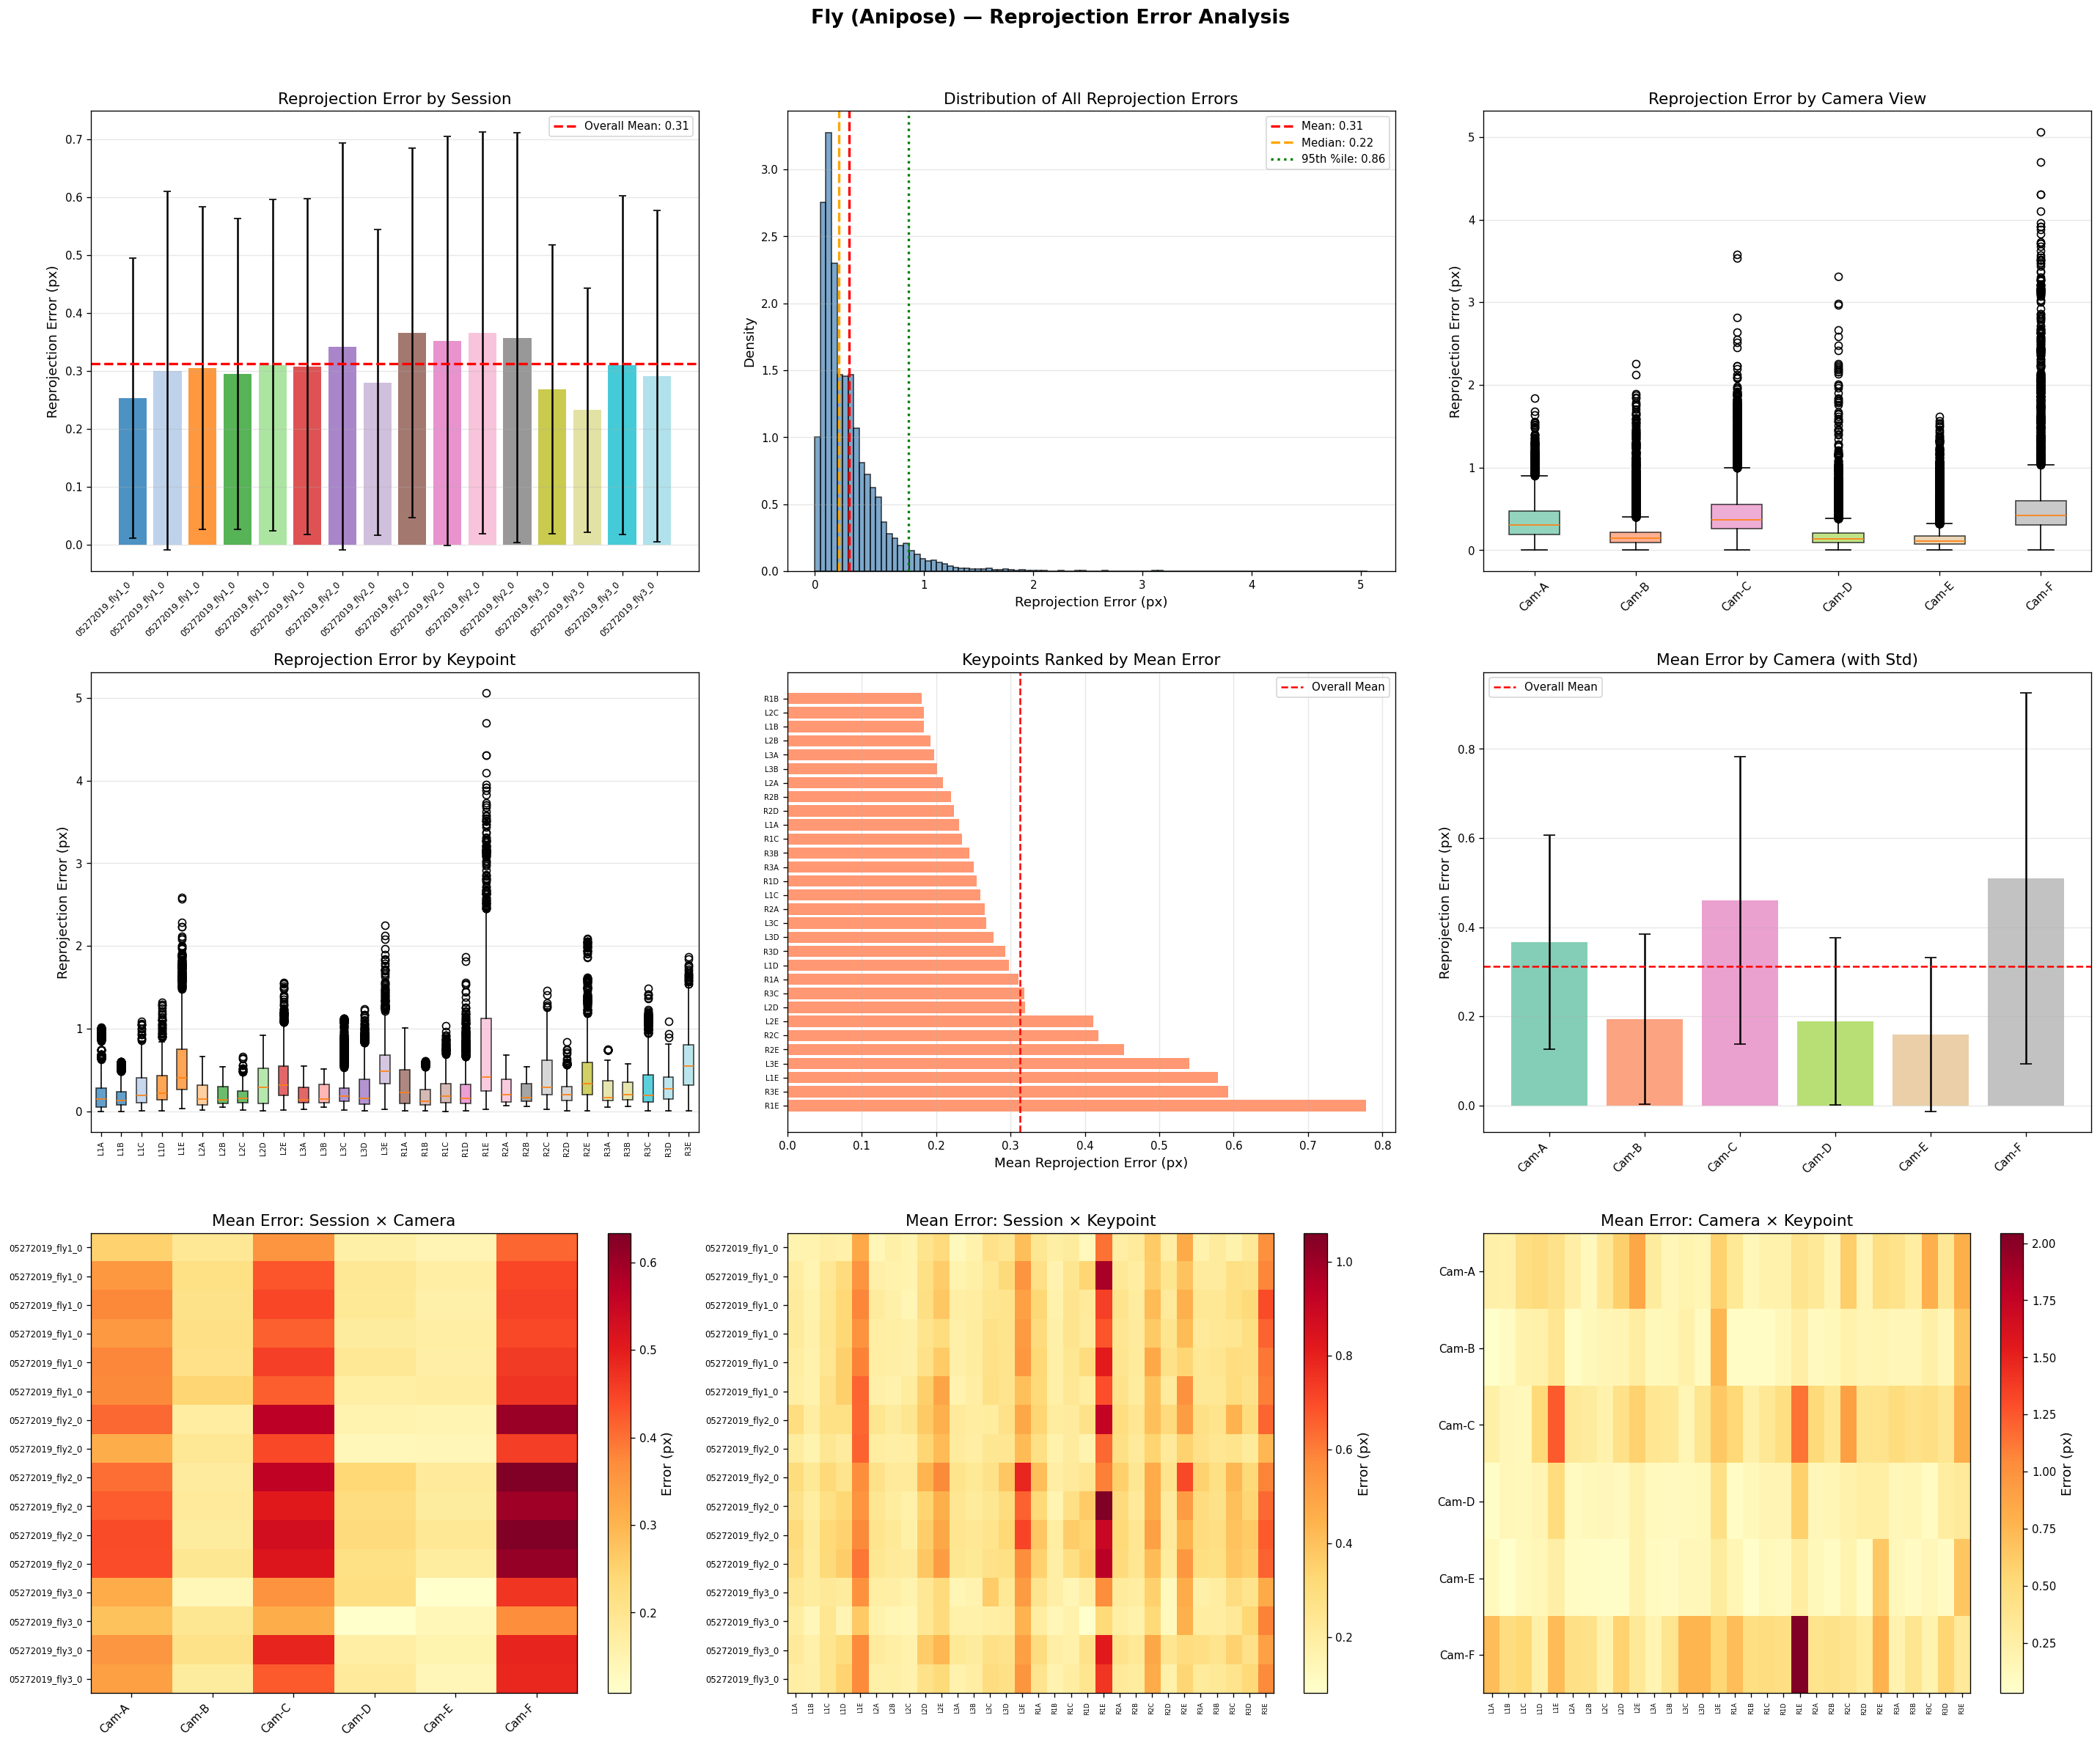


REPROJECTION ERROR SUMMARY
Total valid measurements: 67860
Mean error: 0.313 px
Median error: 0.218 px
Std error: 0.303 px
95th percentile: 0.858 px
Max error: 5.061 px


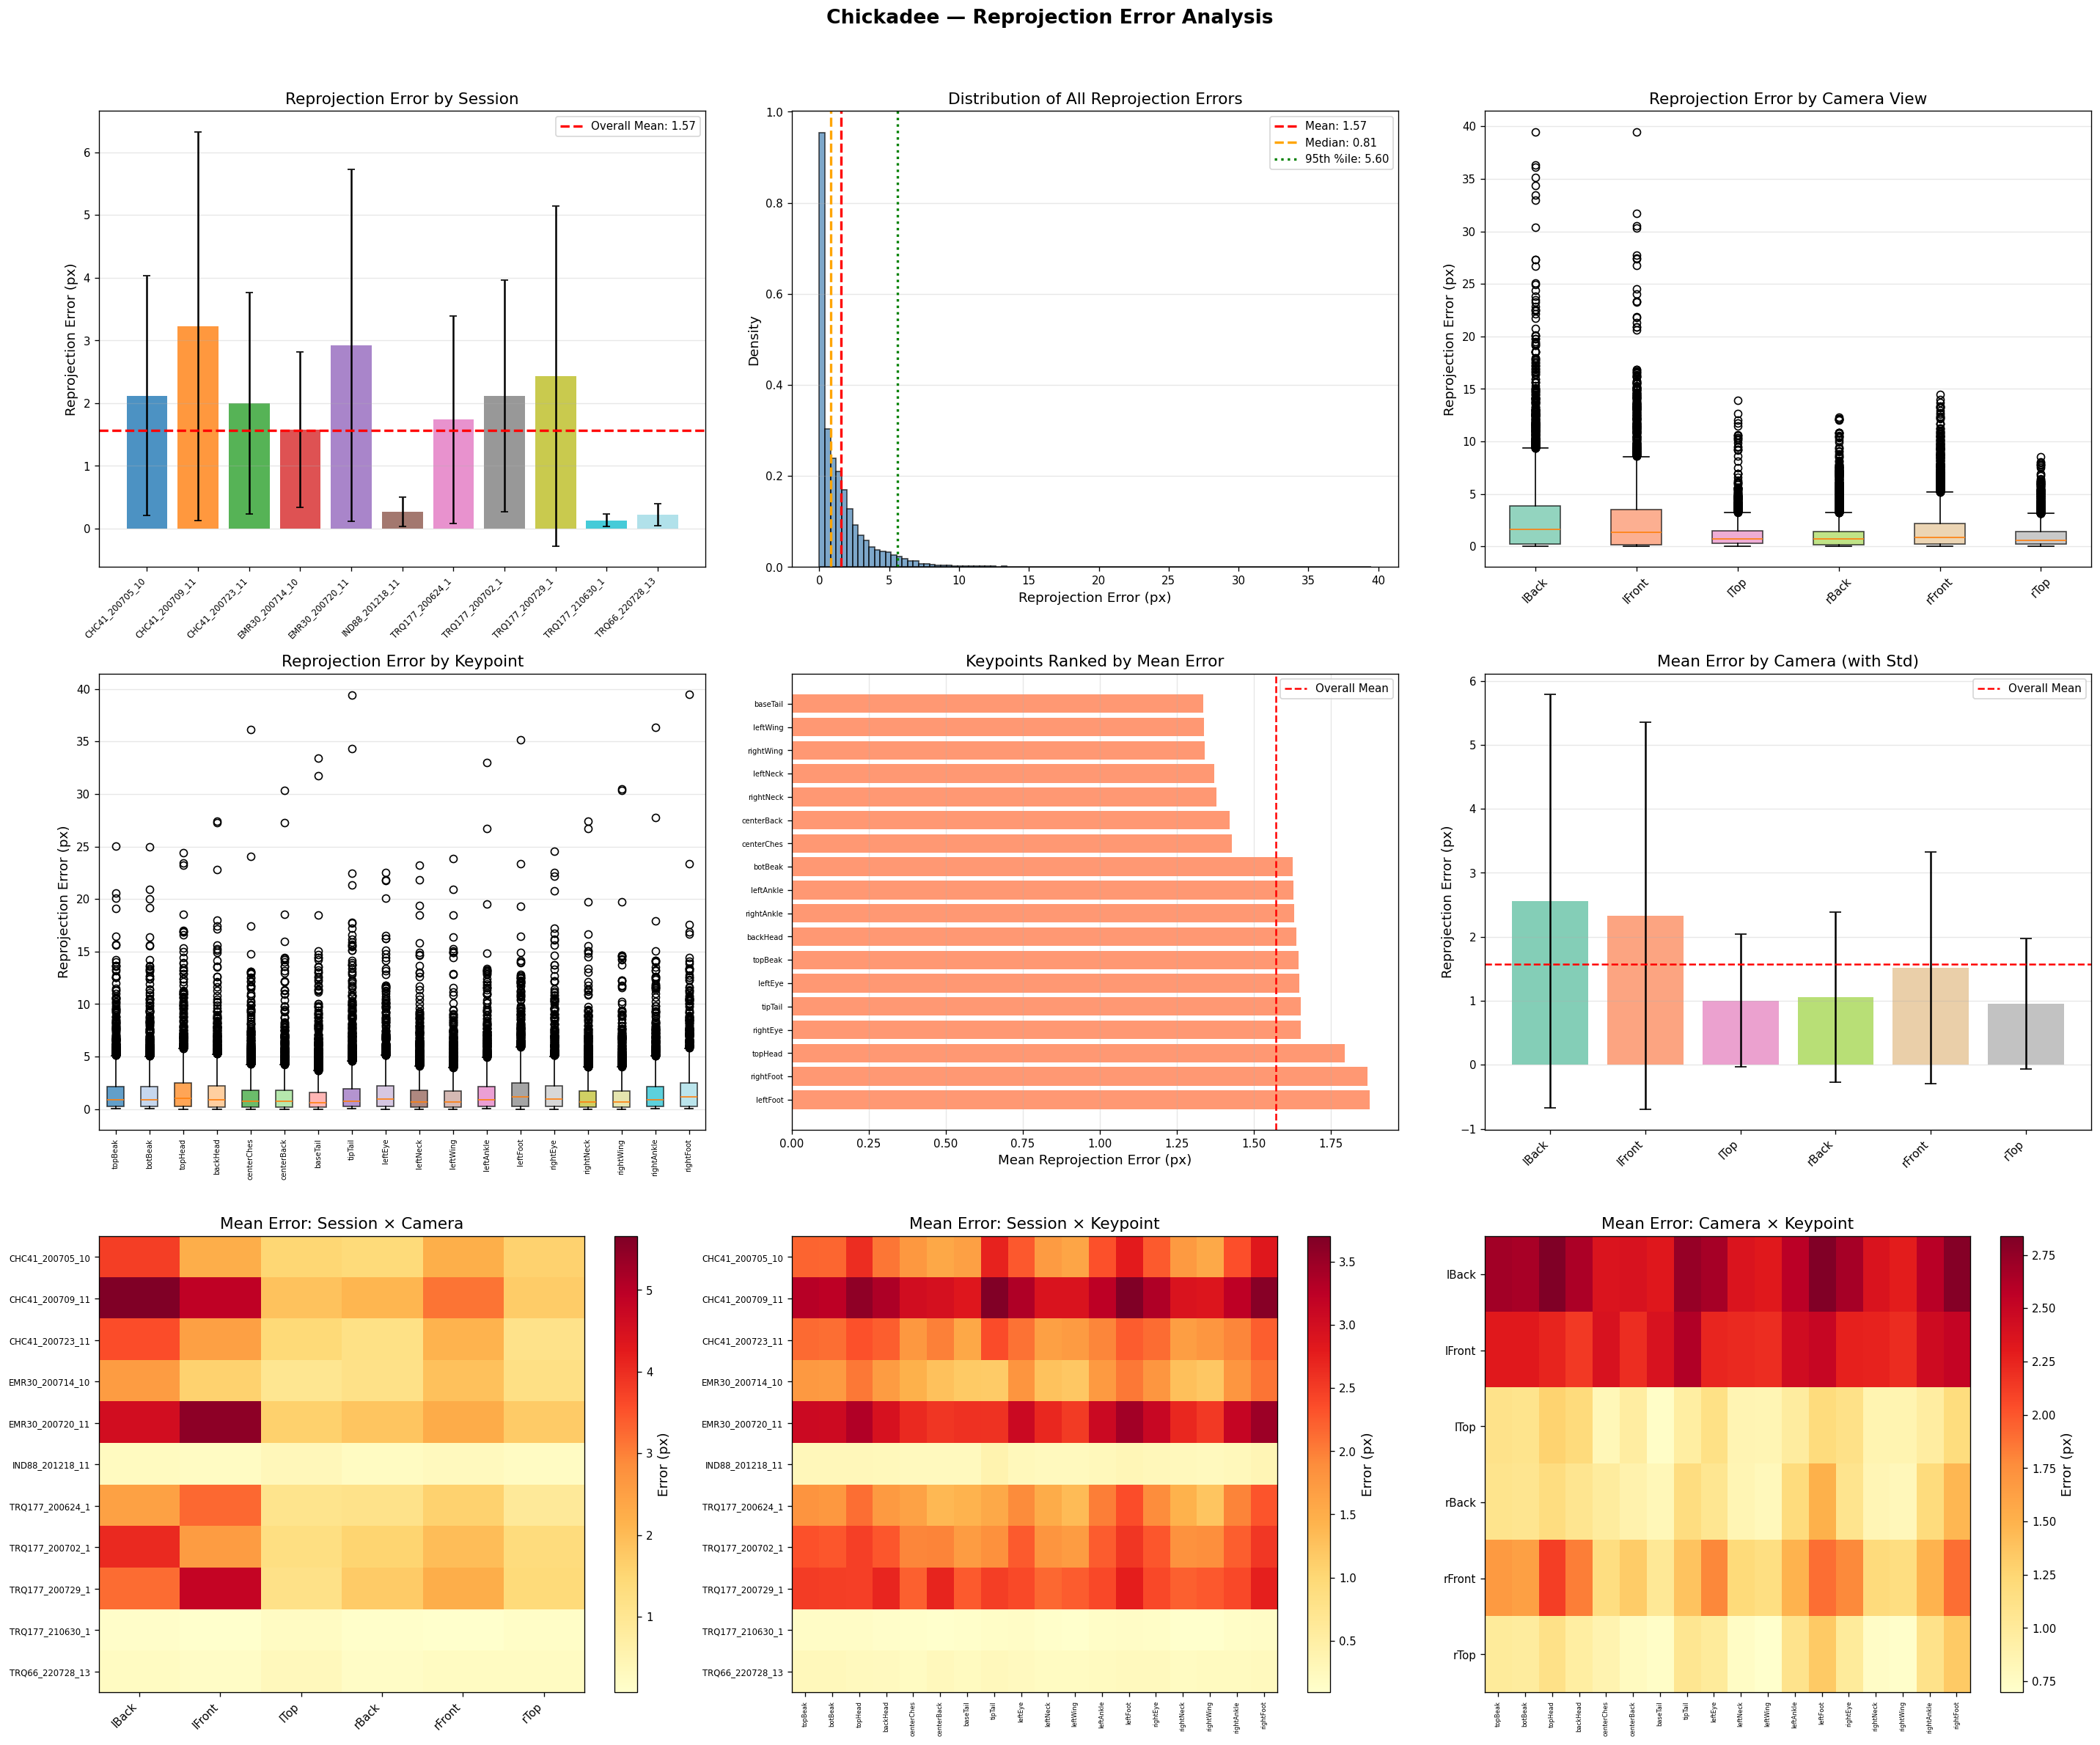


REPROJECTION ERROR SUMMARY
Total valid measurements: 44928
Mean error: 1.570 px
Median error: 0.805 px
Std error: 2.207 px
95th percentile: 5.601 px
Max error: 39.485 px


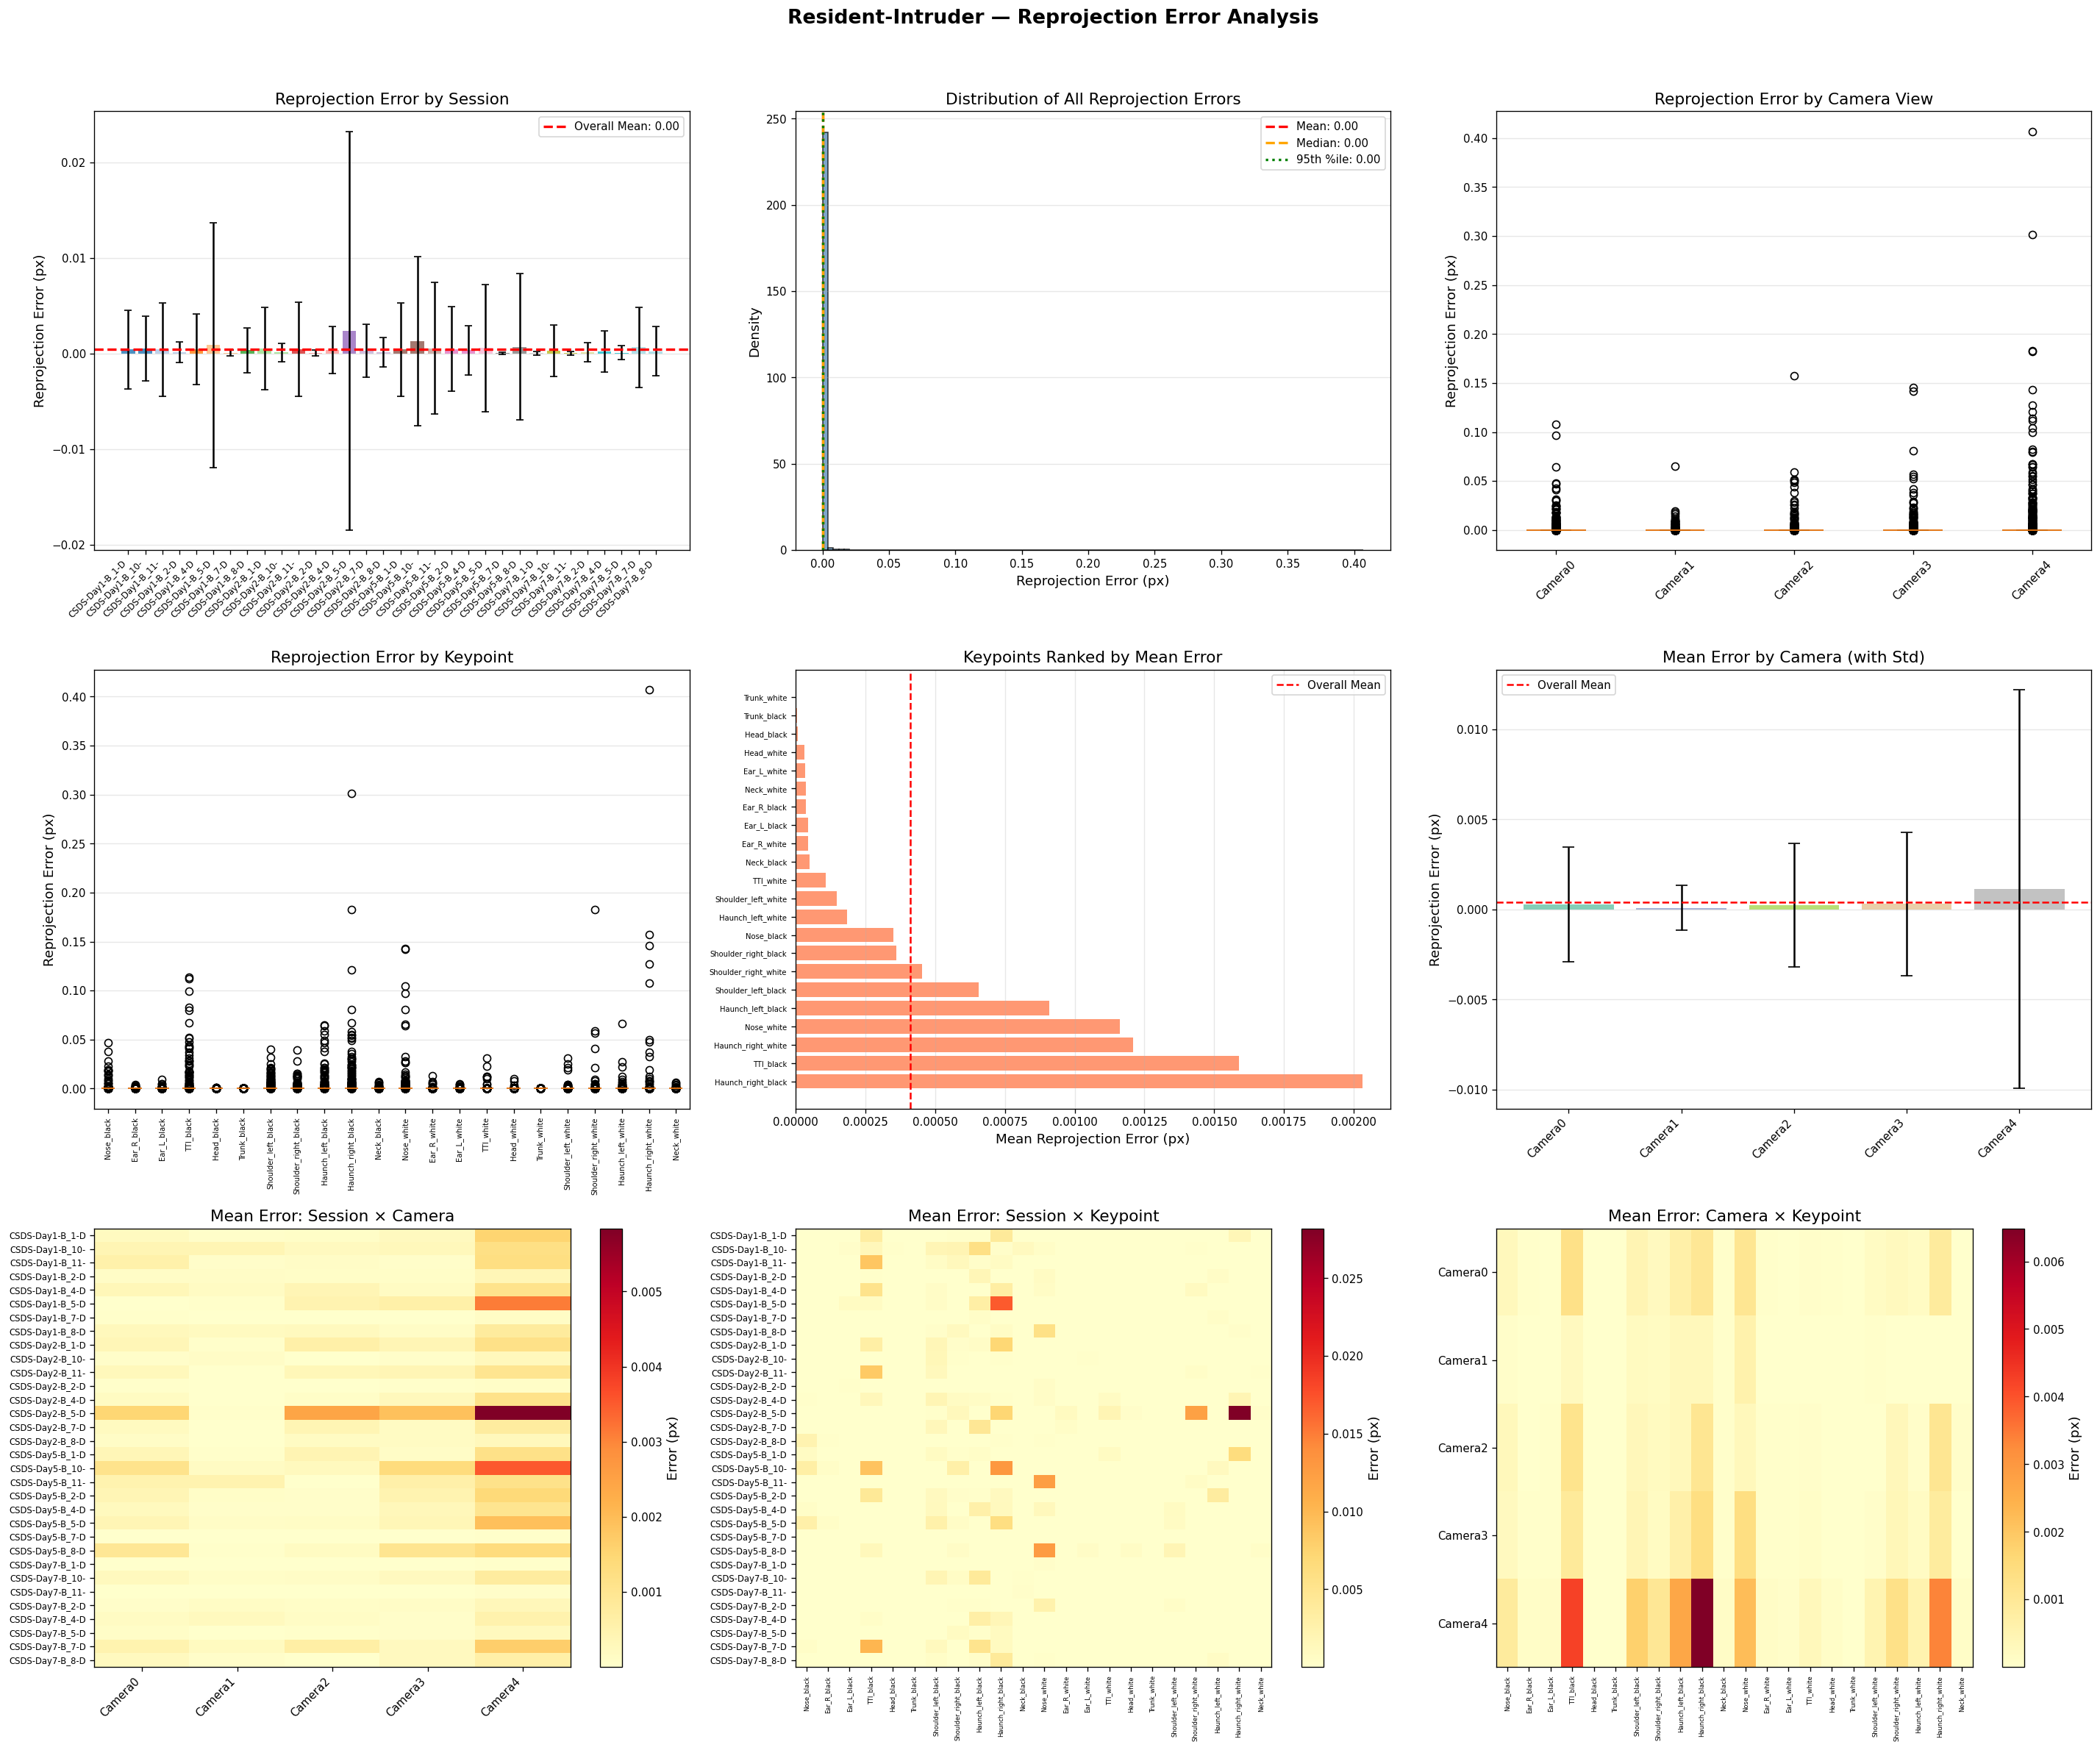


REPROJECTION ERROR SUMMARY
Total valid measurements: 21398
Mean error: 0.000 px
Median error: 0.000 px
Std error: 0.006 px
95th percentile: 0.000 px
Max error: 0.407 px


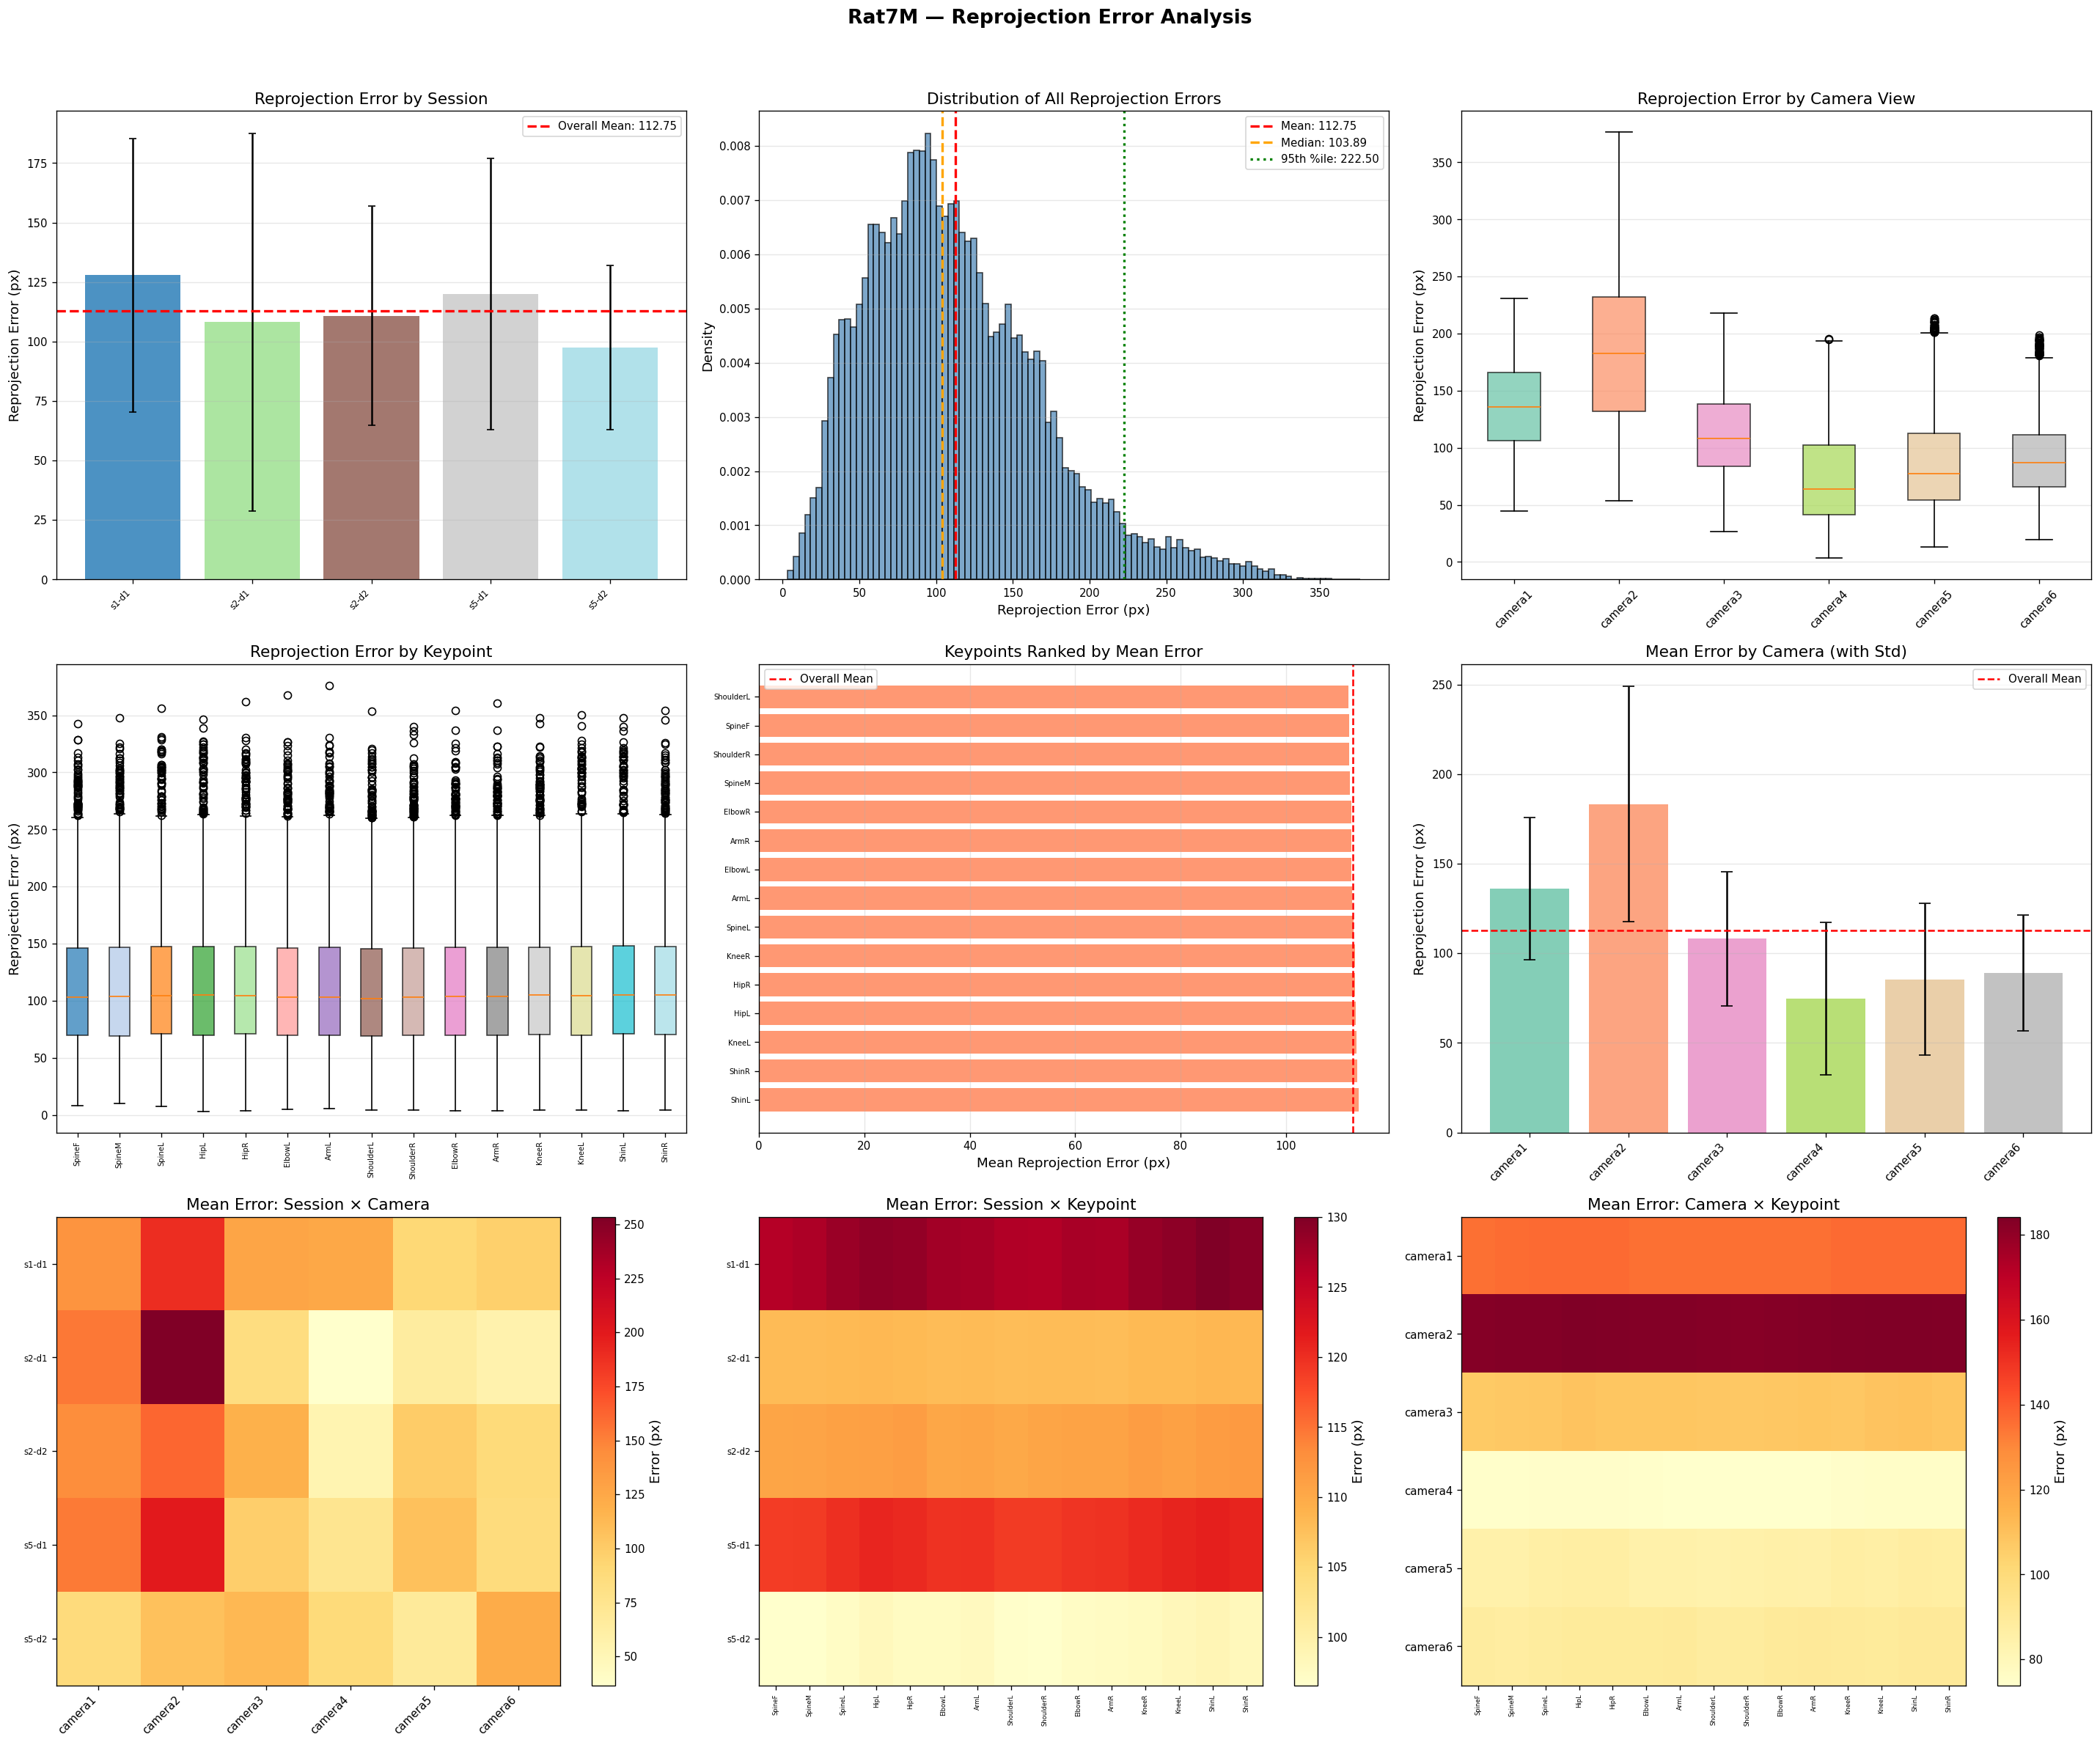


REPROJECTION ERROR SUMMARY
Total valid measurements: 41040
Mean error: 112.750 px
Median error: 103.891 px
Std error: 58.089 px
95th percentile: 222.504 px
Max error: 376.358 px

Per-session mean reprojection error (px) — sorted within dataset:

          dataset                                session    mean_px    median_px  n_px
        Chickadee                   TRQ177_210630_132311   0.129464 1.026677e-01  6156
        Chickadee                    TRQ66_220728_132027   0.227029 1.889066e-01  3348
        Chickadee                    IND88_201218_112623   0.271729 2.148046e-01  7776
        Chickadee                    EMR30_200714_104454   1.579323 1.287995e+00  2808
        Chickadee                   TRQ177_200624_112234   1.739828 1.288695e+00  2916
        Chickadee                    CHC41_200723_110437   1.995490 1.459627e+00  2592
        Chickadee                   TRQ177_200702_135920   2.116941 1.523880e+00  2916
        Chickadee                    CHC41_200705_105803 

,dataset,session,mean_px,median_px,n_px
25,Chickadee,TRQ177_210630_132311,0.129464,1.026677e-01,6156
26,Chickadee,TRQ66_220728_132027,0.227029,1.889066e-01,3348
21,Chickadee,IND88_201218_112623,0.271729,2.148046e-01,7776
19,Chickadee,EMR30_200714_104454,1.579323,1.287995e+00,2808
22,Chickadee,TRQ177_200624_112234,1.739828,1.288695e+00,2916
...,...,...,...,...,...
57,Resident-Intruder,CSDS-Day7-B_7-Defeat,0.000643,2.909092e-07,616
50,Resident-Intruder,CSDS-Day5-B_8-Defeat,0.000699,3.695581e-07,721
32,Resident-Intruder,CSDS-Day1-B_5-Defeat,0.000875,1.903304e-07,608
44,Resident-Intruder,CSDS-Day5-B_10-Defeat,0.001300,8.364008e-07,532


In [18]:
# Run reprojection for all datasets in DATASETS (same sessions as calibrations.csv filtering above)
all_reproj_results: Dict[str, Dict[str, Dict]] = {}
all_reproj_views: Dict[str, List[str]] = {}
all_reproj_keypoints: Dict[str, List[str]] = {}

for ds_name, ds_cfg in DATASETS.items():
    print(f"\n{'='*70}\nReprojection: {ds_cfg['display_name']} ({ds_name})\n{'='*70}")
    valid = get_valid_sessions(ds_name)
    out, view_names, kp_names = run_reprojection_for_dataset(ds_name, DATA_ROOT, valid)
    all_reproj_results[ds_name] = out
    all_reproj_views[ds_name] = view_names
    all_reproj_keypoints[ds_name] = kp_names
    n_ok = sum(1 for s, r in out.items() if np.isfinite(np.nanmean(r["errors"])))
    print(f"  Sessions with finite mean error: {n_ok} / {len(out)}")

# Per-dataset detailed plots (same layout as Camera_param_analysis.ipynb)
for ds_name, ds_cfg in DATASETS.items():
    sess_res = all_reproj_results[ds_name]
    if not sess_res:
        print(f"No reprojection data for {ds_name}")
        continue
    plot_reprojection_error_analysis(
        sess_res,
        cam_names=all_reproj_views[ds_name],
        keypoint_names=all_reproj_keypoints[ds_name],
        title_prefix=f"{ds_cfg['display_name']} — ",
    )

# Combined long-form table: dataset, session, mean error (px)
rows = []
for ds_name, ds_cfg in DATASETS.items():
    for session_name, res in all_reproj_results[ds_name].items():
        e = res["errors"]
        v = e[~np.isnan(e)]
        rows.append({
            "dataset": ds_cfg["display_name"],
            "session": session_name,
            "mean_px": float(np.mean(v)) if len(v) else np.nan,
            "median_px": float(np.median(v)) if len(v) else np.nan,
            "n_px": int(len(v)),
        })
reproj_session_df = pd.DataFrame(rows).sort_values(["dataset", "mean_px"], na_position="last")
print("\nPer-session mean reprojection error (px) — sorted within dataset:\n")
print(reproj_session_df.to_string(index=False))
reproj_session_df
